In [1]:
# [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด
# ==================================================
# ทำอะไร: โน้ตบุ๊คนี้ฝึกโมเดล XGBoost (ต้นไม้หลายต้นที่เรียนต่อกันแบบ boosting) ทายราคารถมือสอง
#         จากไฟล์ merge_50min_clean.csv แล้วปรับค่าตั้งของโมเดล (hyperparameter) ด้วย cross-validation
# ใช้ไฟล์สะอาด; ทำความสะอาดนอกโน้ตบุ๊คด้วยสคริปต์ data/main/clean_merged_min50.py และบันทึก data/main/merge_50min_clean_steps.md; เซลล์ตรวจคุณภาพตรวจอย่างเดียว ไม่ลบแถว
#         บน train และพิมพ์ผลบนชุด train / validation / test โดยไม่เขียนไฟล์ใดๆ ลงเครื่อง
#         ใช้หลักการเดียวกับโน้ตบุ๊ค Decision Tree (v4_DT): วิธีแบ่งชุดและสร้าง fold แบบเดิม
#         และการเข้ารหัส FoldOneHot เดิม ส่วนการเลือกผู้ชนะใช้วิธีมาตรฐาน: จำนวนรอบหาด้วย early stopping
#         แล้วเลือกชุดที่ CV MAE ต่ำสุด
#         เซลล์นี้เป็นทั้งคำอธิบายภาพรวมและที่รวม import ทั้งหมด (เซลล์อื่นไม่ import เพิ่ม)
#
# วิธีรัน (บนเครื่องนี้ใน VS Code):
#   1. ปิดโปรแกรมที่กินหน่วยความจำมากก่อน (เบราว์เซอร์หลายแท็บ โน้ตบุ๊คอื่นที่เปิด kernel ค้างไว้)
#      เพราะช่วงค้นหา (เซลล์ [26]) รัน 6 process พร้อมกัน แต่ละตัวถือสำเนาข้อมูลและโมเดล
#      คาดว่าใช้หน่วยความจำรวมสูงสุดราว 3.5 GB (ประมาณจากรอบทดสอบ 2026-10-23 ที่จำกัดรอบไว้ที่ 300)
#      ตอนนี้จำนวนรอบไม่ถูกจำกัดที่ 300 (สูงสุด MAX_ROUNDS = 1000) จึงอาจมากกว่านี้ ควรมีหน่วยความจำว่างอย่างน้อย 4 GB
#   2. เปิดไฟล์ v4_XGB_local.ipynb ใน VS Code
#   3. กด "Select Kernel" มุมขวาบน แล้วเลือก Python ของ D:\AI_Workspace\car-project\research\.venv
#      (research/.venv, Python 3.14) ซึ่งติดตั้ง xgboost, scikit-learn, pandas ไว้แล้ว
#   4. กด "Run All" แล้วรอจนเซลล์สุดท้าย [40] พิมพ์บรรทัดสรุป
#      เวลาที่คาด: ทั้งโน้ตบุ๊คราว 10-20 นาที ส่วนใหญ่อยู่ที่เซลล์ [26] ซึ่งเงียบระหว่างรันเป็นเรื่องปกติ
#      (ประมาณจากการวัดเมื่อ 2026-10-27: ฝึก 1 ครั้งของ (ชุด, fold) บนข้อมูลเต็มด้วย 3 thread เฉลี่ยราว 6 วินาที
#      วัด 9 ชุดที่มุมของ grid ได้ 3-11 วินาที 300 ครั้ง / 6 งานขนาน ได้ราว 5 นาที แล้วเผื่อเวลาแย่งทรัพยากรเครื่อง
#      จึงคาดเซลล์ [26] ราว 5-10 นาที ตัวเลขจริงขึ้นกับโปรแกรมอื่นที่เปิดอยู่ ยังไม่เคยรันโน้ตบุ๊คนี้ทั้งเล่มด้วยวิธีใหม่)
#   5. อย่าหยุดกลางคัน ถ้าเครื่องหน่วยความจำไม่พอ ให้ลด SEARCH_JOBS ในเซลล์ [03] แล้วรันใหม่
#
# แผนที่ของโน้ตบุ๊ค (เลขในวงเล็บคือเลขเซลล์):
#   - ตั้งค่าและอ่านข้อมูล             [01]-[04]
#   - ตรวจคุณภาพข้อมูล                 [05]-[11]
#   - เตรียมข้อมูลและแบ่งชุด           [12]-[14]
#   - ความสัมพันธ์ระหว่างตัวแปรทีละคู่  [15]-[17]
#   - โมเดลและ grid                    [18]-[21]
#   - ค้นหาพารามิเตอร์ (early stopping) [22]-[28]
#   - วัดผล                            [29]-[31]
#   - การตรวจเพิ่มเติม                 [32]-[39]
#   - สรุปการตรวจ overfit              [40]
#
# ต่างจากโน้ตบุ๊ค v4_XGB ต้นฉบับ (เหตุผลอยู่ในคอมเมนต์ของแต่ละเซลล์):
#   - รันบนเครื่องนี้ใน VS Code เท่านั้น ไม่ต้องเชื่อม Google Drive               [02]
#   - ไม่เปลี่ยนชื่อคอลัมน์                                                      [12]
#   - ไม่มีขั้นคัดเลือกตัวแปร (feature selection)                               [18]
#   - ออกแบบ grid ใหม่จากการทดลองนำร่องบน train ให้คร่อมค่าที่ดีที่สุด (3 พารามิเตอร์)  [21]
#   - จำนวนรอบหาด้วย early stopping บนแถวตรวจของแต่ละ fold (หยุดเมื่อ MAE ไม่ดีขึ้น 50 รอบ
#     สูงสุด 1000 รอบ) แทนการใส่ n_estimators ใน grid โดย learning rate คงที่        [03], [22]
#   - เลือกผู้ชนะที่ CV MAE ต่ำสุด (ไม่ใช้กฎ 1-SE) เหมือนต้นฉบับ (refit="MAE")        [23]
#   - ไม่มีโหมด SMOKE (โหมดทดสอบแบบลดงาน) โน้ตบุ๊คนี้รันเต็มทุกครั้ง
#   - เพิ่มการตรวจที่ต้นฉบับไม่มี:
#       คุณภาพข้อมูล [05]-[11], ความสัมพันธ์ทีละคู่ [15]-[17], ตรวจขอบ grid และเพดานรอบ [28],
#       ตาราง 10 อันดับแรก [32], learning curve [33]-[34], CV train เทียบ validation [35],
#       validation curve [36]-[37], MAE รายรอบ [38]-[39], สรุปการตรวจ overfit [40]
#
# อภิธานศัพท์ (ศัพท์ที่จะเจอตลอดโน้ตบุ๊ค):
#   - train / validation / test: ข้อมูลสามชุด
#       train       ใช้สอนโมเดล (ให้โมเดลดูคำตอบแล้วเรียนรู้)
#       validation  กันไว้ตรวจผลอีกชุดที่โมเดลไม่เคยเห็น (ในโน้ตบุ๊คนี้การเลือกพารามิเตอร์
#                   ใช้ cross-validation บน train ส่วน validation ใช้รายงานผลคู่กับ test)
#       test        เก็บไว้ตัดสินผลสุดท้ายครั้งเดียว ไม่เอามาปรับโมเดล
#   - fold และ cross-validation (CV): แบ่งชุด train เป็นหลายส่วน (fold)
#       แล้วผลัดกันเอาทีละ fold ไปเป็นชุดทดสอบ ส่วนที่เหลือใช้สอน
#       ได้คะแนนหลายรอบมาเฉลี่ย เชื่อถือกว่าการลองแค่รอบเดียว
#   - feature: คอลัมน์ที่โมเดลใช้ทายราคา เช่น ยี่ห้อ รุ่น เลขไมล์ อายุรถ
#   - hyperparameter: ค่าที่เราตั้งเองก่อนฝึก เช่น ความลึกของต้นไม้
#       (ต่างจากค่าที่โมเดลเรียนรู้เอง)
#   - MAE (Mean Absolute Error): ค่าเฉลี่ยของ "ทายผิดไปกี่บาท" ไม่สนว่าสูงหรือต่ำไป
#       ยิ่งต่ำยิ่งดี หน่วยเป็นบาท
#   - RMSE (Root Mean Squared Error): คล้าย MAE แต่ลงโทษความผิดพลาดก้อนใหญ่หนักกว่า
#       หน่วยเป็นบาท ยิ่งต่ำยิ่งดี
#   - MAPE (Mean Absolute Percentage Error): ทายผิดเฉลี่ยกี่เปอร์เซ็นต์ของราคาจริง
#       ยิ่งต่ำยิ่งดี
#   - R² : สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ทายตรงทุกคัน
#       0 = ไม่ดีกว่าการทายราคาเฉลี่ยทุกคัน (ค่าติดลบได้ถ้าแย่กว่านั้น)
#   - overfit: โมเดลจำข้อมูล train ได้ดีเกินไป จนทายข้อมูลใหม่ไม่ดี
#       (คะแนน train ดีมาก แต่ validation / test แย่กว่ามาก)
#   - underfit: โมเดลง่ายเกินไป จับรูปแบบในข้อมูลไม่ได้ ทายแย่ทั้ง train และข้อมูลใหม่
#   - decision tree (ต้นไม้ตัดสินใจ): ชุดคำถามใช่/ไม่ใช่ต่อกันเป็นกิ่ง เช่น "อายุรถเกิน 5 ปีไหม"
#       ปลายกิ่งเรียกว่า ใบ (leaf) แต่ละใบให้ค่าคำตอบหนึ่งค่า
#   - ensemble: โมเดลที่รวมคำตอบของโมเดลย่อยหลายตัว (ที่นี่คือต้นไม้หลายต้น) ให้ผลดีกว่าตัวเดียว
#   - boosting: วิธีสร้าง ensemble แบบต่อกันทีละตัว ต้นใหม่แต่ละต้นเรียนจาก "ส่วนที่ยังทายผิด"
#       (residual = ราคาจริง - ราคาที่ทายตอนนี้) ของต้นก่อน ๆ แล้วเอาคำตอบของทุกต้นมาบวกกัน
#       XGBoost (eXtreme Gradient Boosting) คือไลบรารี boosting ที่นิยมมากกับข้อมูลตาราง
#   - boosting round (รอบ): การเพิ่มต้นไม้ 1 ต้น จำนวนรอบ = จำนวนต้นไม้ = n_estimators
#       รอบน้อยไป = underfit รอบมากไป = เริ่มจำข้อมูลฝึก (overfit)
#   - learning rate: ตัวคูณย่อขนาดการแก้ของแต่ละต้น เช่น 0.1 = ใช้แค่ 10% ของที่ต้นนั้นเสนอ
#       ค่าเล็ก = เรียนช้าแต่ระวัง ต้องใช้รอบมากขึ้น
#   - regularization (บทลงโทษความซับซ้อน): ส่วนที่กันไม่ให้โมเดลจำข้อมูลมากเกินไป
#       เช่น reg_lambda ที่ดึงค่าในใบเข้าหาศูนย์ และ min_child_weight ที่บังคับให้ใบมีรถขั้นต่ำ
#   - early stopping (หยุดก่อน): ระหว่างฝึกดู MAE บนแถวตรวจของ fold ทุกรอบ ถ้าไม่ดีขึ้นต่อเนื่อง 50 รอบก็หยุด
#       แล้วใช้จำนวนรอบที่ MAE ต่ำสุด อธิบายละเอียดในเซลล์ [22]
# ==================================================
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from IPython.display import display
from itertools import product
from types import SimpleNamespace
from joblib import Parallel, delayed, parallel_backend
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

print("=== [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด ===")
print("import ครบแล้ว")
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score

=== [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด ===
import ครบแล้ว


In [2]:
# [02] กำหนดที่อยู่ไฟล์ข้อมูล
# ==================================================
# ทำอะไร: กำหนดตัวแปร DATA_PATH ให้ชี้ไปที่ไฟล์ merge_50min_clean.csv บนเครื่องนี้
# ทำไม: โน้ตบุ๊คนี้รันบนเครื่องส่วนตัวใน VS Code เท่านั้น (ไม่ใช่ Google Colab)
#       จึงไม่ต้องเชื่อม Google Drive และไม่ต้องตรวจว่ารันที่ไหน เซลล์ถัดไปอ่านไฟล์จากที่อยู่นี้
#       ใช้เครื่องหมาย / คั่นโฟลเดอร์ ซึ่ง Python บน Windows อ่านได้ปกติ
# ผลที่ควรเห็น: บรรทัดเดียวบอกที่อยู่ไฟล์ DATA_PATH
# ข้อควรระวัง: ถ้าย้ายไฟล์ข้อมูลไปที่อื่น ให้แก้ DATA_PATH ที่นี่ที่เดียว
#       เนื้อไฟล์ต้องเป็นข้อมูลชุดที่ตั้งใจใช้ เพราะเซลล์ [04] ไม่ตรวจ sha256 แล้ว
# ==================================================
print("=== [02] กำหนดที่อยู่ไฟล์ข้อมูล ===")

DATA_PATH = "D:/AI_Workspace/car-project/data/main/merge_50min_clean.csv"

print(f"DATA_PATH : {DATA_PATH}")

=== [02] กำหนดที่อยู่ไฟล์ข้อมูล ===
DATA_PATH : D:/AI_Workspace/car-project/data/main/merge_50min_clean.csv


In [3]:
# [03] ค่าคงที่ของการทดลอง
# ==================================================
# ทำอะไร: รวมค่าที่ตั้งเองทั้งหมดของการทดลองไว้ที่เดียว (เลขสุ่ม จำนวน fold รายชื่อคอลัมน์
#         สัดส่วนการแบ่งข้อมูล learning rate จำนวน core ฯลฯ) เซลล์อื่นอ่านค่าจากที่นี่
# ทำไม: อยากเปลี่ยนค่าไหนก็แก้ที่เดียว และไม่มี "เลขมายากล" กระจายอยู่ในโค้ด
#       ใช้เลขสุ่ม SEED เดิมทุกที่ ผลจึงทำซ้ำได้ รันกี่รอบก็ได้ตัวเลขเดิม
#   - LEARNING_RATE = 0.1: ค่าเริ่มต้นของ XGBoost คือ 0.3 ส่วนแนวปฏิบัติทั่วไปใช้ 0.01-0.1
#     (ค่าเล็ก = แต่ละต้นแก้น้อย ต้องใช้รอบมากขึ้น แต่ผลมักเรียบกว่า) 0.1 เป็นค่าเริ่มต้นของ
#     LightGBM และ HistGradientBoosting ของ sklearn ด้วย pilot บน train (2026-10-23) พบว่า 0.05
#     ให้ CV MAE ดีกว่า 0.1 เพียงราว 0.1-0.3% (น้อยกว่าความแกว่งระหว่าง fold) แต่ต้องใช้รอบเป็นสองเท่า
#     จึงเลือก 0.1 แล้วให้ early stopping หาจำนวนรอบแทน (เซลล์ [22])
#   - MAX_ROUNDS = 1000 และ EARLY_STOPPING_ROUNDS = 50 (ตัดสินใจโดยผู้ใช้ 2026-10-27):
#     early stopping ดู MAE บนแถวตรวจของแต่ละ fold ทุกรอบ ถ้าไม่ดีขึ้นต่อเนื่อง 50 รอบก็หยุดฝึก
#     แล้วใช้จำนวนรอบที่ MAE ต่ำสุด (50 รอบเป็นค่าที่ยอมให้ MAE แกว่งชั่วคราวก่อนสรุปว่านิ่งแล้ว
#     ที่ learning rate 0.1) MAX_ROUNDS คือเพดานของจำนวนรอบ ต้องสูงพอให้ early stopping หยุดเองก่อนถึงเพดาน
#     pilot (2026-10-23) พบว่าต้นไม้ลึกดีที่สุดราว 75-200 รอบ ส่วนต้นไม้ตื้น (ความลึก 8) อยากได้มากกว่า 300 รอบ
#     จึงตั้ง 1000 ให้มีที่เหลือ เซลล์ [28] จะเตือนถ้าผู้ชนะยังชนเพดานนี้ ให้เพิ่ม MAX_ROUNDS แล้วรันใหม่
#   - SEARCH_JOBS x MODEL_THREADS = 6 x 3 = 18 core จากทั้งหมด 22 ของเครื่องนี้
#     (กติกาของโปรเจกต์: ผลคูณต้องไม่เกิน 20) เหลือ core ให้ระบบและ VS Code ทำงานได้ลื่น
#     ใช้หลายงานคู่ขนานที่มี thread น้อยต่องาน เพราะข้อมูลไม่ใหญ่ XGBoost จึงเร็วขึ้นไม่มากเมื่อเพิ่ม
#     thread ต่องาน (pilot: 2 thread เร็วกว่า 1 thread ราว 1.3-1.6 เท่า ส่วน 4 thread เร็วขึ้นอีกน้อย)
#     แต่ละงานเป็น process แยกที่ถือสำเนาข้อมูลและโมเดลของตัวเอง หน่วยความจำจึงโตตามจำนวนงาน
#     รอบทดสอบ (2026-10-23) วัดได้ราว 0.5 GB ต่องานเมื่อฝึกต้นไม้ใหญ่ที่สุดใน grid จึงเลือก 6 งาน
#     ให้หน่วยความจำรวมสูงสุดราว 3.5 GB (ไม่เกินราว 4 GB ตามที่ตั้งไว้) แทน 8-10 งานที่จะเกิน 4 GB
#     แล้วใช้ 3 thread ต่องานเพื่อใช้ core ที่เหลือ (ดู "วิธีรัน" ในเซลล์ [01])
#     (ตัวเลข 0.5 GB วัดตอนจำกัดรอบที่ 300 ตอนนี้รอบสูงสุด 1000 โมเดลอาจใหญ่กว่า ถ้าหน่วยความจำไม่พอให้ลด SEARCH_JOBS)
#   - แกนกราฟที่ล็อกไว้ (MAE_AXIS, R2_AXIS, ROWS_AXIS ฯลฯ) ประกาศไว้ท้ายเซลล์นี้ เพื่อให้กราฟของ DT / RF / XGB เทียบกันที่ความสูงเดียวกัน
# ผลที่ควรเห็น: สรุปค่าตั้งหลักๆ เรียงเป็นบรรทัด
# ข้อควรระวัง:
#   - CURRENT_YEAR คือปีที่เก็บข้อมูล (ไม่ใช่ปีที่รันโน้ตบุ๊ค) ใช้คำนวณอายุรถ
#     ถ้าเปลี่ยนเป็นปีปัจจุบัน ตัวเลขอายุและผลของโมเดลจะเปลี่ยนไป
#   - ถ้าเปลี่ยน MODEL_THREADS ตัวเลขผลลัพธ์จะเปลี่ยนเล็กน้อย (XGBoost ให้ผลต่างกันเล็กน้อยตามจำนวน
#     thread ดูเซลล์ [20]) ส่วน SEARCH_JOBS เปลี่ยนแค่ความเร็วและหน่วยความจำ ไม่เปลี่ยนผล
#   - ถ้าเครื่องหน่วยความจำไม่พอ (เครื่องช้าลงมากหรือ process ถูกปิด) ให้ลด SEARCH_JOBS เช่นเป็น 4
# ==================================================
print("=== [03] ค่าคงที่ของการทดลอง ===")

SEED = 99  # เลขสุ่มกลาง ใช้ทุกที่ที่มีการสุ่ม เพื่อให้ผลซ้ำได้
N_FOLDS = 5  # จำนวน fold ของ cross-validation
NUM_COLS = ["engine", "mileage", "car_age"]  # feature ตัวเลข
CAT_COLS = ["brand", "model", "car_type", "fuel", "gear"]  # feature ประเภทกลุ่ม
MODEL_NAME = "XGB"  # ชื่อโมเดล ใช้ในผลลัพธ์ JSON
VERSION = "v5"  # เวอร์ชันของวิธีฝึก ใช้ในผลลัพธ์ JSON
CURRENT_YEAR = 2026  # ปีที่เก็บข้อมูล ใช้คำนวณ car_age = CURRENT_YEAR - year
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.8, 0.1, 0.1  # สัดส่วนแบ่ง train / validation / test
LEARNING_RATE = 0.1  # ขนาดก้าวของ boosting (คงที่ ไม่อยู่ใน grid)
MAX_ROUNDS = 1000  # เพดานจำนวนรอบ (ต้นไม้) ของ early stopping ต้องหยุดเองก่อนถึงเพดานนี้
EARLY_STOPPING_ROUNDS = 50  # หยุดฝึกเมื่อ MAE บนแถวตรวจของ fold ไม่ดีขึ้นต่อเนื่องกี่รอบ
LC_FRACTIONS = np.arange(1, 11) / 10  # สัดส่วน train ที่ใช้วาด learning curve: 10% ถึง 100%
LC_REPEATS = 5  # จำนวนรอบสุ่มซ้ำของ learning curve ต่อหนึ่งสัดส่วน
SEARCH_JOBS = 6  # จำนวนงานที่รันพร้อมกันในการค้นหา (process คู่ขนาน เซลล์ [25]-[26])
MODEL_THREADS = 3  # จำนวน thread ที่โมเดลแต่ละตัวใช้ภายใน

# --- แกนกราฟที่ล็อกไว้ (ค่าเหมือนกันทั้ง 3 โน้ตบุ๊ค DT / RF / XGB ต้องแก้ให้ตรงกันทุกไฟล์) ---
# ทำไมต้องล็อก: ให้กราฟของ DT / RF / XGB เทียบกันด้วยตาได้ที่ความสูงเดียวกัน
#   ถ้าปล่อยให้ matplotlib เลือกช่วงเอง ค่าเดียวกันจะไปอยู่คนละความสูงในแต่ละโน้ตบุ๊ค
# เลือกช่วงอย่างไร: ดูค่าต่ำสุด/สูงสุดที่กราฟวาด (รวมแถบ ±1 sd) จากผลที่บันทึกไว้ของทั้ง 3 โน้ตบุ๊ค
#   แล้วเผื่อขอบเล็กน้อยและปัดเป็นเลขกลม ถ้าข้อมูลเปลี่ยนจนค่าหลุดช่วง เซลล์กราฟจะพิมพ์ WARN
MAE_AXIS = (20000, 90000)  # แกน MAE (บาท) ของ learning curve และ validation curve ครอบทุกโมเดล
R2_AXIS = (0.8, 1.0)  # แกน R² ของ learning curve
ROWS_AXIS = (0, 40000)  # แกน x ของ learning curve: จำนวนแถวฝึก (ทุกโมเดลฝึกบนข้อมูลชุดเดียวกัน)
FOLD_AXIS = (-0.5, 4.5)  # แกน x ของกราฟแท่งราย fold: ตำแหน่ง 0..4 (ต้องสัมพันธ์กับ N_FOLDS = 5)
MAE_BAR_AXIS = (0, 70000)  # แกน y ของกราฟแท่ง MAE ต่อ fold: แท่งต้องเริ่มที่ 0 จึงแยกจาก MAE_AXIS
MAE_CCP_AXIS = (50000, 130000)  # แกน y ของกราฟ ccp_alpha (เฉพาะ DT): ฝั่ง alpha สูงเกิน MAE_AXIS จึงใช้ช่วงซูมแยก
MAE_OOB_AXIS = (52000, 54000)  # แกน y ของกราฟ OOB (เฉพาะ RF): เส้นแบนมาก ถ้าใช้ MAE_AXIS เส้นจะเป็นขีดตรง จึงใช้ช่วงซูมแยก
MAE_ROUND_AXIS = (30000, 70000)  # แกน y ของกราฟรายรอบ (เฉพาะ XGB): ตัดรอบแรกๆ ที่ MAE สูงมากทิ้งเหมือนเดิม จึงใช้ช่วงซูมแยก

print(f"SEED                   : {SEED}")
print(f"จำนวน fold             : {N_FOLDS}")
print(f"ตัวแปรตัวเลข           : {NUM_COLS}")
print(f"ตัวแปรประเภทกลุ่ม      : {CAT_COLS}")
print(f"สัดส่วน train/val/test : {TRAIN_SIZE} / {VAL_SIZE} / {TEST_SIZE}")
print(f"ปีที่เก็บข้อมูล        : {CURRENT_YEAR}")
print(f"โมเดล / เวอร์ชัน       : {MODEL_NAME} / {VERSION}")
print(f"learning rate          : {LEARNING_RATE}")
print(f"early stopping         : หยุดเมื่อไม่ดีขึ้น {EARLY_STOPPING_ROUNDS} รอบ (เพดาน {MAX_ROUNDS} รอบ)")
print(f"งานคู่ขนาน x thread    : {SEARCH_JOBS} x {MODEL_THREADS} = {SEARCH_JOBS * MODEL_THREADS} core")
RUN_ID = "XGB_merge50minC"
DATASET = "merge_50min_clean.csv"
VARIANT = "base"
PERM_AXIS = (0, 150000)
SHARE_AXIS = (0, 1.0)

=== [03] ค่าคงที่ของการทดลอง ===
SEED                   : 99
จำนวน fold             : 5
ตัวแปรตัวเลข           : ['engine', 'mileage', 'car_age']
ตัวแปรประเภทกลุ่ม      : ['brand', 'model', 'car_type', 'fuel', 'gear']
สัดส่วน train/val/test : 0.8 / 0.1 / 0.1
ปีที่เก็บข้อมูล        : 2026
โมเดล / เวอร์ชัน       : XGB / v5
learning rate          : 0.1
early stopping         : หยุดเมื่อไม่ดีขึ้น 50 รอบ (เพดาน 1000 รอบ)
งานคู่ขนาน x thread    : 6 x 3 = 18 core


In [4]:
# [04] อ่าน CSV
# ==================================================
# ทำอะไร: อ่านไฟล์ข้อมูลเป็นตาราง raw_df
# ทำไม:
#   - ไม่ตรวจ sha256 ของไฟล์แล้ว (ผู้ใช้สั่งตัดออกเมื่อ 2026-10-27) เพราะข้อมูลถูกทำความสะอาดต่อเนื่อง
#     ลายนิ้วมือจึงเปลี่ยนทุกครั้งที่ไฟล์เปลี่ยน และการตรวจทำให้รันโน้ตบุ๊คไม่ได้
#   - เก็บตารางต้นทางไว้ใน raw_df และไม่แก้ไข เซลล์ [12] จะทำสำเนาไปเตรียมข้อมูลต่อ
#     จึงรันซ้ำได้โดยไม่ต้องอ่านไฟล์ใหม่
#   - encoding="utf-8-sig" รองรับ BOM (ตัวอักษรพิเศษต้นไฟล์ที่ Excel ชอบใส่)
# ผลที่ควรเห็น: จำนวนแถวและคอลัมน์ และตัวอย่าง 5 แถวแรก
# ข้อควรระวัง: เมื่อไม่มีการตรวจ ต้องแน่ใจเองว่า DATA_PATH ชี้ไปที่ข้อมูลชุดที่ตั้งใจใช้
#       ผลที่บันทึกไว้ในโน้ตบุ๊คอาจมาจากข้อมูลคนละชุด (รุ่นเก่า 47,001 แถว) จนกว่าจะรันใหม่
# ==================================================
print("=== [04] อ่าน CSV ===")

raw_df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

print(f"จำนวนแถว     : {raw_df.shape[0]:,}")
print(f"จำนวนคอลัมน์ : {raw_df.shape[1]:,}")
print("ตัวอย่าง 5 แถวแรก:")
display(raw_df.head())


=== [04] อ่าน CSV ===
จำนวนแถว     : 46,074
จำนวนคอลัมน์ : 10
ตัวอย่าง 5 แถวแรก:


=== [05] ตรวจคุณภาพ 1: ค่าว่าง ===
ตารางนี้บอกว่าแต่ละคอลัมน์มีค่าว่างกี่ช่อง และคิดเป็นกี่เปอร์เซ็นต์ของทุกแถว


,missing_count,missing_percent
brand,0,0.00
model,0,0.00
car_type,0,0.00
fuel,0,0.00
gear,0,0.00
color,0,0.00
engine,0,0.00
year,0,0.00
mileage,0,0.00
price,0,0.00


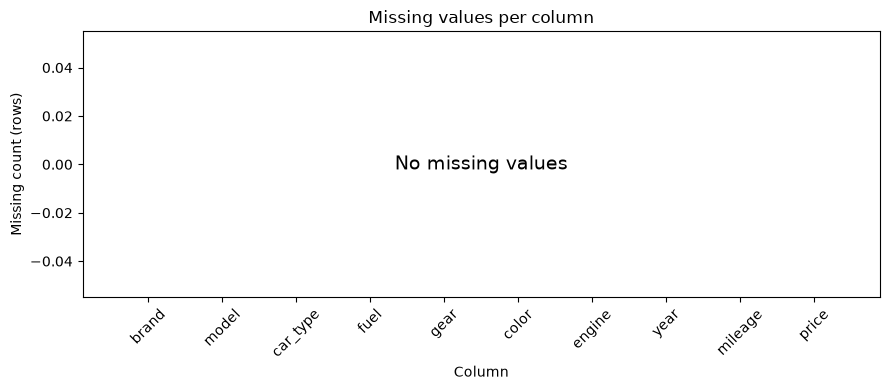

ไม่พบค่าว่าง


In [5]:
# [05] ตรวจคุณภาพ 1: ค่าว่าง
# ==================================================
# ทำอะไร: นับจำนวนและเปอร์เซ็นต์ของ "ค่าว่าง" (missing value, ช่องที่ไม่มีข้อมูล) ในทุกคอลัมน์ของ raw_df
#         แล้ววาดแท่งกราฟจำนวนค่าว่างต่อคอลัมน์
# ทำไม: ส่วนนี้ ([05]–[11]) คือการตรวจคุณภาพข้อมูลก่อนสร้างโมเดล เพราะหลัก "garbage in, garbage out"
#       คือถ้าข้อมูลเข้าไม่ดี (ว่าง ซ้ำ เป็นไปไม่ได้ กระจายแปลก) ต่อให้โมเดลดีแค่ไหน ผลลัพธ์ก็ไม่น่าเชื่อถือ
#       ค่าว่างต้องรู้ก่อนเสมอ เพราะถ้ามีอยู่ ต้องตัดสินใจว่าจะเติม ลบ หรือปล่อยไว้
#       ข้อตกลงของทั้งส่วนนี้:
#       1) ทุกเซลล์ตรวจบน raw_df ทั้งไฟล์ (ก่อนเตรียมข้อมูล) ซึ่งปลอดภัย เพราะไม่มีผลการตรวจใดถูกนำไปเลือก
#          อะไรให้โมเดลเลย (ไม่มี data leakage คือข้อมูลชุดทดสอบไม่รั่วไปมีอิทธิพลต่อการเลือกโมเดล)
#       2) ส่วนนี้ "รายงานอย่างเดียว" ไม่แก้ raw_df และไม่สร้างตัวแปรที่เซลล์อื่นต้องใช้
#          ถ้าพบปัญหา ผู้ใช้เป็นคนตัดสินใจทีหลังว่าจะทำอย่างไร ข้อมูลจึงไม่ถูกเปลี่ยนที่นี่
#          และผลของโมเดลไม่เปลี่ยน
#       3) ข้อสรุปท้ายแต่ละเซลล์ถูกคำนวณโดยโค้ด ไม่ได้พิมพ์ตายตัว
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อคอลัมน์ (10 แถว) บอกจำนวนค่าว่างและเปอร์เซ็นต์ กราฟแท่งจำนวนค่าว่างต่อคอลัมน์
#       ถ้าทุกแท่งเป็นศูนย์ บนกราฟจะมีข้อความ "No missing values" และบรรทัดสุดท้ายบอกว่าไม่พบค่าว่าง
#       ถ้ามีแท่งสูง แสดงว่าคอลัมน์นั้นมีข้อมูลหาย ควรหาสาเหตุก่อนไปต่อ
# ==================================================
print("=== [05] ตรวจคุณภาพ 1: ค่าว่าง ===")

missing_table = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": raw_df.isna().mean() * 100,
})

print("ตารางนี้บอกว่าแต่ละคอลัมน์มีค่าว่างกี่ช่อง และคิดเป็นกี่เปอร์เซ็นต์ของทุกแถว")
display(missing_table.style.format({
    "missing_count": "{:,.0f}",
    "missing_percent": "{:.2f}",
}))

total_missing = int(missing_table["missing_count"].sum())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missing_table.index, missing_table["missing_count"])
ax.set_title("Missing values per column")
ax.set_xlabel("Column")
ax.set_ylabel("Missing count (rows)")
ax.tick_params(axis="x", rotation=45)
if total_missing == 0:
    ax.text(0.5, 0.5, "No missing values", transform=ax.transAxes,
            ha="center", va="center", fontsize=14)
plt.tight_layout()
plt.show()

if total_missing == 0:
    print("ไม่พบค่าว่าง")
else:
    columns_with_missing = int((missing_table["missing_count"] > 0).sum())
    print(f"พบค่าว่างรวม {total_missing:,} ค่า ใน {columns_with_missing} คอลัมน์")

=== [06] ตรวจคุณภาพ 2: แถวซ้ำ ===
ตารางนี้บอกจำนวนแถวที่ซ้ำกับแถวก่อนหน้า ตามแต่ละนิยามของคำว่า 'ซ้ำ'


,duplicate_rows,percent_of_rows
all columns,0,0.00
all except price,"9,066",19.68
all except color,"1,238",2.69


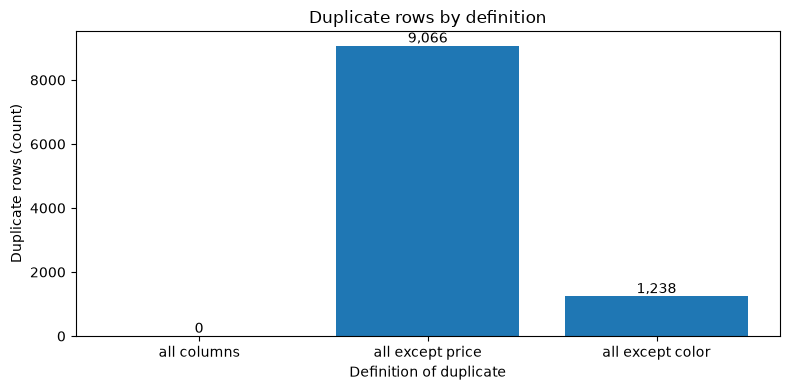

ไม่พบแถวที่ซ้ำกันทุกคอลัมน์
แถวที่ต่างกันแค่ price (ธงเตือน)   : 9,066 แถว
แถวที่ต่างกันแค่ color (รถคนละคัน) : 1,238 แถว


In [6]:
# [06] ตรวจคุณภาพ 2: แถวซ้ำ
# ==================================================
# ทำอะไร: นับแถวที่ "ซ้ำกับแถวก่อนหน้า" (ตัวสำเนาส่วนเกิน ไม่นับแถวแรกที่เจอ) ตาม 3 นิยาม
#         1) เหมือนกันทุกคอลัมน์
#         2) เหมือนกันทุกคอลัมน์ ยกเว้น price
#         3) เหมือนกันทุกคอลัมน์ ยกเว้น color
# ทำไม: กฎของโปรเจกต์นี้คือ "แถวที่ต่างกันในคอลัมน์ใดก็ตามที่ไม่ใช่ price ถือว่าเป็นรถคนละคัน"
#       ดังนั้น
#       - นิยาม 1 คือแถวซ้ำจริง ๆ (อาจเป็นข้อมูลที่ถูกบันทึกซ้ำ)
#       - นิยาม 2 คือแถวที่ทุกอย่างเหมือนกันหมดแต่ราคาต่างกัน ตามกฎอาจเป็นรถคันเดียวที่ถูกประกาศขายสองราคา
#         จึงเป็นธงเตือนคุณภาพ (quality flag) ไม่ใช่ข้อผิดพลาดที่ยืนยันแล้ว
#       - นิยาม 3 คือแถวที่ต่างกันแค่สี ตามกฎเป็นรถคนละคัน (สีต่างกัน) จึงไม่ใช่ข้อมูลซ้ำ
#         ข้อนี้เชื่อมกับหมายเหตุในเซลล์ [13] ที่อธิบายเรื่องการแบ่งข้อมูล
#       แถวซ้ำสำคัญเพราะถ้าแถวเดียวกันอยู่ทั้งชุดเทรนและชุดทดสอบ คะแนนทดสอบจะดีเกินจริง
#       เซลล์นี้รายงานอย่างเดียว ไม่ลบแถวใดเลย
# ผลที่ควรเห็น: ตารางสามแถว (นิยามละหนึ่งแถว) บอกจำนวนแถวซ้ำและเปอร์เซ็นต์ กราฟแท่งสามแท่งเขียนตัวเลขบนแท่ง
#       ตัวเลขนิยาม 2 และ 3 จะมากกว่าหรือเท่ากับนิยาม 1 เสมอ (เพราะเทียบน้อยคอลัมน์กว่า เจอซ้ำง่ายกว่า)
# ==================================================
print("=== [06] ตรวจคุณภาพ 2: แถวซ้ำ ===")

definitions = {
    "all columns": list(raw_df.columns),
    "all except price": [c for c in raw_df.columns if c != "price"],
    "all except color": [c for c in raw_df.columns if c != "color"],
}

duplicate_counts = {}
for name, columns in definitions.items():
    duplicate_counts[name] = int(raw_df.duplicated(subset=columns, keep="first").sum())

duplicate_table = pd.DataFrame({
    "duplicate_rows": pd.Series(duplicate_counts),
})
duplicate_table["percent_of_rows"] = duplicate_table["duplicate_rows"] / len(raw_df) * 100

print("ตารางนี้บอกจำนวนแถวที่ซ้ำกับแถวก่อนหน้า ตามแต่ละนิยามของคำว่า 'ซ้ำ'")
display(duplicate_table.style.format({
    "duplicate_rows": "{:,.0f}",
    "percent_of_rows": "{:.2f}",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(duplicate_table.index, duplicate_table["duplicate_rows"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Duplicate rows by definition")
ax.set_xlabel("Definition of duplicate")
ax.set_ylabel("Duplicate rows (count)")
plt.tight_layout()
plt.show()

if duplicate_counts["all columns"] == 0:
    print("ไม่พบแถวที่ซ้ำกันทุกคอลัมน์")
else:
    print(f"พบแถวซ้ำทุกคอลัมน์ {duplicate_counts['all columns']:,} แถว")
print(f"แถวที่ต่างกันแค่ price (ธงเตือน)   : {duplicate_counts['all except price']:,} แถว")
print(f"แถวที่ต่างกันแค่ color (รถคนละคัน) : {duplicate_counts['all except color']:,} แถว")

=== [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้ ===
ตารางนี้บอกว่าแต่ละกฎมีกี่แถวที่ฝ่าฝืน (ควรเป็น 0 ทุกกฎ)


,rows_violating
price <= 0,0
engine <= 0,0
mileage < 0,0
year > 2026,0


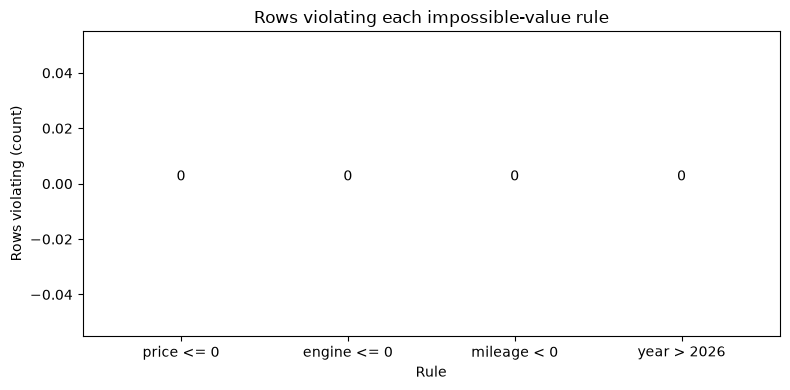

ไม่พบค่าที่เป็นไปไม่ได้


In [7]:
# [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้
# ==================================================
# ทำอะไร: นับแถวที่ฝ่าฝืนกฎ "ค่าที่เป็นไปไม่ได้ในโลกจริง" 4 ข้อ
#         1) price <= 0     ราคาขายต้องมากกว่า 0 บาท
#         2) engine <= 0    ขนาดเครื่องยนต์ (cc) ต้องมากกว่า 0
#         3) mileage < 0    เลขไมล์ติดลบไม่ได้ (ไมล์เป็น 0 ได้ เช่นรถใหม่)
#         4) year > CURRENT_YEAR   ปีของรถต้องไม่เกินปีปัจจุบัน (CURRENT_YEAR กำหนดในเซลล์ [03])
# ทำไม: ค่าที่เป็นไปไม่ได้แปลว่าข้อมูลผิดแน่นอน (เช่นกรอกผิดหรือระบบเก็บพลาด) ไม่เหมือนค่าที่แค่หายาก
#       ถ้ามีอยู่จะทำให้โมเดลเรียนรู้จากข้อมูลเท็จ ใช้เฉพาะกฎที่ตรรกะบังคับเท่านั้น
#       ไม่คิดเกณฑ์ที่ตั้งเองตามใจ เช่น "รถเก่าเกินไป" เพราะรถเก่ามากที่ราคาสูงก็มีจริง (รถคลาสสิก)
# ผลที่ควรเห็น: ตารางแต่ละกฎกับจำนวนแถวที่ฝ่าฝืน และกราฟแท่งของแต่ละกฎ
#       ถ้าทุกกฎเป็น 0 แปลว่าไม่พบค่าที่เป็นไปไม่ได้ ถ้าไม่ใช่ ควรดูแถวนั้นก่อนตัดสินใจว่าจะทำอย่างไร
#       (เซลล์นี้ไม่แก้และไม่ลบข้อมูล)
# ==================================================
print("=== [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้ ===")

impossible_counts = {
    "price <= 0": int((raw_df["price"] <= 0).sum()),
    "engine <= 0": int((raw_df["engine"] <= 0).sum()),
    "mileage < 0": int((raw_df["mileage"] < 0).sum()),
    f"year > {CURRENT_YEAR}": int((raw_df["year"] > CURRENT_YEAR).sum()),
}

impossible_table = pd.DataFrame({
    "rows_violating": pd.Series(impossible_counts),
})

print("ตารางนี้บอกว่าแต่ละกฎมีกี่แถวที่ฝ่าฝืน (ควรเป็น 0 ทุกกฎ)")
display(impossible_table.style.format({"rows_violating": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(impossible_table.index, impossible_table["rows_violating"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Rows violating each impossible-value rule")
ax.set_xlabel("Rule")
ax.set_ylabel("Rows violating (count)")
plt.tight_layout()
plt.show()

total_impossible = sum(impossible_counts.values())
if total_impossible == 0:
    print("ไม่พบค่าที่เป็นไปไม่ได้")
else:
    print(f"พบการฝ่าฝืนกฎรวม {total_impossible:,} ครั้ง (นับซ้ำได้ถ้าแถวเดียวฝ่าฝืนหลายกฎ)")

=== [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข ===
ตารางนี้สรุปสถิติของคอลัมน์ตัวเลข: count=จำนวนแถว, 25%/50%/75%=Q1/มัธยฐาน/Q3


,price,engine,mileage,year
count,"46,074","46,074","46,074","46,074"
mean,"555,577","1,922","115,309","2,019"
std,"328,567",513,"62,748",4
min,"60,000","1,000",300,"2,006"
25%,"339,000","1,500","67,500","2,017"
50%,"469,000","2,000","107,500","2,019"
75%,"689,000","2,400","157,500","2,022"
max,"2,000,000","3,500","300,000","2,026"


C:\Users\putaw\AppData\Local\Temp\ipykernel_22364\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_22364\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_22364\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_22364\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be re

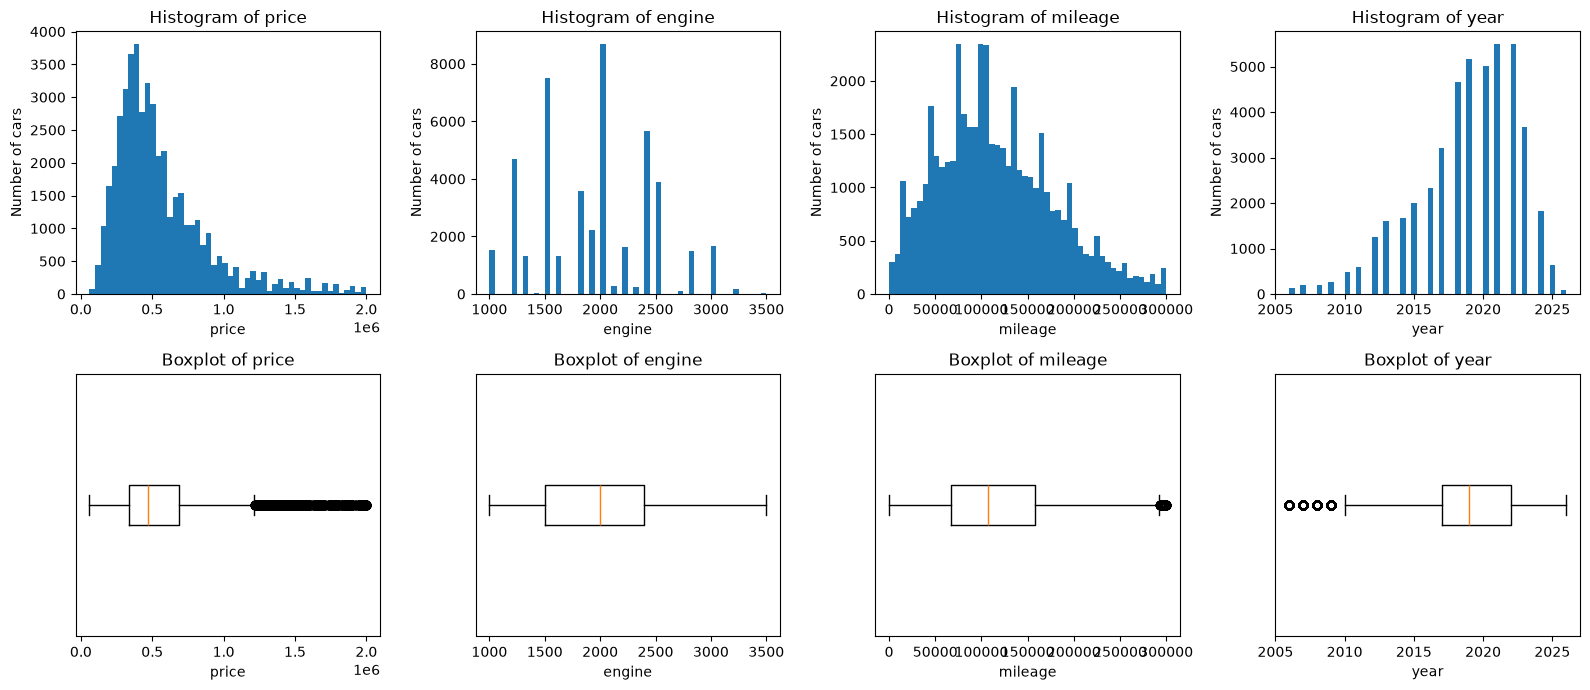

price   : ค่าความเบ้ +1.66 -> เบ้ขวาชัดเจน (หางยาวไปทางค่าสูง)
engine  : ค่าความเบ้ +0.19 -> ไม่เบ้มาก
mileage : ค่าความเบ้ +0.54 -> ไม่เบ้มาก
year    : ค่าความเบ้ -0.79 -> ไม่เบ้มาก


In [8]:
# [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข
# ==================================================
# ทำอะไร: สรุปสถิติ (describe) ของคอลัมน์ตัวเลข 4 ตัว (price, engine, mileage, year)
#         แล้ววาด histogram (แถวบน) และ boxplot (แถวล่าง) ของแต่ละตัว
# ทำไม: การดูรูปร่างการกระจายของข้อมูลช่วยให้เห็นสิ่งที่ตัวเลขสรุปไม่บอก เช่น ข้อมูลเบ้ หรือถูกตัดที่ค่าสูงสุด
# วิธีอ่านกราฟ (เป็นสิ่งที่ควรสังเกต ไม่ใช่ข้อเท็จจริงของการรันครั้งนี้):
#   - Histogram: แบ่งค่าเป็นช่วง (bins = 50 ช่วง) แท่งสูง = มีรถในช่วงราคา/ค่านั้นมาก
#   - Boxplot: กล่อง = ข้อมูลตรงกลาง 50% (จาก Q1 ถึง Q3), เส้นในกล่อง = มัธยฐาน (median คือค่ากลางเมื่อเรียงลำดับ),
#              หนวด (whiskers) = ช่วงที่ยังถือว่าปกติ, จุดนอกหนวด = ค่าที่ห่างมาก (outlier)
#   - ความเบ้ (skew): ถ้าหางยาวไปทางขวา (ส่วนใหญ่ค่าต่ำ มีบางคันแพงมาก) เรียกว่าเบ้ขวา ราคารถมักเป็นแบบนี้
#   - แท่งสูงผิดปกติที่ค่าสูงสุด: อาจหมายถึงข้อมูลถูกตัดเพดาน (capped) ตอนเก็บ เช่น ทุกคันที่แพงกว่าเพดานถูกบันทึกเป็นค่าเพดาน
# ผลที่ควรเห็น: ตารางสถิติ (จำนวน ค่าเฉลี่ย ส่วนเบี่ยงเบนมาตรฐาน ต่ำสุด quartile สูงสุด) และรูป 2 แถว 4 คอลัมน์
#       ตารางไม่ได้ถูกแก้ข้อมูลใด ๆ เซลล์นี้รายงานอย่างเดียว
# ==================================================
print("=== [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข ===")

numeric_check_columns = ["price", "engine", "mileage", "year"]

print("ตารางนี้สรุปสถิติของคอลัมน์ตัวเลข: count=จำนวนแถว, 25%/50%/75%=Q1/มัธยฐาน/Q3")
display(raw_df[numeric_check_columns].describe().style.format("{:,.0f}"))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for position, column in enumerate(numeric_check_columns):
    axes[0, position].hist(raw_df[column], bins=50)
    axes[0, position].set_title(f"Histogram of {column}")
    axes[0, position].set_xlabel(column)
    axes[0, position].set_ylabel("Number of cars")
    axes[1, position].boxplot(raw_df[column], vert=False)
    axes[1, position].set_title(f"Boxplot of {column}")
    axes[1, position].set_xlabel(column)
    axes[1, position].set_yticks([])
plt.tight_layout()
plt.show()

skewness = raw_df[numeric_check_columns].skew()
for column in numeric_check_columns:
    if skewness[column] > 1:
        shape = "เบ้ขวาชัดเจน (หางยาวไปทางค่าสูง)"
    elif skewness[column] < -1:
        shape = "เบ้ซ้ายชัดเจน (หางยาวไปทางค่าต่ำ)"
    else:
        shape = "ไม่เบ้มาก"
    print(f"{column:<8}: ค่าความเบ้ {skewness[column]:+.2f} -> {shape}")

=== [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR) ===
ตารางนี้บอกรั้วล่าง/บนของแต่ละคอลัมน์ และจำนวนแถวที่อยู่นอกรั้ว


column,q1,q3,iqr,lower_fence,upper_fence,below,above,outlier_percent,outliers
price,"339,000","689,000","350,000","-186,000","1,214,000",0,"2,461",5.34,"2,461"
engine,"1,500","2,400",900,150,"3,750",0,0,0.00,0
mileage,"67,500","157,500","90,000","-67,500","292,500",0,254,0.55,254
year,"2,017","2,022",5,"2,010","2,030",810,0,1.76,810


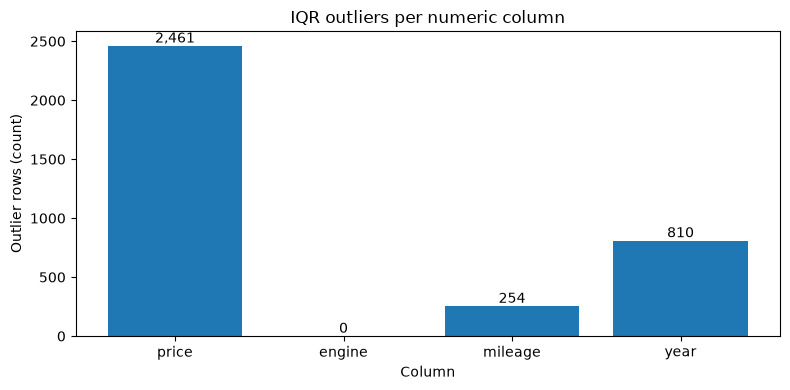

พบค่านอกรั้ว IQR รวม 3,525 ค่า (ไม่ได้ลบ เพราะอาจเป็นข้อมูลจริง)


In [9]:
# [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR)
# ==================================================
# ทำอะไร: หาค่าผิดปกติ (outlier คือค่าที่ห่างจากส่วนใหญ่มาก) ของคอลัมน์ตัวเลขแต่ละตัวด้วยกฎ IQR ของ Tukey
#         ขั้นตอน: หา Q1 (ค่าที่ 25% ของข้อมูลต่ำกว่า) และ Q3 (ค่าที่ 75%)
#                  IQR = Q3 - Q1 (ความกว้างของข้อมูลตรงกลาง 50%)
#                  รั้วล่าง = Q1 - 1.5 x IQR, รั้วบน = Q3 + 1.5 x IQR
#                  ค่าที่ต่ำกว่ารั้วล่างหรือสูงกว่ารั้วบนนับเป็น outlier
# ทำไม: 1.5 เป็นค่าที่ John Tukey เสนอไว้เป็นธรรมเนียมปฏิบัติ (convention) ไม่ใช่กฎธรรมชาติ
#       ต้องระวังว่า outlier ไม่ได้แปลว่าข้อมูลผิดเสมอไป รถแพงมากมีอยู่จริง จึงเป็นข้อมูลจริงที่ควรเก็บไว้
#       XGBoost ประกอบด้วยต้นไม้ตัดสินใจ (decision tree) หลายต้น แต่ละต้นแบ่งข้อมูลด้วยลำดับ (มากกว่า/น้อยกว่าเกณฑ์)
#       จึงไม่สนใจว่าค่าฟีเจอร์ที่สุดโต่งนั้นสุดโต่งแค่ไหน ค่าฟีเจอร์ที่สุดโต่งจึงกระทบโมเดลน้อย
#       (ต่างจากโมเดลเชิงเส้นที่ถูกลากง่าย) แต่ราคา (ค่าที่ทาย) ที่สุดโต่งยังมีผล เพราะ XGBoost ในโน้ตบุ๊คนี้
#       เรียนรู้จากความผิดพลาดยกกำลังสอง รถราคาสูงมากที่ทายพลาดจึงดึงต้นไม้ต้นถัดไปได้มากกว่าคันอื่น
#       เซลล์นี้ไม่ลบหรือแก้ค่าใดเลย รายงานอย่างเดียว
# ผลที่ควรเห็น: ตารางต่อคอลัมน์ (Q1, Q3, IQR, รั้วล่าง/บน, จำนวนที่ต่ำกว่า/สูงกว่า, เปอร์เซ็นต์ของแถวทั้งหมด)
#       และกราฟแท่งจำนวน outlier ต่อคอลัมน์ ถ้าแท่งสูงให้ดูว่าเป็นค่าจริงที่หายากหรือสัญญาณข้อมูลผิด
# ==================================================
print("=== [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR) ===")

numeric_check_columns = ["price", "engine", "mileage", "year"]

rows = []
for column in numeric_check_columns:
    q1 = raw_df[column].quantile(0.25)
    q3 = raw_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    below = int((raw_df[column] < lower_fence).sum())
    above = int((raw_df[column] > upper_fence).sum())
    rows.append({
        "column": column,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "below": below,
        "above": above,
        "outlier_percent": (below + above) / len(raw_df) * 100,
    })

outlier_table = pd.DataFrame(rows)
outlier_table["outliers"] = outlier_table["below"] + outlier_table["above"]

print("ตารางนี้บอกรั้วล่าง/บนของแต่ละคอลัมน์ และจำนวนแถวที่อยู่นอกรั้ว")
display(outlier_table.style.hide(axis="index").format({
    "q1": "{:,.0f}",
    "q3": "{:,.0f}",
    "iqr": "{:,.0f}",
    "lower_fence": "{:,.0f}",
    "upper_fence": "{:,.0f}",
    "below": "{:,.0f}",
    "above": "{:,.0f}",
    "outlier_percent": "{:.2f}",
    "outliers": "{:,.0f}",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(outlier_table["column"], outlier_table["outliers"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("IQR outliers per numeric column")
ax.set_xlabel("Column")
ax.set_ylabel("Outlier rows (count)")
plt.tight_layout()
plt.show()

total_outliers = int(outlier_table["outliers"].sum())
if total_outliers == 0:
    print("ไม่พบค่าผิดปกติตามกฎ IQR")
else:
    print(f"พบค่านอกรั้ว IQR รวม {total_outliers:,} ค่า (ไม่ได้ลบ เพราะอาจเป็นข้อมูลจริง)")

=== [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม ===
ตารางนี้บอกจำนวนระดับของแต่ละคอลัมน์กลุ่ม และระดับที่พบบ่อยที่สุดพร้อมสัดส่วน


column,levels,most_common,most_common_share_percent,smallest_level_rows
brand,20,TOYOTA,32.98,89
model,115,HILUX REVO,5.77,49
car_type,7,Sedan,29.29,"1,765"
fuel,3,Benzine,49.90,"5,281"
gear,2,Automatic,87.96,"5,548"
color,18,White,35.02,23


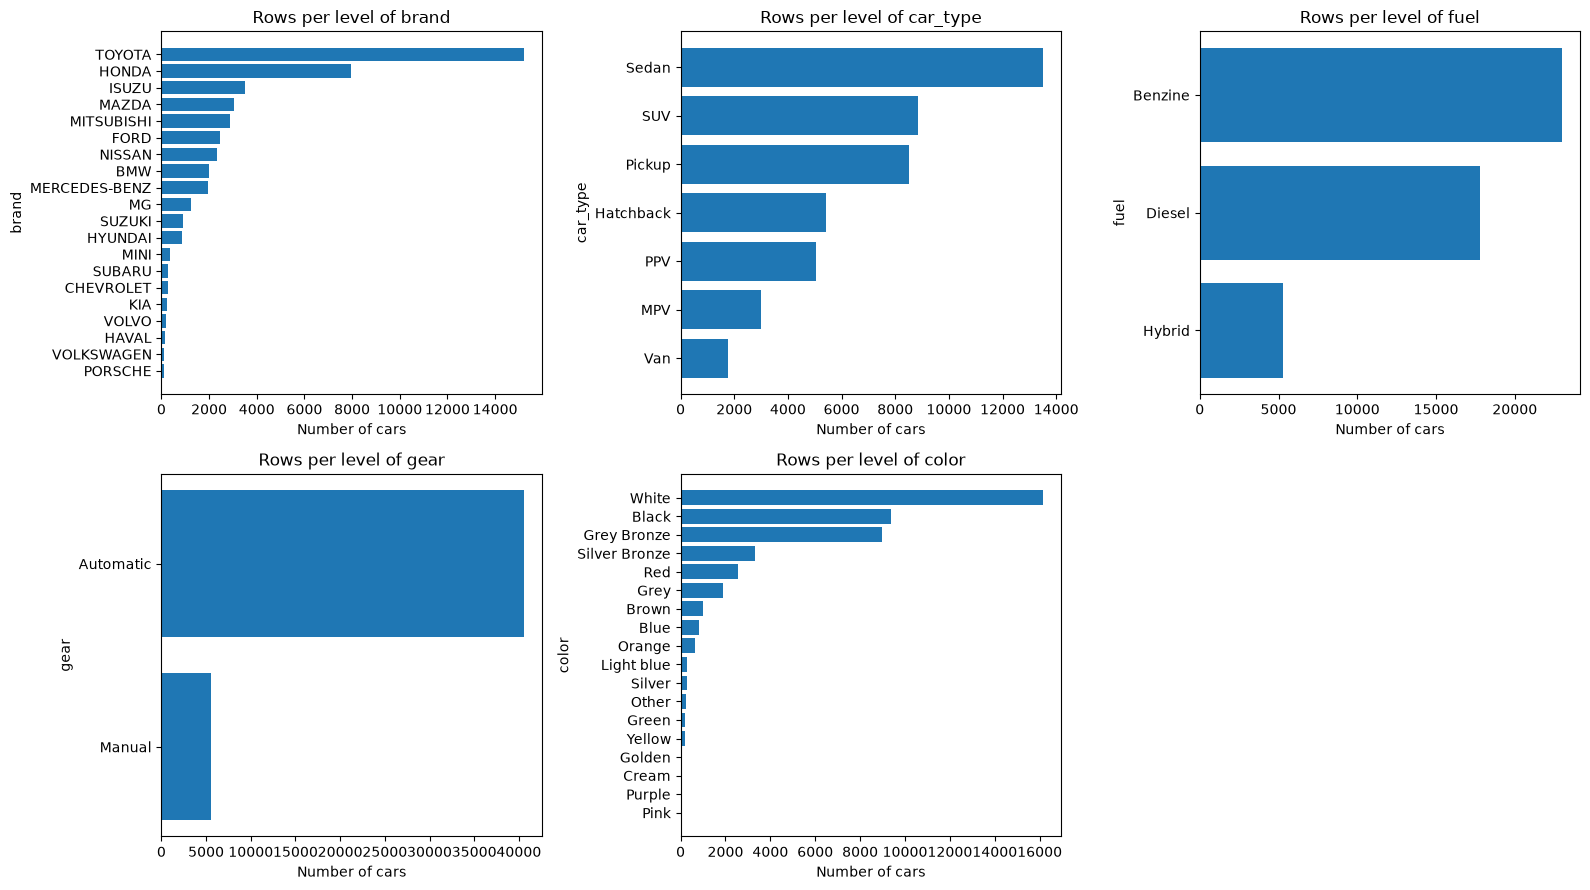

ระดับที่มีแถวน้อยที่สุดในทุกคอลัมน์กลุ่ม มี 23 แถว


In [10]:
# [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม
# ==================================================
# ทำอะไร: ดูคอลัมน์ที่เป็นกลุ่ม/ประเภท (categorical) 6 ตัว: brand, model, car_type, fuel, gear, color
#         นับจำนวนระดับ (level คือค่าที่แตกต่างกัน เช่น fuel มี เบนซิน/ดีเซล/...) ระดับที่พบบ่อยที่สุดและสัดส่วนของมัน
#         แล้ววาดแท่งแนวนอนจำนวนแถวต่อระดับ ของ brand, car_type, fuel, gear, color
# ทำไม: ระดับที่หายาก (rare level คือมีแถวน้อยมาก) สร้างปัญหาสองอย่าง
#       1) One-hot encoding (แปลงแต่ละระดับเป็นคอลัมน์ 0/1) จะได้คอลัมน์ที่เกือบทั้งหมดเป็น 0 และเรียนรู้อะไรไม่ได้มาก
#       2) การแบ่งข้อมูลและการแบ่งโหนดของต้นไม้ (XGBoost คือต้นไม้หลายต้น):
#          ถ้าระดับหนึ่งมีไม่กี่แถว อาจไม่มีตัวอย่างในชุดทดสอบ หรือต้นไม้
#          แบ่งตามระดับนั้นแล้วได้ใบ (leaf) เล็กจนไม่น่าเชื่อถือ
#       คอลัมน์ model มีหลายระดับเกินกว่าจะวาดเป็นกราฟแท่ง เซลล์ [11] ดูเรื่องนี้แยกต่างหาก
# ผลที่ควรเห็น: ตารางต่อคอลัมน์ (จำนวนระดับ ระดับที่พบมากสุด สัดส่วน) และรูป 2x3 ช่อง ใช้ 5 ช่อง
#       ช่องที่หกถูกลบทิ้ง ในกราฟ แท่งสั้นมาก ๆ คือระดับหายาก
# ==================================================
print("=== [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม ===")

categorical_check_columns = ["brand", "model", "car_type", "fuel", "gear", "color"]

rows = []
for column in categorical_check_columns:
    counts = raw_df[column].value_counts()
    rows.append({
        "column": column,
        "levels": len(counts),
        "most_common": counts.index[0],
        "most_common_share_percent": counts.iloc[0] / len(raw_df) * 100,
        "smallest_level_rows": counts.min(),
    })
level_table = pd.DataFrame(rows)

print("ตารางนี้บอกจำนวนระดับของแต่ละคอลัมน์กลุ่ม และระดับที่พบบ่อยที่สุดพร้อมสัดส่วน")
display(level_table.style.hide(axis="index").format({
    "levels": "{:,.0f}",
    "most_common_share_percent": "{:.2f}",
    "smallest_level_rows": "{:,.0f}",
}))

plot_columns = ["brand", "car_type", "fuel", "gear", "color"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
flat_axes = axes.flatten()
for position, column in enumerate(plot_columns):
    counts = raw_df[column].value_counts().sort_values()
    flat_axes[position].barh(counts.index.astype(str), counts.to_numpy())
    flat_axes[position].set_title(f"Rows per level of {column}")
    flat_axes[position].set_xlabel("Number of cars")
    flat_axes[position].set_ylabel(column)
fig.delaxes(flat_axes[5])
plt.tight_layout()
plt.show()

smallest_level_rows = level_table["smallest_level_rows"].min()
print(f"ระดับที่มีแถวน้อยที่สุดในทุกคอลัมน์กลุ่ม มี {smallest_level_rows:,} แถว")

=== [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น ===
จำนวนรุ่น (brand|model) : 115
แถวต่อรุ่น ต่ำสุด       : 49
แถวต่อรุ่น มัธยฐาน      : 190
แถวต่อรุ่น สูงสุด       : 2,658
ตารางนี้แสดง 10 รุ่นที่มีแถวน้อยที่สุด


brand,model,rows
VOLVO,XC90,49
VOLVO,XC40,51
MERCEDES-BENZ,S300,52
MG,VS HEV,52
TOYOTA,PRIUS,52
NISSAN,SYLPHY,53
CHEVROLET,TRAILBLAZER,54
MERCEDES-BENZ,E250,58
HAVAL,JOLION,61
TOYOTA,HARRIER,66


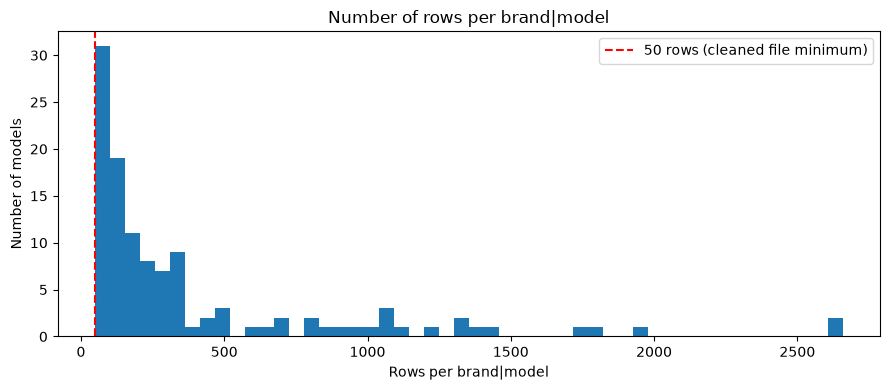

พบรุ่นที่มีแถวน้อยกว่า 50: 1 รุ่น


In [11]:
# [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น
# ==================================================
# ทำอะไร: นับจำนวนแถวต่อรุ่นรถ (หนึ่งรุ่น = หนึ่งคู่ brand + model) แล้วแสดงค่าต่ำสุด มัธยฐาน สูงสุด
#         ตาราง 10 รุ่นที่มีแถวน้อยที่สุด และ histogram ของจำนวนแถวต่อรุ่น
#         มีเส้นประแนวตั้งที่ 50 แถว (จำนวนขั้นต่ำต่อรุ่นของไฟล์สะอาด)
# ทำไม: ไฟล์ merge_50min_clean.csv มี 47,001 แถว 115 รุ่น และทุกรุ่นยังมีอย่างน้อย 50 แถว
#       จำนวนแถวต่อรุ่นสำคัญ เพราะเซลล์ [13] แบ่งข้อมูลแบบ stratified (แบ่งโดยรักษาสัดส่วนของแต่ละรุ่น)
#       คือเอา 80/10/10 ของ "แต่ละรุ่น" ไปไว้ใน train/validation/test
#       ถ้ารุ่นหนึ่งมีแถวน้อย ชุดทดสอบจะได้แถวของรุ่นนั้นน้อยมาก (เช่น 50 แถว x 10% = 5 แถว)
#       ผลการวัดของรุ่นนั้นจึงไม่นิ่ง การตรวจนี้จึงยืนยันว่าเงื่อนไขขั้นต่ำ 50 แถวเป็นจริง
# ผลที่ควรเห็น: ค่า min/median/max, ตาราง 10 รุ่นที่เล็กที่สุด, histogram (หางขวายาวเป็นปกติ
#       เพราะรุ่นยอดนิยมมีแถวมาก) ถ้าค่าต่ำสุดน้อยกว่า 50 แสดงว่าไฟล์ไม่ผ่านเงื่อนไขขั้นต่ำต่อรุ่น ซึ่งบรรทัดสุดท้ายจะรายงานให้
# ==================================================
print("=== [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น ===")

rows_per_model = raw_df.groupby(["brand", "model"]).size()

print(f"จำนวนรุ่น (brand|model) : {len(rows_per_model):,}")
print(f"แถวต่อรุ่น ต่ำสุด       : {rows_per_model.min():,.0f}")
print(f"แถวต่อรุ่น มัธยฐาน      : {rows_per_model.median():,.0f}")
print(f"แถวต่อรุ่น สูงสุด       : {rows_per_model.max():,.0f}")

smallest_models = rows_per_model.sort_values().head(10).rename("rows").reset_index()
print("ตารางนี้แสดง 10 รุ่นที่มีแถวน้อยที่สุด")
display(smallest_models.style.hide(axis="index").format({"rows": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(rows_per_model, bins=50)
ax.axvline(50, color="red", linestyle="--", label="50 rows (cleaned file minimum)")
ax.set_title("Number of rows per brand|model")
ax.set_xlabel("Rows per brand|model")
ax.set_ylabel("Number of models")
ax.legend()
plt.tight_layout()
plt.show()

if rows_per_model.min() >= 50:
    print("ทุกรุ่นมีอย่างน้อย 50 แถว ตรงกับเงื่อนไขของไฟล์ merge_50min_clean.csv")
else:
    print(f"พบรุ่นที่มีแถวน้อยกว่า 50: {int((rows_per_model < 50).sum()):,} รุ่น")

In [12]:
# [12] เตรียมข้อมูล: car_age และตัดคอลัมน์
# ==================================================
# ทำอะไร: ทำสำเนาของ raw_df เป็น df แล้ว
#         (1) สร้างคอลัมน์ car_age = CURRENT_YEAR - year (อายุรถเป็นปี)
#         (2) ตัดคอลัมน์ year และ color ทิ้ง
#         (3) ตรวจว่าคอลัมน์ที่ใช้ทั้งหมดไม่มีค่าว่าง
# ทำไม:
#   - ตัด year เพราะ car_age บอกข้อมูลเดียวกันอยู่แล้ว (ปีที่ผลิตมากขึ้น = อายุน้อยลง)
#     เก็บไว้ทั้งสองจะซ้ำซ้อน
#   - ตัด color เพราะเป็นการตัดสินใจของโปรเจกต์ที่จะไม่ใช้สีเป็น feature
#     (ผลของการตัดนี้ต่อแถวที่ค่าเหมือนกันข้ามชุด อธิบายไว้ในเซลล์ [13])
#   - สร้าง df จาก raw_df.copy() ทุกครั้ง เพื่อให้รันเซลล์นี้ซ้ำได้ ไม่แก้ raw_df
#     ถ้าแก้ df ตรงๆ รอบที่สองจะไม่มีคอลัมน์ year ให้คำนวณแล้ว
#   - ไม่เปลี่ยนชื่อคอลัมน์ engine, fuel, gear เป็น engine_capacity, fuel_type, gear_type
#     ที่ต้นฉบับทำ เพราะผู้ใช้สั่งให้ใช้ชื่อตามไฟล์ข้อมูล การเปลี่ยนชื่อไม่มีผลกับตัวเลขของโมเดล
#     (ทดสอบแล้วได้ R² เท่าเดิมทุกหลัก) ต่างกันแค่ชื่อที่แสดงใน features และ RESULT_JSON
#     ถ้าจะเทียบกับไฟล์โมเดล V4 เดิม (V4_*_min50.json) ต้องจับคู่ชื่อเอง
# ผลที่ควรเห็น: ขนาดตาราง df และรายชื่อคอลัมน์ (ต้องไม่มี year และ color แต่มี car_age)
# ==================================================
print("=== [12] เตรียมข้อมูล: car_age และตัดคอลัมน์ ===")

df = raw_df.copy()
df["car_age"] = CURRENT_YEAR - df["year"]
df = df.drop(columns=["year", "color"])
assert df[NUM_COLS + CAT_COLS + ["price"]].notna().all().all()

print(f"ขนาดตาราง df : {df.shape[0]:,} แถว x {df.shape[1]:,} คอลัมน์")
print(f"คอลัมน์      : {list(df.columns)}")

=== [12] เตรียมข้อมูล: car_age และตัดคอลัมน์ ===
ขนาดตาราง df : 46,074 แถว x 9 คอลัมน์
คอลัมน์      : ['brand', 'model', 'car_type', 'fuel', 'gear', 'engine', 'mileage', 'price', 'car_age']


In [13]:
# [13] แบ่ง train / validation / test
# ==================================================
# ทำอะไร: แบ่ง df เป็น train 80% / validation 10% / test 10% โดยแบ่งทีละรุ่นรถ (stratify)
# ทำไม:
#   - ทำไมแบ่งสามชุด: train สอนโมเดล, validation กันไว้ตรวจผลอีกชุด (การเลือกพารามิเตอร์ใช้ CV บน train),
#     test ตัดสินผลสุดท้ายครั้งเดียว (ดูอภิธานศัพท์ในเซลล์ [01])
#   - ทำไมต้อง stratify: แบ่งทีละรุ่น ไม่ใช่สุ่มรวมทั้งก้อน
#     ตัวอย่าง: HONDA|CR-V มี 100 แถว จะได้ train 80, validation 10, test 10
#               TOYOTA|Camry มี 60 แถว จะได้ train 48, validation 6, test 6
#     ทำให้ทุกรุ่นอยู่ครบทั้ง 3 ชุดในสัดส่วนเดียวกัน ผล test จึงสะท้อนข้อมูลทั้งชุด
#     ถ้าสุ่มเฉยๆ รุ่นที่มีน้อยอาจไปกองอยู่ใน test หรือไม่มีใน test เลย
#   - ทำไมป้ายกลุ่ม (model_key) มียี่ห้อด้วย: เป็นรูปแบบ "ยี่ห้อ|รุ่น" เช่น "HONDA|CR-V"
#     เพราะรุ่นชื่อเดียวกันจากต่างยี่ห้อต้องไม่ถูกนับเป็นกลุ่มเดียวกัน
#     และ stratify รับป้ายได้คอลัมน์เดียว ป้ายนี้ใช้แค่ตอนแบ่งข้อมูล
#     ไม่ได้เพิ่มเข้าตาราง และโมเดลไม่เคยเห็น
#   - แบ่งสองรอบ: รอบแรกแยก train 80% ส่วนที่เหลือ 20% เก็บใน temp
#     รอบสองแบ่ง temp ครึ่งต่อครึ่ง (0.1 / 0.2 = 0.5) ได้ validation 10% และ test 10%
#   - random_state=SEED ทำให้แบ่งกี่ครั้งก็ได้ชุดเดิม
# ผลที่ควรเห็น: ตารางสรุปแต่ละชุด ได้แก่ จำนวนแถว สัดส่วนต่อทั้งหมด และจำนวนรุ่น (ยี่ห้อ|รุ่น)
#       ที่ไม่ซ้ำ จำนวนรุ่นของ validation และ test ควรใกล้เคียงกัน เพราะแบ่งแบบ stratify
# ข้อควรระวัง: แถวที่ค่าเหมือนกันข้ามชุด
#   หลังตัด color อาจมีแถวใน test หรือ validation ที่ค่าทุกคอลัมน์ที่ใช้
#   (รวมราคา) ตรงกับแถวใน train แม้ก่อนตัดสีจะเป็นคนละแถวกัน
#   จำนวนแถวลักษณะนี้ขึ้นกับไฟล์สะอาดและการแบ่งชุด ไม่ใช้จำนวนจากการรันเดิม
#   ดูจำนวนแถวของแต่ละชุดจากตารางที่คำนวณด้านล่าง
#   ตามกติกาของโปรเจกต์ ถ้าสองแถวไม่เหมือนกันทุกคอลัมน์ (นอกจากราคา)
#   ถือเป็นรถคนละคัน เช่น แถวที่ต่างกันเฉพาะสีอาจมีสเปกและราคาเหมือนกัน
#   เซลล์ [06] ตรวจแถวซ้ำตามนิยามต่าง ๆ โดยไม่ลบแถว
# ==================================================
print("=== [13] แบ่ง train / validation / test ===")

model_key = df["brand"] + "|" + df["model"]

# รอบแรก: แยก train 80% ที่เหลือ 20% เก็บใน temp
train, temp = train_test_split(df, train_size=TRAIN_SIZE, stratify=model_key, random_state=SEED)

# รอบสอง: แบ่ง temp ครึ่งต่อครึ่ง ได้ validation และ test
val, test = train_test_split(
    temp,
    test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
    stratify=model_key.loc[temp.index],
    random_state=SEED,
)

split_table = pd.DataFrame({
    "ชุด": ["train", "validation", "test"],
    "แถว": [len(train), len(val), len(test)],
    "สัดส่วน (%)": [100 * len(part) / len(df) for part in (train, val, test)],
    "จำนวนรุ่น": [model_key.loc[part.index].nunique() for part in (train, val, test)],
})
print("อ่านตาราง: แต่ละชุดมีกี่แถว คิดเป็นกี่ % ของทั้งหมด และมีกี่รุ่น (ยี่ห้อ|รุ่น) ที่ไม่ซ้ำ")
display(
    split_table.style
    .format({"แถว": "{:,.0f}", "สัดส่วน (%)": "{:.2f}", "จำนวนรุ่น": "{:,.0f}"})
    .hide(axis="index")
)

=== [13] แบ่ง train / validation / test ===


อ่านตาราง: แต่ละชุดมีกี่แถว คิดเป็นกี่ % ของทั้งหมด และมีกี่รุ่น (ยี่ห้อ|รุ่น) ที่ไม่ซ้ำ


ชุด,แถว,สัดส่วน (%),จำนวนรุ่น
train,"36,859",80.00,115
validation,"4,607",10.00,115
test,"4,608",10.00,115


In [14]:
# [14] สร้าง 5 fold
# ==================================================
# ทำอะไร: แบ่งชุด train เป็น N_FOLDS ส่วน (fold) ด้วย KFold เก็บเป็นรายการ folds
#         แต่ละสมาชิกคือคู่ (แถวที่ใช้สอน, แถวที่ใช้ตรวจ)
# ทำไม:
#   - K-fold cross-validation: แบ่ง train เป็น K ส่วนเท่าๆ กัน แล้วผลัดกันเอา 1 ส่วนเป็นชุดตรวจ
#     อีก K-1 ส่วนเป็นชุดสอน ทำ K รอบ แล้วเฉลี่ยคะแนน ได้ค่าที่เชื่อถือกว่าการตรวจรอบเดียว
#     และไม่ต้องแตะ validation / test
#   - สร้าง folds ครั้งเดียวแล้วให้ทุกขั้นตอนถัดไปใช้ร่วมกัน ทุกการเปรียบเทียบจึงใช้แถวชุดเดียวกัน
#     ผลต่างที่เห็นมาจากตัวเลือกที่เทียบจริง ไม่ใช่จากการแบ่ง fold ที่ต่างกัน
#   - shuffle=True สลับลำดับแถวก่อนแบ่ง เพราะข้อมูลอาจเรียงตามยี่ห้อหรือราคา
#     การแบ่งตามลำดับจะทำให้ fold ไม่เป็นตัวแทนของทั้งชุด
#     และใช้ random_state=SEED ให้สลับแล้วได้ผลเดิมทุกครั้ง
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อ fold บอกจำนวนแถวที่ใช้สอนและแถวที่ใช้ตรวจ
#       ผลรวมสองคอลัมน์ในแต่ละแถวเท่ากับจำนวนแถวของ train
# ข้อควรระวัง: validation และ test ไม่ถูกใช้จนถึงขั้นวัดผลสุดท้าย
# ==================================================
print("=== [14] สร้าง 5 fold ===")

folds = list(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(train))

fold_rows = []
for fold_number, (train_index, valid_index) in enumerate(folds, start=1):
    fold_rows.append({
        "fold": fold_number,
        "แถวสำหรับสอน": len(train_index),
        "แถวสำหรับตรวจ": len(valid_index),
    })
fold_table = pd.DataFrame(fold_rows)
print("อ่านตาราง: แต่ละ fold ใช้กี่แถวสอนและกี่แถวตรวจ (ทุก fold ใช้ train ชุดเดียวกัน)")
display(
    fold_table.style
    .format({"fold": "{:.0f}", "แถวสำหรับสอน": "{:,.0f}", "แถวสำหรับตรวจ": "{:,.0f}"})
    .hide(axis="index")
)

=== [14] สร้าง 5 fold ===
อ่านตาราง: แต่ละ fold ใช้กี่แถวสอนและกี่แถวตรวจ (ทุก fold ใช้ train ชุดเดียวกัน)


fold,แถวสำหรับสอน,แถวสำหรับตรวจ
1,"29,487","7,372"
2,"29,487","7,372"
3,"29,487","7,372"
4,"29,487","7,372"
5,"29,488","7,371"


In [15]:
# [15] ฟังก์ชันวัดความสัมพันธ์
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน 2 ตัวไว้วัดว่าตัวแปร 2 ตัว "สัมพันธ์กัน" มากแค่ไหน
#   - cramers_v(x, y)              : ใช้กับตัวแปรหมวดหมู่ 2 ตัว (เช่น brand กับ model)
#   - correlation_ratio(cats, vals): ใช้กับตัวแปรหมวดหมู่ 1 ตัว กับตัวเลข 1 ตัว (เช่น brand กับ price)
#   ส่วนตัวเลขกับตัวเลขใช้ Spearman ของ pandas ได้เลย ไม่ต้องสร้างฟังก์ชันเอง
# ทำไม: ข้อมูลรถมีทั้งตัวเลข (engine, mileage, car_age, price) และหมวดหมู่ (brand, model,
#   car_type, fuel, gear) การวัดแบบเดียวไม่เหมาะกับทุกคู่
#   เช่น ค่าสหสัมพันธ์ปกติ (Pearson) ใช้กับ "brand" ไม่ได้เพราะ brand ไม่ใช่ตัวเลข
#   จึงต้องเลือกตัววัดให้ตรงกับชนิดของตัวแปรแต่ละคู่:
#     1) ตัวเลข-ตัวเลข   : Spearman  = สหสัมพันธ์แบบเรียงอันดับ (rank) ค่าจริง -1..1
#                          เซลล์ [16] ใช้ค่าสัมบูรณ์ เพื่อให้อยู่สเกล 0..1 เหมือนตัววัดอื่น
#     2) หมวดหมู่-หมวดหมู่ : Cramér's V = ปรับจากค่าไคสแควร์ (chi-square) ของตารางไขว้
#                          ให้อยู่ในช่วง 0..1
#     3) หมวดหมู่-ตัวเลข  : η (อีตา, correlation ratio)
#                          = รากของ (ความแปรปรวนระหว่างกลุ่ม / ความแปรปรวนรวม)
#                          บอกว่าค่าเฉลี่ยของแต่ละหมวด อธิบายความผันผวนของตัวเลขได้กี่ส่วน
#   ทั้งสามตัววัดตีความเหมือนกัน: 0 = ไม่สัมพันธ์กันเลย, 1 = สัมพันธ์กันสมบูรณ์
#   (รู้ค่าของตัวหนึ่งก็บอกอีกตัวได้แน่นอน)
# ผลที่ควรเห็น: พิมพ์ข้อความว่าสร้างฟังก์ชันแล้ว และผ่านการเช็กตัวเอง (assert) 2 ข้อ
# ข้อควรระวัง: สามตัววัดไม่ได้อยู่บนสเกลเดียวกันเป๊ะ ๆ จึงเทียบค่าข้ามชนิดได้แค่คร่าว ๆ
#   เซลล์นี้ใช้ train เท่านั้น (เช็กตัวเองกับ train) ไม่แตะ val และ test
# ==================================================
print("=== [15] ฟังก์ชันวัดความสัมพันธ์ ===")


def cramers_v(x, y):
    """Cramér's V ของตัวแปรหมวดหมู่ 2 ตัว (Series): 0 = ไม่สัมพันธ์, 1 = สัมพันธ์สมบูรณ์"""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    smaller_side = min(table.shape[0], table.shape[1])
    return np.sqrt(chi2 / (n * (smaller_side - 1)))


def correlation_ratio(categories, values):
    """η ของตัวแปรหมวดหมู่ (Series) กับตัวเลข (Series): 0 = ไม่สัมพันธ์, 1 = สัมพันธ์สมบูรณ์"""
    group_means = values.groupby(categories).transform("mean")
    overall_mean = values.mean()
    between_group = ((group_means - overall_mean) ** 2).sum()
    total = ((values - overall_mean) ** 2).sum()
    return np.sqrt(between_group / total)


# เช็กตัวเอง: ตัวแปรเทียบกับตัวมันเอง ต้องได้ 1
assert abs(cramers_v(train["brand"], train["brand"]) - 1) < 1e-9

# ค่าที่ขึ้นกับ fuel อย่างเดียว (เลขรหัสของแต่ละชนิดเชื้อเพลิง) ต้องได้ η = 1
fuel_codes = {level: code for code, level in enumerate(train["fuel"].unique())}
values_from_fuel = train["fuel"].map(fuel_codes)
assert abs(correlation_ratio(train["fuel"], values_from_fuel) - 1) < 1e-9

print("สร้างฟังก์ชัน cramers_v และ correlation_ratio แล้ว")
print("เช็กตัวเองผ่าน: brand กับ brand ได้ 1 และ fuel กับค่าที่ขึ้นกับ fuel อย่างเดียวได้ 1")

=== [15] ฟังก์ชันวัดความสัมพันธ์ ===
สร้างฟังก์ชัน cramers_v และ correlation_ratio แล้ว
เช็กตัวเองผ่าน: brand กับ brand ได้ 1 และ fuel กับค่าที่ขึ้นกับ fuel อย่างเดียวได้ 1


=== [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9) ===


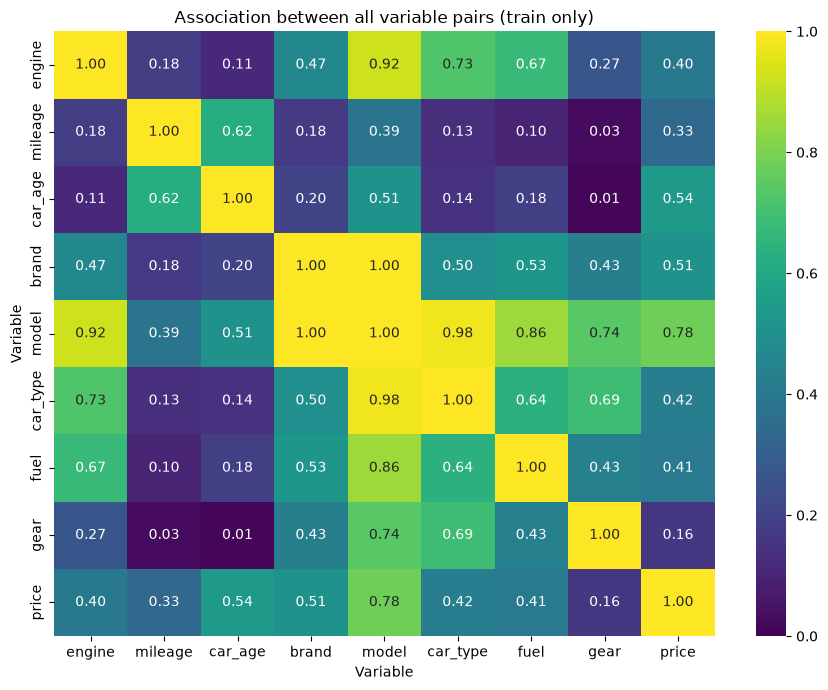

ตารางทั้ง 36 คู่ เรียงจากสัมพันธ์มากที่สุดไปน้อยที่สุด (value 0 = ไม่สัมพันธ์, 1 = สมบูรณ์)


variable 1,variable 2,method,value
brand,model,Cramér's V,1.0000
model,car_type,Cramér's V,0.9801
engine,model,η,0.9222
model,fuel,Cramér's V,0.8555
model,price,η,0.7787
model,gear,Cramér's V,0.7417
engine,car_type,η,0.7254
car_type,gear,Cramér's V,0.6911
engine,fuel,η,0.6743
car_type,fuel,Cramér's V,0.6405


In [16]:
# [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9)
# ==================================================
# ทำอะไร: วัดความสัมพันธ์ของตัวแปรทุกคู่ใน train (9 ตัว = 8 ฟีเจอร์ที่โมเดลใช้ + price
#   ซึ่งเป็นค่าที่จะทำนาย ได้ 36 คู่) แล้วสรุปเป็นตาราง 9x9 (association_matrix)
#   วาดเป็น heatmap (แผนที่สี) และพิมพ์ตาราง 36 คู่เรียงจากสัมพันธ์มากไปน้อย
#   วิธีวัดเลือกตามชนิดของคู่ (อธิบายไว้ที่เซลล์ [15]):
#     ตัวเลข-ตัวเลข   -> |Spearman| (ค่าสัมบูรณ์ ตัดเครื่องหมายทิ้งให้อยู่ช่วง 0..1)
#     หมวดหมู่-หมวดหมู่ -> Cramér's V
#     หมวดหมู่-ตัวเลข  -> η (correlation ratio)
#   เส้นทแยงมุมเป็น 1 เสมอ (ตัวแปรเทียบกับตัวเอง) แต่ละคู่คำนวณครั้งเดียวแล้วเติมทั้ง 2 ฝั่ง
# ทำไม: ก่อนสร้างโมเดล ควรรู้ว่าฟีเจอร์ไหนเกี่ยวข้องกับ price มาก และฟีเจอร์ไหนซ้ำซ้อนกันเอง
#   ใช้ train เท่านั้น เพราะ val และ test ต้องเป็นข้อมูลที่ไม่เคยเห็น
#   ถ้าเอาไปคำนวณด้วย จะเท่ากับแอบดูคำตอบก่อนวัดผล (data leakage)
# ผลที่ควรเห็น: heatmap 9x9 ยิ่งสีสว่าง (ใกล้ 1) ยิ่งสัมพันธ์กันมาก แล้วตาราง 36 คู่
#   วิธีอ่าน:
#     - แถวหรือคอลัมน์ของ price บอกว่าฟีเจอร์ไหนสัมพันธ์กับราคามากที่สุด
#     - คู่ model กับ brand จะใกล้ 1 เป็นเรื่องปกติ เพราะรุ่นหนึ่งสังกัดยี่ห้อเดียว
#       ไม่ใช่ข้อมูลผิดพลาด
#     - ฟีเจอร์สองตัวสัมพันธ์กันสูง ไม่ได้ทำให้โมเดลต้นไม้อย่าง XGBoost ทำนายแย่ลง
#       แต่ทำให้บอกยากว่าฟีเจอร์ไหน "สำคัญ" จริง เพราะทั้งคู่ให้ข้อมูลซ้ำกัน
#     - ความสัมพันธ์ไม่ใช่เหตุและผล (association is not causation)
#       เช่น รถอายุมากราคาต่ำ ไม่ได้แปลว่าอายุเป็นตัวกำหนดราคาเพียงอย่างเดียว
# ข้อควรระวัง: ตัววัด 3 ชนิดไม่ได้อยู่บนสเกลเดียวกันเป๊ะ ๆ
#   จึงเทียบค่าข้ามชนิดได้แค่คร่าว ๆ เทียบในชนิดเดียวกันแม่นกว่า
# ==================================================
print("=== [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9) ===")

variables = NUM_COLS + CAT_COLS + ["price"]
numeric_variables = NUM_COLS + ["price"]

association_matrix = pd.DataFrame(np.eye(len(variables)), index=variables, columns=variables)
pair_rows = []
for i in range(len(variables)):
    for j in range(i + 1, len(variables)):
        first = variables[i]
        second = variables[j]
        first_is_numeric = first in numeric_variables
        second_is_numeric = second in numeric_variables
        if first_is_numeric and second_is_numeric:
            method = "Spearman"
            value = abs(train[first].corr(train[second], method="spearman"))
        elif not first_is_numeric and not second_is_numeric:
            method = "Cramér's V"
            value = cramers_v(train[first], train[second])
        elif first_is_numeric:
            method = "η"
            value = correlation_ratio(train[second], train[first])
        else:
            method = "η"
            value = correlation_ratio(train[first], train[second])
        association_matrix.loc[first, second] = value
        association_matrix.loc[second, first] = value
        pair_rows.append(
            {"variable 1": first, "variable 2": second, "method": method, "value": value}
        )

plt.figure(figsize=(9, 7))
sns.heatmap(association_matrix, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="viridis")
plt.title("Association between all variable pairs (train only)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

pair_table = pd.DataFrame(pair_rows).sort_values("value", ascending=False)
print("ตารางทั้ง 36 คู่ เรียงจากสัมพันธ์มากที่สุดไปน้อยที่สุด (value 0 = ไม่สัมพันธ์, 1 = สมบูรณ์)")
display(pair_table.style.format({"value": "{:.4f}"}).hide(axis="index"))

=== [17] Spearman ของตัวแปรตัวเลข ===


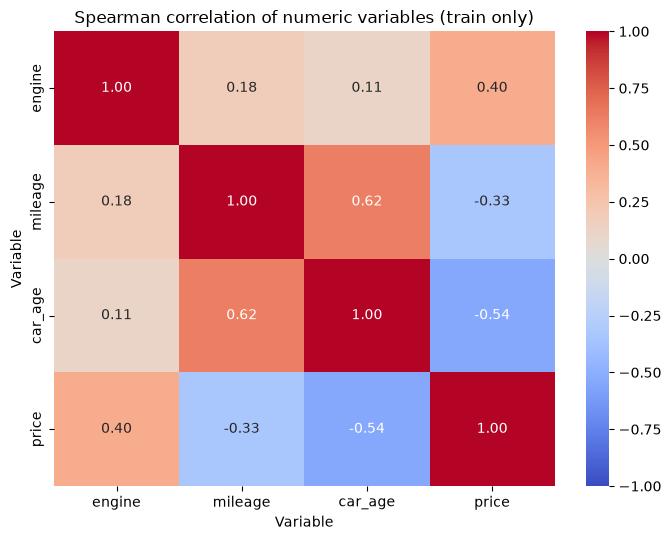

ตาราง Spearman (บวก = ไปทางเดียวกัน, ลบ = สวนทางกัน, ใกล้ 0 = ไม่มีแนวโน้มชัด)


,engine,mileage,car_age,price
engine,1.0000,0.1790,0.1121,0.4044
mileage,0.1790,1.0000,0.6183,-0.3337
car_age,0.1121,0.6183,1.0000,-0.5422
price,0.4044,-0.3337,-0.5422,1.0000


In [17]:
# [17] Spearman ของตัวแปรตัวเลข
# ==================================================
# ทำอะไร: คำนวณ Spearman ของตัวแปรตัวเลข 4 ตัว (engine, mileage, car_age, price) ใน train
#   แล้ววาด heatmap และแสดงตาราง ต่างจากเซลล์ [16] ตรงที่เก็บเครื่องหมายบวก/ลบไว้ (ช่วง -1..1)
# ทำไม: เครื่องหมายบอกทิศทางที่เซลล์ [16] (ใช้ค่าสัมบูรณ์) มองไม่เห็น
#   Spearman คือสหสัมพันธ์ของ "อันดับ" (rank) ของข้อมูล ไม่ใช่ค่าจริง จึงเลือกใช้แทน Pearson เพราะ
#     - ทนต่อค่าผิดปกติ (outlier) เช่น รถราคาสูงมากไม่กี่คัน Pearson จะถูกดึงไปมาก
#     - จับความสัมพันธ์ที่ไม่เป็นเส้นตรงแต่ไปทางเดียวกันได้ (monotonic)
#       เช่น ราคาลดลงเรื่อย ๆ เมื่อเลขไมล์เพิ่ม แม้ไม่ลดเป็นเส้นตรง
# ผลที่ควรเห็น: heatmap สีแดง-น้ำเงิน (coolwarm) พร้อมตัวเลขในช่อง แล้วตารางตัวเลขชุดเดียวกัน
#   วิธีอ่านเครื่องหมาย:
#     - บวก (สีแดง) = สองตัวนี้เพิ่มไปด้วยกัน
#     - ลบ (สีน้ำเงิน) = ตัวหนึ่งเพิ่มขณะที่อีกตัวลด
#     - ใกล้ 0 (สีขาว) = ไม่มีแนวโน้มทางเดียวกันชัดเจน
#   สิ่งที่ควรดู: (1) แถว price ว่าตัวไหนสัมพันธ์กับราคามากและทิศทางใด
#   (2) ฟีเจอร์ตัวเลขสองตัวที่สัมพันธ์กันเองสูง (เช่น car_age กับ mileage มักไปด้วยกัน)
#   ซึ่งหมายความว่าให้ข้อมูลซ้ำกันบางส่วน ควรเทียบกับผลในเซลล์ [16]
# ข้อควรระวัง: สัมพันธ์ไม่ใช่เหตุและผล และใช้ train เท่านั้นเหมือนเซลล์ [16]
# ==================================================
print("=== [17] Spearman ของตัวแปรตัวเลข ===")

spearman_table = train[NUM_COLS + ["price"]].corr(method="spearman")

plt.figure(figsize=(7, 5.5))
sns.heatmap(spearman_table, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Spearman correlation of numeric variables (train only)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

print("ตาราง Spearman (บวก = ไปทางเดียวกัน, ลบ = สวนทางกัน, ใกล้ 0 = ไม่มีแนวโน้มชัด)")
display(spearman_table.style.format("{:.4f}"))

In [18]:
# [18] รายชื่อฟีเจอร์
# ==================================================
# ทำอะไร: ประกาศตัวแปร features = รายชื่อคอลัมน์ทั้งหมดที่จะป้อนให้โมเดลใช้ทายราคา
#         "ฟีเจอร์ (feature)" คือคอลัมน์ข้อมูลที่โมเดลใช้เป็นเบาะแสในการทาย
#         เช่น ปีรถ เลขไมล์ ยี่ห้อ ส่วน "ราคา" คือคำตอบที่โมเดลต้องทาย จึงไม่นับเป็นฟีเจอร์
#         ในที่นี้ใช้ NUM_COLS (ตัวเลข: engine, mileage, car_age) รวมกับ CAT_COLS
#         (หมวดหมู่: brand, model, car_type, fuel, gear) จากเซลล์ [03] รวม 8 ตัว
# ทำไม: เวอร์ชันนี้ตัดขั้น "คัดเลือกฟีเจอร์" ออกแล้ว ใช้ทุกตัวเลย เหตุผลคือ
#         1) ในโน้ตบุ๊ค Decision Tree (v4_DT) ขั้นคัดเลือกเดิม (วัด CV MAE กับ permutation importance,
#            backward elimination และตรวจคอลัมน์ตัวเลขซ้ำ) เก็บฟีเจอร์ไว้ครบ 8 ตัวอยู่แล้ว
#            และไม่พบคู่คอลัมน์ซ้ำ โน้ตบุ๊คนี้จึงใช้ฟีเจอร์ชุดเดียวกันตามการตัดสินใจเดียวกัน
#            และไม่ต้องฝึกโมเดลซ้ำหลายรอบ ประหยัดเวลารัน
#            (ยังไม่ได้ทดสอบว่าขั้นคัดเลือกเดิมเมื่อใช้กับ XGBoost จะตัดฟีเจอร์ตัวใดหรือไม่)
#         2) การไม่คัดเลือก ไม่ได้พิสูจน์ว่าทุกฟีเจอร์ช่วยเสมอ ต้นไม้ใน XGBoost อาจเลือกใช้
#            ฟีเจอร์ที่ไม่มีประโยชน์เพราะความบังเอิญในข้อมูล ทำให้ทายข้อมูลใหม่แย่ลงได้
#            (เรียกว่า generalisation แย่ลง) แม้เราจะคุมความซับซ้อนด้วย max_depth,
#            min_child_weight, reg_lambda และจำนวนรอบ (n_estimators) อยู่แล้วก็ตาม
# ผลที่ควรเห็น: บรรทัดบอกจำนวนฟีเจอร์ และรายชื่อฟีเจอร์ทั้งหมด
#               คอลัมน์ตัวเลขมาก่อน แล้วตามด้วยหมวดหมู่
# ข้อควรระวัง: กติกานี้ต่างจากโน้ตบุ๊ค v4_XGB ต้นฉบับที่ยังมีขั้นคัดเลือกฟีเจอร์อยู่
#              ต้องคำนึงถึงความต่างนี้ตอนเปรียบเทียบผลกับโน้ตบุ๊คนั้น
# ==================================================
print("=== [18] รายชื่อฟีเจอร์ ===")

features = NUM_COLS + CAT_COLS

print(f"จำนวนฟีเจอร์ : {len(features)}")
print(f"รายชื่อ      : {features}")

=== [18] รายชื่อฟีเจอร์ ===
จำนวนฟีเจอร์ : 8
รายชื่อ      : ['engine', 'mileage', 'car_age', 'brand', 'model', 'car_type', 'fuel', 'gear']


In [19]:
# [19] คลาส FoldOneHot
# ==================================================
# ทำอะไร: สร้างตัวแปลงข้อมูล (คลาส FoldOneHot) ที่เปลี่ยนคอลัมน์หมวดหมู่ให้เป็นตัวเลข 0/1
#         ด้วยวิธี one-hot encoding แล้วต่อกับคอลัมน์ตัวเลขเดิม
#
#         one-hot คืออะไร: XGBoost ในโน้ตบุ๊คนี้รับได้แต่ตัวเลข แต่ fuel เป็นข้อความ
#         (XGBoost มีโหมดรับข้อมูลกลุ่มโดยตรง แต่ไม่ได้ใช้ เพื่อให้เข้ารหัสเหมือนโน้ตบุ๊ค DT)
#         เราจึงแตกเป็นคอลัมน์ใหม่ที่ตอบแค่ "ใช่ (1) หรือ ไม่ใช่ (0)" ต่อหนึ่งค่า
#         ตัวอย่าง fuel มี 3 ค่า Benzine / Diesel / Hybrid จะได้ 2 คอลัมน์:
#                          fuel=Diesel   fuel=Hybrid
#             รถดีเซล:          1             0
#             รถไฮบริด:        0             1
#             รถเบนซิน:        0             0      <- ศูนย์ทั้งคู่ = ค่าอ้างอิง
#
# ทำไม:
#   - ทิ้ง 1 ค่า (ระดับอ้างอิง หรือ reference level): ค่าที่เจอบ่อยที่สุดในข้อมูลฝึกจะไม่มีคอลัมน์
#     ของตัวเอง เพราะรู้ได้จากการที่คอลัมน์อื่นเป็น 0 หมด ถ้าเก็บครบทุกค่า คอลัมน์จะซ้ำซ้อนกัน
#     ถ้าความถี่เท่ากัน จะเรียงตามชื่อระดับจากน้อยไปมาก เพื่อให้ผลเหมือนเดิมทุกครั้ง
#   - เรียนรู้ (fit) ใน "แต่ละ fold": fold คือการแบ่งข้อมูลฝึกเป็นส่วนย่อย ๆ เพื่อสลับกันเป็น
#     ชุดฝึกและชุดตรวจ (cross-validation) รายชื่อระดับของแต่ละ fold จึงมาจากแถวฝึกของ fold นั้นเท่านั้น
#     ไม่แอบดูแถวที่ใช้ตรวจ ข้อมูลจึงไม่รั่ว (information leak) ผล CV จึงเชื่อถือได้
#   - ระดับที่ไม่เคยเจอตอนฝึก (unseen level) จะได้ศูนย์ทุกคอลัมน์ ไม่ทำให้โปรแกรมพัง
#   - __init__ ต้องเก็บ argument ทั้งสองตัวไว้ตามเดิมโดยไม่แก้ เพราะ sklearn ต้องสร้างสำเนาของ
#     ตัวแปลง (clone) ในทุก fold โดยอ่านค่าเหล่านี้กลับไป
#   - ในเมธอด transform ใช้การเทียบแบบ broadcasting: ดึงค่าของคอลัมน์ออกมาเป็นแนวตั้ง
#     (values[:, None]) แล้วเทียบ "ทุกแถวกับทุกระดับพร้อมกัน" ในคำสั่งเดียว
#     ได้ตารางจริง/เท็จขนาด (จำนวนแถว x จำนวนระดับ) แล้วแปลงเป็น 1/0
#     วิธีนี้เร็วกว่าวนทีละระดับมาก ซึ่งสำคัญเพราะการค้นหาฝึก 300 ครั้ง และแต่ละครั้ง
#     เรียก transform 2 ครั้ง (แถวฝึก และแถวตรวจของ fold)
# ผลที่ควรเห็น: ข้อความสั้น ๆ ว่าสร้างคลาสแล้ว ยังไม่มีการแปลงข้อมูลในเซลล์นี้
#               เซลล์ที่เรียกใช้จริงคือ fit_one_fold ใน [22] (รันขนานใน [26]), pipeline ที่ refit ใน [26] และเซลล์ [38]
# ข้อควรระวัง: ผู้เรียกใช้เขียน FoldOneHot(NUM_COLS, CAT_COLS)
# ==================================================
print("=== [19] คลาส FoldOneHot ===")


class FoldOneHot(TransformerMixin, BaseEstimator):
    """one-hot ที่เรียนรู้ระดับจากแถวที่ fit เท่านั้น (ไม่แอบดูแถวตรวจ)"""

    def __init__(self, numeric_columns, categorical_columns):
        # เก็บไว้ตามเดิมโดยไม่แก้ เพื่อให้ sklearn clone ได้
        self.numeric_columns = numeric_columns
        self.categorical_columns = categorical_columns

    def fit(self, X, y=None):
        """จำรายชื่อคอลัมน์ และระดับ (ไม่รวมระดับอ้างอิง) ของแต่ละคอลัมน์หมวดหมู่"""
        self.numeric_ = [c for c in X.columns if c in self.numeric_columns]
        self.categorical_ = [c for c in X.columns if c in self.categorical_columns]
        self.levels_ = {}
        for col in self.categorical_:
            counts = X[col].value_counts()
            # เรียงชื่อก่อน แล้วเรียงตามความถี่แบบ stable ชื่อจึงตัดสินเมื่อความถี่เท่ากัน
            ordered = counts.sort_index().sort_values(ascending=False, kind="stable")
            self.levels_[col] = list(ordered.index[1:])  # ตัดระดับที่พบบ่อยที่สุด = ระดับอ้างอิง
        return self

    def transform(self, X):
        """แปลงด้วยระดับที่จำไว้ตอน fit (ไม่เรียนรู้เพิ่ม)"""
        parts = [X[self.numeric_].astype(float)]
        for col in self.categorical_:
            levels = self.levels_[col]
            values = X[col].to_numpy(dtype=object)
            # เทียบทุกแถวกับทุกระดับพร้อมกัน ได้ตาราง True/False ระดับที่ไม่เคยเจอจะเป็น False หมด
            matches = values[:, None] == np.asarray(levels, dtype=object)
            dummies = pd.DataFrame(
                matches.astype(float),
                index=X.index,
                columns=[f"{col}={level}" for level in levels],
            )
            parts.append(dummies)
        return pd.concat(parts, axis=1)

    def get_feature_names_out(self, input_features=None):
        """รายชื่อคอลัมน์ผลลัพธ์ตามลำดับเดียวกับ transform"""
        names = list(self.numeric_)
        for col in self.categorical_:
            names += [f"{col}={level}" for level in self.levels_[col]]
        return np.asarray(names, dtype=object)


print("สร้างคลาส FoldOneHot แล้ว")

=== [19] คลาส FoldOneHot ===
สร้างคลาส FoldOneHot แล้ว


In [20]:
# [20] ฟังก์ชัน make_model
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน make_model() ที่คืนโมเดล XGBoost (XGBRegressor) ตัวใหม่
#         พร้อมค่า hyperparameter ที่มีผลต่อโมเดลนี้ เขียนไว้ครบทุกตัวที่สำคัญ
#         hyperparameter = ค่าที่เราต้องตั้งเองก่อนให้โมเดลเรียน (โมเดลไม่ได้เรียนรู้ค่าพวกนี้จากข้อมูล)
#         ส่วนสิ่งที่โมเดลเรียนเองจากข้อมูลคือเงื่อนไขแตกกิ่งและค่าในใบของต้นไม้ทุกต้น
# ทำไม:
#   - XGBoost มีค่าตั้งหลายสิบตัว ที่นี่เขียน 19 ตัวที่มีผลกับโมเดลนี้ พร้อมคอมเมนต์ทุกตัว
#     ไม่ว่าจะปรับใน grid หรือไม่ เพราะผู้ใช้ต้องการเห็นค่าที่โมเดลใช้จริง ตัวที่ไม่ได้เขียน
#     ใช้ค่าเริ่มต้นของ XGBoost และไม่เกี่ยวกับงานนี้ (เช่น ตัวเลือกของข้อมูลแบบ categorical หรือ GPU)
#   - ตัวที่มีป้าย [grid] (max_depth, min_child_weight, reg_lambda) ตัวค้นหาเขียนทับด้วยค่าใน PARAM_GRID
#     (เซลล์ [21]) ค่าที่เขียนในฟังก์ชันเป็นค่าตั้งต้น (ใช้กับโมเดลทดลองในเซลล์ [22])
#   - ตัวที่มีป้าย [search] (n_estimators, early_stopping_rounds) เป็นค่าตั้งต้นเช่นกัน ค่าจริงถูกตั้งโดยตัวค้นหา:
#     ตอนหาจำนวนรอบ (เซลล์ [22]) n_estimators = MAX_ROUNDS และ early_stopping_rounds = EARLY_STOPPING_ROUNDS
#     ตอน refit ผู้ชนะ (เซลล์ [26]) n_estimators = จำนวนรอบของผู้ชนะ และ early_stopping_rounds = None
#   - learning_rate คงที่ = LEARNING_RATE (เซลล์ [03]) แล้วให้ early stopping หาจำนวนรอบ (n_estimators) แทน
#     เพราะสองค่านี้แลกกันได้: learning rate เล็กลงครึ่งหนึ่งต้องใช้รอบประมาณสองเท่า
#     การปรับทั้งคู่พร้อมกันจึงเปลืองเวลาโดยได้ผลใกล้เดิม (เหตุผลของค่า 0.1 อยู่ที่เซลล์ [03])
#   - subsample และ colsample_bytree คงที่ 0.8 (ค่าเดียวกับโน้ตบุ๊ค v4_XGB ต้นฉบับ และอยู่ในช่วง
#     0.5-1 ที่เอกสาร XGBoost และแนวปฏิบัติทั่วไปแนะนำ) การสุ่มให้แต่ละต้นเห็นแถว 80% และคอลัมน์ 80%
#     ทำให้ต้นไม้แต่ละต้นต่างกันเล็กน้อย ลดการจำข้อมูล ยังไม่ได้ทดสอบค่าอื่น
#   - objective="reg:squarederror" (ค่าเริ่มต้น) คือเรียนรู้โดยลดความผิดพลาดยกกำลังสอง
#     ยังไม่ได้ทดสอบ objective อื่น เช่น "reg:absoluteerror" ที่ตรงกับ MAE มากกว่า
#   - early stopping (early_stopping_rounds) ต้องดูคะแนนจากชุดตรวจ จึงใช้เฉพาะแถวตรวจของแต่ละ fold ใน train
#     (เซลล์ [22]) ไม่ใช้ validation หรือ test เพราะจะเท่ากับเลือกจำนวนรอบจากข้อมูลที่ต้องกันไว้
#     ค่าในฟังก์ชันนี้จึงเป็น None (ไม่หยุดก่อน) ส่วน refit และเซลล์อื่นฝึกครบ n_estimators รอบ
#   - random_state=SEED ทำให้ผลซ้ำได้ (การสุ่มแถว/คอลัมน์ได้ชุดเดิมทุกครั้ง)
#   - n_jobs=MODEL_THREADS: ผลของ XGBoost เปลี่ยนเล็กน้อยตามจำนวน thread (ลำดับการบวกเลขทศนิยม
#     ในแต่ละ thread ต่างกัน) จึงใช้ค่าเดียวกันทั้งโน้ตบุ๊ค จำนวน thread เท่าเดิม = ผลเดิมทุกครั้ง
#     (pilot 2026-10-23: ฝึกซ้ำ 2 ครั้งด้วย thread เท่ากันได้คำทำนายเท่ากันทุกตัว)
# ผลที่ควรเห็น: ข้อความสั้น ๆ ว่าสร้างฟังก์ชันแล้ว ยังไม่ฝึกโมเดลในเซลล์นี้
# ข้อควรระวัง: make_model() ไม่รับ argument
# ==================================================
print("=== [20] ฟังก์ชัน make_model ===")


def make_model():
    """สร้าง XGBRegressor ใหม่พร้อม hyperparameter ที่ใช้ในโน้ตบุ๊คนี้"""
    return XGBRegressor(
        objective="reg:squarederror",  # เรียนรู้จากความผิดพลาดยกกำลังสอง (ค่าเริ่มต้น)
        n_estimators=100,  # [search] จำนวนรอบ = จำนวนต้นไม้ (1 ต้นต่อรอบ) ค่านี้เป็นค่าตั้งต้น ตัวค้นหาตั้งค่าจริง
        learning_rate=LEARNING_RATE,  # ย่อขนาดการแก้ของแต่ละต้น (คงที่ ดูเซลล์ [03])
        max_depth=6,  # [grid] ความลึกสูงสุดของต้นไม้แต่ละต้น
        min_child_weight=1,  # [grid] น้ำหนักขั้นต่ำต่อใบ ที่นี่ = จำนวนรถขั้นต่ำต่อใบ
        reg_lambda=1.0,  # [grid] บทลงโทษ L2 ที่ดึงค่าในใบเข้าหาศูนย์ (ยิ่งมากยิ่งระวัง)
        reg_alpha=0.0,  # บทลงโทษ L1 ของค่าในใบ 0 = ไม่ใช้ (ค่าเริ่มต้น)
        gamma=0.0,  # error ต้องลดอย่างน้อยเท่านี้จึงแตกกิ่ง 0 = ไม่บังคับ (ค่าเริ่มต้น)
        max_delta_step=0.0,  # จำกัดขนาดค่าในใบ 0 = ไม่จำกัด (ค่าเริ่มต้น)
        subsample=0.8,  # แต่ละต้นสุ่มเห็นแถว 80% ของข้อมูลฝึก
        colsample_bytree=0.8,  # แต่ละต้นสุ่มเห็นคอลัมน์ 80%
        tree_method="hist",  # แบ่งค่าเป็นช่วง (histogram) ก่อนหาจุดตัด เร็วกว่าวิธี exact มาก
        max_bin=256,  # จำนวนช่วงต่อคอลัมน์ของ hist (ค่าเริ่มต้น)
        grow_policy="depthwise",  # โตทีละชั้นจนถึง max_depth (ค่าเริ่มต้น)
        booster="gbtree",  # ใช้ต้นไม้เป็นตัวเรียนรู้ย่อย (ค่าเริ่มต้น)
        eval_metric="mae",  # ใช้ตอนส่ง eval_set: เป็นตัวชี้วัดของ early stopping (เซลล์ [22]) และกราฟรายรอบ (เซลล์ [38])
        early_stopping_rounds=None,  # [search] ค่าตั้งต้น = ไม่หยุดก่อน (เซลล์ [22] ตั้งเป็น EARLY_STOPPING_ROUNDS)
        random_state=SEED,  # เลขสุ่มคงที่ ให้ผลซ้ำได้
        n_jobs=MODEL_THREADS,  # จำนวน thread ภายในโมเดล (คงที่ทั้งโน้ตบุ๊ค)
    )


print("สร้างฟังก์ชัน make_model แล้ว")

=== [20] ฟังก์ชัน make_model ===
สร้างฟังก์ชัน make_model แล้ว


In [21]:
# [21] PARAM_GRID
# ==================================================
# ทำอะไร: กำหนด PARAM_GRID = ตารางค่าที่การค้นหาจะลองครบทุกคู่
#         grid search = วิธีค้นหาค่า hyperparameter ที่ดี โดยลองทุกชุดผสมของค่าที่เราเตรียมไว้
#         ฝึกและวัดผลด้วย cross-validation ทีละชุด แล้วเลือกชุดที่ CV MAE (ค่าเฉลี่ยข้าม fold) ต่ำสุด
#         ปรับ 3 พารามิเตอร์: 5 x 3 x 4 = 60 ชุด (x 5 fold = 300 ครั้งที่ฝึก)
#         "จำนวนรอบ" ไม่อยู่ใน grid แล้ว: แต่ละการฝึกหาจำนวนรอบเองด้วย early stopping (เซลล์ [22])
# ทำไม: ค่าทั้งหมดเลือกจากการทดลองนำร่อง (pilot) บน train ก่อนเปลี่ยนมาใช้ไฟล์สะอาด (2026-10-23, fold 1-2 ครบทุก
#   ค่าที่สำรวจ และครบ 5 fold สำหรับชุดที่ดีที่สุด) หลักการคือ grid ต้อง "คร่อม" ค่าที่ดีที่สุด
#   คือมีค่าที่แย่ลงทั้งสองฝั่ง (เซลล์ [28] ตรวจให้อัตโนมัติ) และต้องรันจบในเวลาที่รับได้
#   ตัวเลขในวงเล็บด้านล่างเป็นผล pilot ครั้งนั้น (จำนวนรอบคงที่ ไม่ใช้ early stopping) ไม่ใช่ผลของการรันครั้งนี้
#
#   | พารามิเตอร์      | ต้นฉบับ v4_XGB | ตอนนี้                  | ค่าเริ่มต้นของ XGBoost |
#   |------------------|----------------|-------------------------|------------------------|
#   | max_depth        | 6, 8           | 8, 12, 16, 20, 24       | 6                      |
#   | min_child_weight | 5, 20          | 1, 5, 20                | 1                      |
#   | reg_lambda       | 1, 10          | 0, 1, 10, 100           | 1                      |
#   | จำนวนรอบ         | 600, 1500      | early stopping (สูงสุด MAX_ROUNDS, เซลล์ [03]) | 100 |
#   | learning_rate    | 0.03 (คงที่)   | 0.1 (คงที่ เซลล์ [03])  | 0.3                    |
#
#   เหตุผลของแต่ละ grid
#   - max_depth (ความลึกสูงสุดของต้นไม้แต่ละต้น): ค่าที่นิยมทั่วไปคือ 3-10 แต่ข้อมูลนี้มีรุ่นรถหลายระดับ
#     ที่ถูกแตกเป็นคอลัมน์ 0/1 ต้นไม้ต้องใช้หลายชั้นกว่าจะแยกรุ่นแล้วแยกต่อด้วยอายุและเลขไมล์ได้
#     ต้นไม้ลึกจึงทายได้ดีกว่าที่นี่ pilot: CV MAE ดีขึ้นจากความลึก 4 ไปจนถึง 16-20 แล้วความลึก 24
#     แย่ลงเล็กน้อย (ประมาณ 100-300 บาทที่จำนวนรอบเท่ากัน) ส่วนความลึก 8 แย่กว่าชัดเจนภายใน 300 รอบ
#     จึงลองทุก 4 ชั้นจาก 8 ถึง 24 ให้ 8 และ 24 เป็นขอบที่คร่อมช่วงที่ดีที่สุดไว้
#   - min_child_weight: กับความผิดพลาดยกกำลังสอง ทุกแถวมีน้ำหนัก (hessian) = 1 ค่านี้จึงเท่ากับ
#     "จำนวนรถขั้นต่ำต่อใบ" ใบใหญ่ขึ้น = ต้นไม้เรียบขึ้นและมีใบน้อยลง
#     1 = ค่าเริ่มต้น และเป็นขอบธรรมชาติ (น้อยกว่านี้ไม่มีความหมาย) 5 = ปานกลาง 20 = แรง
#     pilot: 1 กับ 5 ใกล้กัน ส่วน 20 แย่กว่าประมาณ 600-900 บาท จึงเป็นขอบบนที่คร่อมไว้
#   - reg_lambda (บทลงโทษ L2): ดึงค่าในใบเข้าหาศูนย์ ใบที่มีรถน้อยถูกดึงมาก ทำให้ต้นไม้ลึกไม่จำ
#     รถไม่กี่คันมากเกินไป และเรียนได้หลายรอบขึ้นก่อนเริ่ม overfit
#     ลองเป็นขั้นละ 10 เท่า (นิยมกับค่าบทลงโทษ เพราะผลเปลี่ยนตามสัดส่วน ไม่ใช่ตามผลต่าง)
#     0 = ไม่มีบทลงโทษ (ขอบธรรมชาติ) 1 = ค่าเริ่มต้น pilot: 10 ดีที่สุดกับต้นไม้ลึก
#     0 แย่ชัดเจนกับต้นไม้ลึก และ 100 แย่กว่าประมาณ 300 บาทขึ้นไปภายใน 300 รอบ
#   - จำนวนรอบ (จำนวนต้นไม้): ไม่ใส่ใน grid แต่ใช้ early stopping (หยุดก่อน) ซึ่งเป็นวิธีมาตรฐานของ boosting
#     อธิบายแบบง่าย: ระหว่างฝึก ดู MAE บนแถวตรวจของ fold ทุกรอบ ถ้า MAE ไม่ดีขึ้นต่อเนื่อง
#     EARLY_STOPPING_ROUNDS (50) รอบ ก็หยุด แล้วถือว่าจำนวนรอบที่ดีที่สุดคือรอบที่ MAE ต่ำสุด
#     (ตั้งเพดานไว้ที่ MAX_ROUNDS = 1000 เผื่อต้นไม้ตื้นที่ pilot พบว่าอยากได้รอบมากกว่า 300)
#     ข้อดี: แต่ละชุดพารามิเตอร์ได้จำนวนรอบที่เหมาะกับตัวเอง ไม่ต้องเดาขั้น 25/50/100/200/300 เอง
#     และไม่ฝึกเกินจำเป็น จำนวนรอบของชุดหนึ่ง = ค่าเฉลี่ยของรอบที่ดีที่สุดของ 5 fold (ปัดเป็นจำนวนเต็ม)
#   - ไม่ลองค่าระหว่างกลาง (เช่น reg_lambda 30 หรือความลึก 18) เพื่อคุมเวลารัน pilot พบว่าบริเวณ
#     ที่ดีที่สุดค่อนข้างแบน ค่าระหว่างกลางต่างกันไม่เกินความแกว่งของ CV
# ผลที่ควรเห็น: แสดง grid และจำนวนชุดที่ผสมได้ (60 ชุด)
# ข้อควรระวัง: ผู้ชนะคือชุดที่ CV MAE ต่ำสุด (เซลล์ [23]) ไม่มีกฎอื่นมาแทรก
#              แถวแรกของตารางอันดับในเซลล์ [27] และ [32] จึงเป็นผู้ชนะเสมอ
#              ข้อจำกัด: แถวตรวจของแต่ละ fold ใช้ตัดสินว่าหยุดที่รอบไหน และใช้ให้คะแนนด้วย
#              CV MAE จึงดีเกินจริงเล็กน้อย ตัวตรวจอิสระคือ test และ validation ที่ยังไม่แตะ ([30], [40])
# ==================================================
print("=== [21] PARAM_GRID ===")

PARAM_GRID = {
    "max_depth": [8, 12, 16, 20, 24],
    "min_child_weight": [1, 5, 20],
    "reg_lambda": [0.0, 1.0, 10.0, 100.0],
}

combinations = 1
for values in PARAM_GRID.values():
    combinations = combinations * len(values)

for name, values in PARAM_GRID.items():
    print(f"{name:<17}: {values}")
print(f"จำนวนชุดที่ผสมได้ : {combinations}")

=== [21] PARAM_GRID ===
max_depth        : [8, 12, 16, 20, 24]
min_child_weight : [1, 5, 20]
reg_lambda       : [0.0, 1.0, 10.0, 100.0]
จำนวนชุดที่ผสมได้ : 60


In [22]:
# [22] ฟังก์ชันฝึกหนึ่งชุดพารามิเตอร์ x หนึ่ง fold (early stopping)
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน fit_one_fold(params, fit_part, check_part) ที่ฝึกโมเดล XGBoost หนึ่งตัว
#         ด้วยพารามิเตอร์ params บนแถวฝึกของ fold (fit_part) โดยดู MAE บนแถวตรวจของ fold
#         (check_part) ทุกรอบ แล้วหยุดเองเมื่อ MAE ไม่ดีขึ้น (early stopping) จากนั้นคืนค่า
#         จำนวนรอบที่ดีที่สุด, MAE / RMSE / MAPE / R2 ของแถวฝึกและแถวตรวจ และจำนวนใบรวมของโมเดล
#         (ฟังก์ชันช่วย: count_leaves นับใบ, fold_metrics คำนวณ 4 metric) ท้ายเซลล์ตรวจตัวนับใบ
# ทำไม:
#   - early stopping = หยุดฝึกก่อนครบรอบ: boosting เพิ่มต้นไม้ทีละต้น error บนแถวฝึกลดลงทุกรอบ
#     แต่ error บนข้อมูลที่ไม่เคยเห็นจะลดลงช่วงแรก แล้วนิ่ง แล้วเริ่มแย่ลง (overfit)
#     เมื่อ MAE บนแถวตรวจไม่ดีขึ้นต่อเนื่อง EARLY_STOPPING_ROUNDS รอบ XGBoost จะหยุด
#     และ best_iteration คือรอบที่ MAE ต่ำสุด (นับจาก 0) จำนวนรอบที่ใช้ = best_iteration + 1
#   - โมเดลที่หยุดแล้วยังมีต้นไม้เกินมาอีก EARLY_STOPPING_ROUNDS ต้น (ฝึกต่อจนครบ 50 รอบถึงรู้ว่าไม่ดีขึ้น)
#     คะแนนทุกค่าจึงทำนายด้วย iteration_range=(0, rounds) = ใช้เฉพาะ rounds ต้นแรก ซึ่งเท่ากับ
#     โมเดลที่ฝึกแค่ rounds รอบ (pilot 2026-10-23 ยืนยันว่าต้นไม้ k ต้นแรกของโมเดลที่ยาวกว่าเหมือนโมเดล k ต้นทุกประการ)
#     จำนวนใบก็นับเฉพาะ rounds ต้นแรกด้วย (booster[:rounds] = เก็บเฉพาะต้นแรก ๆ)
#   - เข้ารหัส one-hot (FoldOneHot เซลล์ [19]) ด้วยแถวฝึกของ fold นั้นเท่านั้น ข้อมูลฝั่งตรวจไม่รั่วเข้ามา
#     เหมือนที่เคยทำใน Pipeline เดิม
#   - ฟังก์ชันรับ DataFrame ของ fold โดยตรง (ไม่อ่าน train ทั้งชุดเอง) เพื่อให้ส่งเข้า process คู่ขนานในเซลล์ [25]
#     ได้เบา ๆ และ fit_one_fold ไม่เรียก score ในเซลล์ [29] (เซลล์ [29] อยู่หลังเซลล์นี้) จึงมี fold_metrics ของตัวเอง
#     สูตรเดียวกับ score
#   - วิธีนับใบ: ต้นไม้ของ XGBoost เป็นต้นไม้ทวิภาค (ทุกจุดแบ่งแตกเป็น 2 กิ่งพอดี)
#     ต้นไม้ที่มีจุดแบ่ง s จุด จะมีใบ s + 1 ใบเสมอ (ต้นที่ไม่แบ่งเลยมี 1 ใบ)
#     get_score(importance_type="weight") บอกว่าแต่ละฟีเจอร์ถูกใช้เป็นจุดแบ่งกี่ครั้งในทุกต้นรวมกัน
#     ผลรวมจึงเท่ากับจำนวนจุดแบ่งทั้งหมด แล้วบวกจำนวนต้น (num_boosted_rounds = 1 ต้นต่อรอบ)
#     ได้จำนวนใบรวม วิธีนี้เร็วกว่าพิมพ์ต้นไม้ทุกต้นเป็นข้อความ (get_dump) แล้วนับคำว่า "leaf="
#     หลายสิบเท่า (pilot 2026-10-23: โมเดลประมาณ 300,000 ใบ get_dump ใช้ราว 1.3 วินาที get_score ราว 0.01 วินาที)
#     จำนวนใบเป็นข้อมูลประกอบอย่างเดียว ไม่ใช้เลือกผู้ชนะ (ผู้ชนะเลือกจาก CV MAE ต่ำสุด)
# ผลที่ควรเห็น: ข้อความว่าสร้างฟังก์ชันแล้ว และบรรทัดยืนยันว่าตัวนับใบผ่านการตรวจ
# ข้อควรระวัง: จำนวนใบเป็นของโมเดลที่ฝึกบนแถวฝึกของแต่ละ fold (ประมาณ 80% ของ train)
#         ไม่ใช่โมเดลที่ฝึกบน train ทั้งชุด แต่เทียบความซับซ้อนระหว่างชุดพารามิเตอร์ได้ยุติธรรม
#         เพราะทุกชุดใช้ fold เดียวกัน โมเดลทดลองท้ายเซลล์ฝึกบน train เท่านั้น ไม่แตะ validation / test
#         ถ้า early stopping ไม่ทำงาน (MAE ยังดีขึ้นจนถึงเพดาน MAX_ROUNDS) rounds จะใกล้ MAX_ROUNDS
#         เซลล์ [28] ตรวจและเตือนให้
# ==================================================
print("=== [22] ฟังก์ชันฝึกหนึ่งชุดพารามิเตอร์ x หนึ่ง fold ===")


def count_leaves(booster, rounds):
    """จำนวนใบรวมของ rounds ต้นแรกใน booster ของ XGBoost"""
    first_trees = booster[:rounds]  # สไลซ์ booster = เก็บเฉพาะ rounds ต้นแรก
    split_counts = first_trees.get_score(importance_type="weight")  # จำนวนจุดแบ่งของแต่ละฟีเจอร์
    return int(sum(split_counts.values())) + first_trees.num_boosted_rounds()


def fold_metrics(actual, predicted):
    """RMSE, MAE, MAPE และ R2 (สูตรเดียวกับ score ในเซลล์ [29] ไม่ปัดเศษ)"""
    return {
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE": np.mean(np.abs(predicted / actual - 1)),
        "R2": r2_score(actual, predicted),
    }


def fit_one_fold(params, fit_part, check_part):
    """ฝึกหนึ่งชุดพารามิเตอร์บนหนึ่ง fold ด้วย early stopping แล้วคืนจำนวนรอบ ใบ และ metric ของแถวฝึก/แถวตรวจ"""
    encoder = FoldOneHot(NUM_COLS, CAT_COLS).fit(fit_part[features])
    X_fit = encoder.transform(fit_part[features])
    X_check = encoder.transform(check_part[features])
    y_fit = fit_part["price"].to_numpy()
    y_check = check_part["price"].to_numpy()

    model = make_model().set_params(
        **params,
        n_estimators=MAX_ROUNDS,
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
        eval_metric="mae",
    )
    model.fit(X_fit, y_fit, eval_set=[(X_check, y_check)], verbose=False)
    rounds = int(model.best_iteration) + 1

    result = {"rounds": rounds, "leaves": count_leaves(model.get_booster(), rounds)}
    for side, X, y in [("train", X_fit, y_fit), ("test", X_check, y_check)]:
        # "test" = แถวตรวจของ fold (ชื่อเดียวกับที่ sklearn ใช้ใน cv_results_)
        result[side] = fold_metrics(y, model.predict(X, iteration_range=(0, rounds)))
    return result


# ตรวจตัวนับใบ: เทียบกับการนับคำว่า "leaf=" ในข้อความของ rounds ต้นแรก (โมเดลทดลอง 20 ต้น)
check_encoder = FoldOneHot(NUM_COLS, CAT_COLS).fit(train[features])
check_model = make_model().set_params(n_estimators=20, max_depth=4)
check_model.fit(check_encoder.transform(train[features]), train["price"])
check_booster = check_model.get_booster()
check_dump = check_booster.get_dump()
for check_rounds in (10, 20):
    dump_leaves = 0
    for tree_text in check_dump[:check_rounds]:
        dump_leaves = dump_leaves + tree_text.count("leaf=")
    assert count_leaves(check_booster, check_rounds) == dump_leaves

print("สร้างฟังก์ชัน fit_one_fold, count_leaves และ fold_metrics แล้ว")
print(f"ตรวจตัวนับใบผ่าน: โมเดลทดลอง 20 ต้นมี {dump_leaves:,} ใบ ตัวนับได้เท่ากับการนับ leaf= ทั้งที่ 10 และ 20 ต้นแรก")

=== [22] ฟังก์ชันฝึกหนึ่งชุดพารามิเตอร์ x หนึ่ง fold ===


สร้างฟังก์ชัน fit_one_fold, count_leaves และ fold_metrics แล้ว
ตรวจตัวนับใบผ่าน: โมเดลทดลอง 20 ต้นมี 315 ใบ ตัวนับได้เท่ากับการนับ leaf= ทั้งที่ 10 และ 20 ต้นแรก


In [23]:
# [23] ฟังก์ชันรวมผล CV และเลือกผู้ชนะ
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน build_cv_results(search_sets, fold_results) ที่รับผลของ fit_one_fold (เซลล์ [22])
#         ทุกชุดพารามิเตอร์ x ทุก fold แล้วรวมเป็น dict หน้าตาเหมือน cv_results_ ของ GridSearchCV
#         พร้อมเลือกผู้ชนะ = ชุดที่ CV MAE (ค่าเฉลี่ยข้าม fold) ต่ำสุด ถ้าเสมอเลือก index แรก
#         คืนค่า 2 อย่าง: (cv_results, best_index)
# ทำไม:
#   - เซลล์ [27]-[40] อ่านผลจาก search.cv_results_ อยู่แล้ว จึงทำให้ dict นี้มีคีย์ชื่อเดียวกับ sklearn
#     (split{k}_test_MAE, mean_test_MAE, std_test_MAE, mean_train_MAE, rank_test_MAE, params ฯลฯ)
#     "test" ในชื่อคีย์ = แถวตรวจของ fold (ชื่อตามที่ sklearn ใช้) ไม่ใช่ชุด test ของโน้ตบุ๊ค
#   - ธรรมเนียมเครื่องหมายเหมือน sklearn: error (MAE, RMSE, MAPE) เก็บเป็นค่าติดลบ (neg_...) เพราะ sklearn
#     ถือว่าค่ามากคือดี ส่วน R2 เก็บเป็นค่าบวก ตอนแสดงผลเซลล์ถัดไปกลับเครื่องหมายให้เป็นบาทบวก
#   - คีย์ที่เพิ่มจาก sklearn: split{k}_rounds (จำนวนรอบที่ early stopping เลือกในแต่ละ fold),
#     mean_rounds (ค่าเฉลี่ยของ 5 fold ยังเป็นทศนิยม), rounds (mean_rounds ปัดเป็นจำนวนเต็ม = จำนวนรอบของชุดนั้น
#     ที่ใช้ตอน refit; มาตรฐานเดียวกับ xgboost.cv คือใช้ค่าเฉลี่ยของรอบที่ดีที่สุดในแต่ละ fold)
#     และ split{k}_test_leaves / mean_test_leaves (ใบรวมของโมเดลแต่ละ fold)
#   - ค่า sd คำนวณแบบ ddof=0 (หารด้วย n ไม่ใช่ n-1) เหมือน sklearn และที่อื่นในโน้ตบุ๊ค
#   - rank_test_MAE: อันดับตาม CV MAE (1 = ต่ำสุด เสมอกันได้อันดับเท่ากัน)
#   - เลือกผู้ชนะด้วย CV MAE ต่ำสุดอย่างเดียว (วิธีมาตรฐาน ตัดสินใจโดยผู้ใช้ 2026-10-27 แทนกฎ 1-SE เดิม)
#     ไม่ดูจำนวนใบ ไม่ดู gap ระหว่าง train กับ CV
# ข้อควรระวัง: เลือกด้วยผล CV บน train เท่านั้น ไม่ใช้ validation หรือ test ของโน้ตบุ๊ค
#         แต่แถวตรวจของแต่ละ fold ใช้ทั้งหยุดการฝึก (early stopping) และให้คะแนน CV MAE จึงดีเกินจริงเล็กน้อย
#         (ข้อจำกัดที่ยอมรับ: ตัวตรวจอิสระคือ test กับ validation ที่เซลล์ [30] และ [40])
#         จำนวนรอบสุดท้าย = ค่าเฉลี่ยของรอบแต่ละ fold และไม่ได้ตรวจซ้ำบนข้อมูลชุดใด
# ==================================================
print("=== [23] ฟังก์ชันรวมผล CV และเลือกผู้ชนะ ===")


def build_cv_results(search_sets, fold_results):
    """รวมผลรายชุด x รายfold เป็น cv_results แบบ sklearn แล้วเลือกชุดที่ CV MAE ต่ำสุด (เสมอ = index แรก)"""
    n_splits = len(fold_results[0])
    cv_results = {"params": [dict(params) for params in search_sets]}

    def per_fold(read):
        """ตาราง (จำนวนชุด x จำนวน fold) ของค่าที่ read ดึงจากผลของแต่ละ fold"""
        return np.array([[read(one_fold) for one_fold in set_folds] for set_folds in fold_results], dtype=float)

    def add(name, table):
        """เก็บค่ารายfold เป็น split{k}_{name} และค่าเฉลี่ย / sd (ddof=0) เป็น mean_{name} / std_{name}"""
        for k in range(n_splits):
            cv_results[f"split{k}_{name}"] = table[:, k]
        cv_results[f"mean_{name}"] = table.mean(axis=1)
        cv_results[f"std_{name}"] = table.std(axis=1, ddof=0)

    add("rounds", per_fold(lambda one_fold: one_fold["rounds"]))
    cv_results["rounds"] = np.array([int(round(value)) for value in cv_results["mean_rounds"]])
    add("test_leaves", per_fold(lambda one_fold: one_fold["leaves"]))
    for side in ("train", "test"):
        for metric in ("MAE", "RMSE", "MAPE", "R2"):
            sign = 1.0 if metric == "R2" else -1.0  # error เก็บเป็นค่าติดลบเหมือน sklearn
            add(f"{side}_{metric}", sign * per_fold(lambda one_fold: one_fold[side][metric]))

    cv_mae = -np.asarray(cv_results["mean_test_MAE"], dtype=float)
    cv_results["rank_test_MAE"] = pd.Series(cv_mae).rank(method="min").to_numpy()
    best_index = int(np.argmin(cv_mae))  # เสมอกันได้ index แรก
    return cv_results, best_index


print("สร้างฟังก์ชัน build_cv_results แล้ว")

=== [23] ฟังก์ชันรวมผล CV และเลือกผู้ชนะ ===
สร้างฟังก์ชัน build_cv_results แล้ว


In [24]:
# [24] ทดสอบ build_cv_results ด้วยตัวอย่างเล็ก
# ==================================================
# ทำอะไร: ลองฟังก์ชัน build_cv_results จากเซลล์ [23] กับผลจำลอง 4 ชุดพารามิเตอร์ x 3 fold
#         ที่เราคำนวณคำตอบด้วยมือได้ แล้วใช้ assert (คำสั่งตรวจว่าเงื่อนไขเป็นจริง
#         ถ้าไม่จริงจะหยุดพร้อมแจ้ง error) ยืนยันว่าฟังก์ชันตอบถูก
# ทำไม: การเลือกผู้ชนะผิดง่ายแต่ไม่มี error เตือน (เช่น เลือกชุดที่ MAE สูงสุด เพราะ MAE เก็บเป็นค่าติดลบ)
#         และการค้นหาจริงใช้เวลานาน จึงทดสอบกับตัวอย่างเล็กก่อน
# ตัวอย่างข้อมูลจำลอง (ชุด A-F และ 3 fold) แต่ละบรรทัด: MAE ของแต่ละ fold -> ค่าเฉลี่ย, จำนวนรอบของแต่ละ fold:
#         A: 90, 100, 110 -> 100   รอบ 100, 101, 105 -> เฉลี่ย 102
#         B: 96, 98, 100  -> 98    รอบ 200, 210, 220 -> เฉลี่ย 210
#         C: 97, 98, 99   -> 98    รอบ 50, 60, 70    -> เฉลี่ย 60   (CV MAE เท่ากับ B พอดี)
#         D: 120, 120, 120 -> 120  รอบ 10, 10, 10    -> เฉลี่ย 10
#   คำนวณด้วยมือ:
#     CV MAE ต่ำสุดคือ B และ C ที่ 98 เท่ากัน ผู้ชนะต้องเป็นตัวแรก คือ B (index 1)
#     จำนวนรอบของ B = 210 และของ A = round(102) = 102
#     ตัวอย่างการปัดเศษ: ชุด E ที่รอบ 10, 11, 12 -> เฉลี่ย 11 และชุด F ที่รอบ 10, 10, 11 -> เฉลี่ย 10.33 ปัดเป็น 10
#     (E กับ F มี MAE 130 ทุก fold ไม่มีผลต่อผู้ชนะ)
# ผลที่ควรเห็น: ข้อความว่าผ่านทุกกรณี ถ้ามี assert ไม่ผ่านจะเห็น AssertionError
# ==================================================
print("=== [24] ทดสอบ build_cv_results ด้วยตัวอย่างเล็ก ===")


def fake_fold(mae, rounds):
    """ผลจำลองหนึ่ง fold ในรูปแบบเดียวกับที่ fit_one_fold คืน (metric อื่นใส่ค่าคงที่)"""
    side = {"MAE": mae, "RMSE": 1.0, "MAPE": 0.1, "R2": 0.9}
    return {"rounds": rounds, "leaves": 7, "train": dict(side), "test": dict(side)}


fake_sets = [{"max_depth": 8}, {"max_depth": 12}, {"max_depth": 16}, {"max_depth": 20},
             {"max_depth": 24}, {"max_depth": 28}]
fake_fold_results = [
    [fake_fold(90, 100), fake_fold(100, 101), fake_fold(110, 105)],  # A
    [fake_fold(96, 200), fake_fold(98, 210), fake_fold(100, 220)],   # B
    [fake_fold(97, 50), fake_fold(98, 60), fake_fold(99, 70)],       # C (เสมอ B)
    [fake_fold(120, 10), fake_fold(120, 10), fake_fold(120, 10)],    # D
    [fake_fold(130, 10), fake_fold(130, 11), fake_fold(130, 12)],    # E
    [fake_fold(130, 10), fake_fold(130, 10), fake_fold(130, 11)],    # F
]
fake_results, fake_best = build_cv_results(fake_sets, fake_fold_results)

assert fake_best == 1, "ต้องเลือกชุดที่ CV MAE ต่ำสุด และถ้าเสมอ (B กับ C) ต้องได้ index แรก"
assert fake_results["rounds"][fake_best] == 210, "จำนวนรอบของผู้ชนะ = ค่าเฉลี่ยรอบของ 3 fold"
assert fake_results["rounds"].tolist() == [102, 210, 60, 10, 11, 10], "rounds = ค่าเฉลี่ยปัดเป็นจำนวนเต็ม"
assert fake_results["mean_test_MAE"].tolist() == [-100.0, -98.0, -98.0, -120.0, -130.0, -130.0]
assert fake_results["rank_test_MAE"].tolist() == [3, 1, 1, 4, 5, 5], "อันดับ: เสมอกันได้อันดับเท่ากัน"
assert fake_results["split2_rounds"].tolist() == [105, 220, 70, 10, 12, 11]
assert abs(fake_results["std_test_MAE"][0] - np.std([90, 100, 110])) < 1e-9, "sd ต้องเป็น ddof=0"
assert fake_results["mean_test_R2"][0] == 0.9 and fake_results["mean_train_RMSE"][0] == -1.0
print("ผ่านทุกกรณี: เลือก CV MAE ต่ำสุด, เสมอได้ index แรก, รอบ = ค่าเฉลี่ยปัดเป็นจำนวนเต็ม, sd แบบ ddof=0")

=== [24] ทดสอบ build_cv_results ด้วยตัวอย่างเล็ก ===
ผ่านทุกกรณี: เลือก CV MAE ต่ำสุด, เสมอได้ index แรก, รอบ = ค่าเฉลี่ยปัดเป็นจำนวนเต็ม, sd แบบ ddof=0


In [25]:
# [25] รายการชุดพารามิเตอร์และตัวรันขนาน
# ==================================================
# ทำอะไร: สร้าง search_sets = รายการทุกชุดผสมของ PARAM_GRID (60 ชุด) และฟังก์ชัน run_search(search_sets)
#         ที่ส่งงาน "หนึ่งชุด x หนึ่ง fold" (fit_one_fold เซลล์ [22]) ให้ process คู่ขนานทำพร้อมกัน
#         ยังไม่ฝึกอะไรในเซลล์นี้ (เซลล์ [26] เป็นตัวรัน)
# ทำไม:
#   - เหตุผลของวิธีนี้: ใช้ขั้นตอนมาตรฐานของ boosting คือหาจำนวนรอบด้วย early stopping บนแถวตรวจของแต่ละ fold
#     แล้วเลือกผู้ชนะที่ CV MAE ต่ำสุด (ตัดสินใจโดยผู้ใช้ 2026-10-27 แทน grid ของจำนวนรอบกับกฎ 1-SE เดิม)
#     GridSearchCV ของ sklearn ส่งแถวตรวจของแต่ละ fold ให้ XGBoost ใช้หยุดก่อนไม่ได้ จึงเขียนลูปค้นหาเอง
#     โดยใช้ folds เดียวกับเซลล์ [14] และ FoldOneHot ที่เรียนจากแถวฝึกของ fold นั้นเท่านั้น
#   - จำนวน fit ทั้งหมด = จำนวนชุดผสม x จำนวน fold (พิมพ์ให้ดูก่อนรัน) แล้ว refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง
#   - joblib.Parallel กระจายงานไปที่ SEARCH_JOBS process (เซลล์ [03]) ผลคืนมาตามลำดับเดียวกับที่ส่ง
#     จึงจัดกลับเป็น "ชุดพารามิเตอร์ x fold" ได้ตรงตัว ถ้าชุดไหนฝึกพัง Parallel จะหยุดทันทีพร้อมแจ้ง error
#     (ไม่ซ่อน error เหมือนตั้ง error_score="raise" ของ GridSearchCV)
#   - pre_dispatch=SEARCH_JOBS และส่งงานผ่าน generator เพื่อไม่ถือสำเนาข้อมูลของทุกงานไว้ในหน่วยความจำพร้อมกัน
#     (แต่ละงานคือ 1 process ที่ถือสำเนาข้อมูลและโมเดลของตัวเอง จึงกินหน่วยความจำตามจำนวนงาน)
#   - ส่งเฉพาะคอลัมน์ที่ใช้ (features + price) ของ train เข้าไป validation และ test ถูกกันไว้ตรวจภายนอก
# ผลที่ควรเห็น: จำนวนชุดผสม และจำนวน fit ของ CV
# ข้อควรระวัง: เซลล์ [26] ต้องรันภายใน parallel_backend ที่จำกัด thread ต่อ process ตาม MODEL_THREADS
#         ไม่เช่นนั้น process ที่ขนานกันจะแย่ง CPU กันเอง
# ==================================================
print("=== [25] รายการชุดพารามิเตอร์และตัวรันขนาน ===")

search_sets = [dict(zip(PARAM_GRID, values)) for values in product(*PARAM_GRID.values())]
fits = len(search_sets) * len(folds)
print(f"จำนวนชุดผสมพารามิเตอร์ : {len(search_sets):,}")
print(f"จำนวน CV fits         : {fits:,} ({len(search_sets):,} ชุด x {len(folds)} fold)")
print("(ยังมี refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง)")

fold_source = train[features + ["price"]]  # เฉพาะคอลัมน์ที่ใช้ ส่ง validation / test เข้ามาไม่ได้


def job_stream(search_sets):
    """ส่งงานทีละงาน (ชุดพารามิเตอร์ ตามด้วย fold 1..N) เรียงตามลำดับชุด"""
    for params in search_sets:
        for fit_index, check_index in folds:
            yield delayed(fit_one_fold)(params, fold_source.iloc[fit_index], fold_source.iloc[check_index])


def run_search(search_sets):
    """รันทุก (ชุด, fold) แบบขนาน คืน list ของ list: fold_results[ชุด][fold] = ผลของ fit_one_fold"""
    outputs = Parallel(n_jobs=SEARCH_JOBS, pre_dispatch=SEARCH_JOBS)(job_stream(search_sets))
    n_folds = len(folds)
    return [outputs[start:start + n_folds] for start in range(0, len(outputs), n_folds)]


print("สร้างรายการชุดและตัวรันขนานแล้ว (ยังไม่ได้ฝึก)")

=== [25] รายการชุดพารามิเตอร์และตัวรันขนาน ===
จำนวนชุดผสมพารามิเตอร์ : 60
จำนวน CV fits         : 300 (60 ชุด x 5 fold)
(ยังมี refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง)
สร้างรายการชุดและตัวรันขนานแล้ว (ยังไม่ได้ฝึก)


In [26]:
# [26] รันการค้นหา
# ==================================================
# ทำอะไร: รัน run_search (เซลล์ [25]) บน train เพื่อฝึกทุกชุดพารามิเตอร์ทุก fold ด้วย early stopping
#         แล้วรวมผลด้วย build_cv_results (เซลล์ [23]) เลือกผู้ชนะที่ CV MAE ต่ำสุด
#         และ refit ผู้ชนะบน train ทั้งชุด (ใช้จำนวนรอบ = ค่าเฉลี่ยรอบของ 5 fold ปัดเป็นจำนวนเต็ม)
#         เก็บผลไว้ในวัตถุ search ที่ทำตัวเหมือน GridSearchCV ที่ fit แล้ว (mimic) คือมี
#         search.cv_results_, best_index_, best_params_, best_estimator_ และ n_splits_
#         เซลล์ [27]-[40] จึงอ่านผลได้เหมือนเดิม
# ทำไม: ตรงนี้คือขั้นที่ใช้เวลามากที่สุดของโน้ตบุ๊ค
#         parallel_backend("loky", ...) จำกัดจำนวน thread ภายในแต่ละ worker ตาม MODEL_THREADS
#         (เซลล์ [03]) เพื่อไม่ให้ CPU ถูกแย่งกันเอง รวมแล้วใช้ SEARCH_JOBS x MODEL_THREADS core
#         max_nbytes=None ส่งข้อมูลให้แต่ละ worker เป็นสำเนาธรรมดา (ข้อมูลเล็ก ไม่ต้องใช้ไฟล์ชั่วคราว)
#   - best_params_ มีพารามิเตอร์ของ grid 3 ตัว และ n_estimators = จำนวนรอบของผู้ชนะ (ชื่อพารามิเตอร์
#     ไม่มี prefix "model__" เพราะไม่ได้ผ่าน Pipeline ของ GridSearchCV) ส่วน RESULT_JSON ในเซลล์ [31] ใช้ค่านี้
#   - refit ตั้ง early_stopping_rounds=None เพราะไม่มีแถวตรวจให้หยุด จำนวนรอบถูกกำหนดแล้ว
#     Pipeline มี 2 ขั้นชื่อ "encode" (FoldOneHot เซลล์ [19]) และ "model" (XGBoost จาก make_model เซลล์ [20])
#     ชื่อทั้งสองต้องคงไว้ เพราะเซลล์ [41]-[42] เรียกด้วยชื่อนี้
# ผลที่ควรเห็น: เซลล์ไม่พิมพ์อะไรจนกว่าจะเสร็จ ช่วงรันจึงเงียบเป็นเรื่องปกติ
#         ท้ายเซลล์พิมพ์จำนวน fit และเวลาที่ใช้จริง เวลาที่คาดบนเครื่องนี้อยู่ในหัวข้อ "วิธีรัน" ของเซลล์ [01]
# ข้อควรระวัง: อย่าหยุดรันกลางคัน ถ้าหยุดต้องเริ่มใหม่ทั้งเซลล์
#         ระหว่างรันเครื่องจะทำงานเต็มที่และกินหน่วยความจำมากที่สุดของโน้ตบุ๊ค ควรปิดโปรแกรมหนัก ๆ ก่อน
#         จำนวนรอบไม่ถูกจำกัดที่ 300 เหมือน grid เดิม (สูงสุด MAX_ROUNDS) โมเดลของชุดที่รอบมากจะใหญ่กว่า
#         ถ้าหน่วยความจำไม่พอให้ลด SEARCH_JOBS ในเซลล์ [03]
# ==================================================
print("=== [26] รันการค้นหา ===")

started = time.monotonic()
with parallel_backend("loky", inner_max_num_threads=MODEL_THREADS, max_nbytes=None):
    fold_results = run_search(search_sets)
cv_results_all, best_index_all = build_cv_results(search_sets, fold_results)

best_rounds = int(cv_results_all["rounds"][best_index_all])
best_grid_params = dict(cv_results_all["params"][best_index_all])
best_pipeline = Pipeline([
    ("encode", FoldOneHot(NUM_COLS, CAT_COLS)),
    ("model", make_model().set_params(**best_grid_params, n_estimators=best_rounds, early_stopping_rounds=None)),
])
best_pipeline.fit(train[features], train["price"])  # refit ผู้ชนะบน train ทั้งชุด

search = SimpleNamespace(  # ทำตัวเหมือน GridSearchCV ที่ fit แล้ว
    cv_results_=cv_results_all,
    best_index_=best_index_all,
    best_params_={**best_grid_params, "n_estimators": best_rounds},
    best_estimator_=best_pipeline,
    n_splits_=len(folds),
)
search_seconds = time.monotonic() - started

minutes, seconds = divmod(search_seconds, 60)
print(f"ฝึก CV แล้ว {fits:,} ครั้ง ({len(search_sets):,} ชุด x {len(folds)} fold) และ refit ผู้ชนะ 1 ครั้ง")
print(f"ค้นหาเสร็จแล้ว ใช้เวลา {int(minutes)} นาที {seconds:.0f} วินาที")

=== [26] รันการค้นหา ===


ฝึก CV แล้ว 300 ครั้ง (60 ชุด x 5 fold) และ refit ผู้ชนะ 1 ครั้ง
ค้นหาเสร็จแล้ว ใช้เวลา 13 นาที 46 วินาที


In [27]:
# [27] สรุปผู้ชนะ
# ==================================================
# ทำอะไร: สรุปผู้ชนะ (ชุดที่ CV MAE ต่ำสุด) จากผล search ในเซลล์ [26]: พารามิเตอร์ จำนวนรอบของแต่ละ fold
#         และค่าเฉลี่ย CV MAE ± sd (บาท) SE (= sd / sqrt(จำนวน fold) ใช้อ่านประกอบเท่านั้น ไม่ได้ใช้เลือก)
#         train MAE, gap และจำนวนใบ แล้วแสดงตาราง 5 ชุดที่ CV MAE ต่ำสุด
# ทำไม: เพื่อให้เห็นผู้ชนะและคู่แข่งใกล้เคียงในที่เดียว ทุกชุดใน grid ถูกเก็บไว้ครบ ไม่ตัดค่าทิ้งทีละตัว
#         เพราะพารามิเตอร์มีผลร่วมกัน (เช่น ต้นไม้ลึกต้องการรอบน้อย ต้นไม้ตื้นต้องการรอบมาก)
#         และการค้นหาหารอบให้แต่ละชุดเองด้วย early stopping แล้ว
# คำอธิบายตาราง (เรียงตาม CV MAE ต่ำสุดก่อน แถวแรกคือผู้ชนะ):
#   candidate = index ของชุดใน cv_results_   rounds = จำนวนรอบที่ใช้ (เฉลี่ยรอบที่ดีที่สุดของ 5 fold)
#   cv_mae = CV MAE เฉลี่ยข้าม fold (บาท)    cv_mae_sd = sd ข้าม fold (ddof=0)
#   train_mae = MAE บนแถวฝึกของ fold เฉลี่ย  gap = CV MAE - train MAE (บาท)
#   leaves = ใบรวมของโมเดล เฉลี่ย 5 fold (ข้อมูลประกอบ ไม่ใช้เลือกผู้ชนะ)
#   chosen = เครื่องหมาย * ที่ชุดผู้ชนะ
# ข้อควรระวัง: gap เป็นอาการที่ต้องอ่านคู่กับระดับ CV MAE ไม่ใช่มาตรวัด overfitting ด้วยตัวเอง
#         (gap เล็กอาจเพราะ train fit แย่ลง) เราไม่ใช้ gap ตัดสิน สำหรับ XGBoost gap กว้างเป็นปกติ
#         เพราะ boosting ลด error บน train ลงทุกรอบ
#         CV MAE ดีเกินจริงเล็กน้อย เพราะแถวตรวจของ fold ใช้ทั้งหยุดการฝึก (early stopping) และให้คะแนน
#         ตัวตรวจอิสระคือ validation / test ที่กันไว้ประเมินภายนอกใน [30] และเซลล์ [40]
# ผลที่ควรเห็น: บรรทัดสรุปผู้ชนะ (index, params, รอบรายfold, CV MAE ± sd, SE, train MAE, gap, ใบ)
#         และตาราง 5 แถวที่ * อยู่แถวแรก
# ==================================================
print("=== [27] สรุปผู้ชนะ ===")

cv_results = search.cv_results_
n_splits = search.n_splits_
cv_mae_all = -np.asarray(cv_results["mean_test_MAE"])
train_mae_all = -np.asarray(cv_results["mean_train_MAE"])
leaves_all = np.asarray(cv_results["mean_test_leaves"])
chosen_index = search.best_index_
best_params = dict(search.best_params_)  # พารามิเตอร์ของ grid + n_estimators = จำนวนรอบของผู้ชนะ

fold_rounds = [int(cv_results[f"split{k}_rounds"][chosen_index]) for k in range(n_splits)]
winner_sd = cv_results["std_test_MAE"][chosen_index]
winner_se = winner_sd / np.sqrt(n_splits)

print("ผู้ชนะ = ชุดที่ CV MAE ต่ำสุด")
print(f"  index        : {chosen_index}")
print(f"  params       : {best_params}")
print(f"  รอบรายfold   : {fold_rounds} (เฉลี่ย {cv_results['mean_rounds'][chosen_index]:,.1f} ปัดเป็น {best_params['n_estimators']:,})")
print(f"  CV MAE       : {cv_mae_all[chosen_index]:,.0f} บาท (sd {winner_sd:,.0f}, SE {winner_se:,.0f})")
print(f"  train MAE    : {train_mae_all[chosen_index]:,.0f} บาท")
print(f"  gap          : {cv_mae_all[chosen_index] - train_mae_all[chosen_index]:,.0f} บาท")
print(f"  leaves       : {leaves_all[chosen_index]:,.0f}")
print(f"เวลาที่ใช้ค้นหา  : {search_seconds:,.0f} วินาที")

rows = []
for index in np.argsort(cv_mae_all, kind="stable")[:5]:  # stable: เสมอกันเรียงตาม index
    params = cv_results["params"][index]
    row = {"candidate": int(index), "chosen": "*" if index == chosen_index else ""}
    for name in PARAM_GRID:
        row[name] = params[name]
    row["rounds"] = int(cv_results["rounds"][index])
    row["cv_mae"] = cv_mae_all[index]
    row["cv_mae_sd"] = cv_results["std_test_MAE"][index]
    row["train_mae"] = train_mae_all[index]
    row["gap"] = cv_mae_all[index] - train_mae_all[index]
    row["leaves"] = leaves_all[index]
    rows.append(row)
best_table = pd.DataFrame(rows)

print("ตาราง 5 ชุดที่ CV MAE ต่ำสุด: แถวแรกคือผู้ชนะ")
display(
    best_table.style.format({
        "reg_lambda": "{:g}",
        "rounds": "{:,.0f}",
        "cv_mae": "{:,.0f}",
        "cv_mae_sd": "{:,.0f}",
        "train_mae": "{:,.0f}",
        "gap": "{:,.0f}",
        "leaves": "{:,.0f}",
    }).hide(axis="index")
)

=== [27] สรุปผู้ชนะ ===
ผู้ชนะ = ชุดที่ CV MAE ต่ำสุด
  index        : 26
  params       : {'max_depth': 16, 'min_child_weight': 1, 'reg_lambda': 10.0, 'n_estimators': 122}
  รอบรายfold   : [128, 139, 124, 122, 97] (เฉลี่ย 122.0 ปัดเป็น 122)
  CV MAE       : 52,256 บาท (sd 533, SE 239)
  train MAE    : 41,006 บาท
  gap          : 11,250 บาท
  leaves       : 77,153
เวลาที่ใช้ค้นหา  : 826 วินาที
ตาราง 5 ชุดที่ CV MAE ต่ำสุด: แถวแรกคือผู้ชนะ


candidate,chosen,max_depth,min_child_weight,reg_lambda,rounds,cv_mae,cv_mae_sd,train_mae,gap,leaves
26,*,16,1,10,122,"52,256",533,"41,006","11,250","77,153"
38,,20,1,10,88,"52,331",519,"39,600","12,731","101,372"
50,,24,1,10,78,"52,356",518,"38,003","14,354","132,348"
39,,20,1,100,299,"52,430",325,"41,910","10,520","232,052"
14,,12,1,10,213,"52,448",446,"43,063","9,385","54,375"


In [28]:
# [28] ตรวจขอบ grid และเพดานจำนวนรอบ
# ==================================================
# ทำอะไร: ตรวจ 2 อย่าง
#         1) ทีละพารามิเตอร์ใน grid ว่าค่าของผู้ชนะอยู่ "ขอบ" ของ grid หรือไม่
#            (ขอบ = ค่าน้อยที่สุดหรือมากที่สุดที่ลอง) แล้วพิมพ์ PASS หรือ WARN
#         2) early stopping ทำงานจริงในทุก fold ของผู้ชนะหรือไม่ (จำนวนรอบไม่ชนเพดาน MAX_ROUNDS)
# ทำไม:
#   - ถ้าค่าที่ชนะอยู่ที่ขอบ ค่าที่ดีกว่าอาจอยู่นอกช่วงที่ลอง (เช่น ชนะที่ max_depth สูงสุด
#     อาจแปลว่าลึกกว่านี้ยังดีขึ้นอีก) grid ที่ดีต้อง "คร่อม" ค่าที่ดีที่สุดไว้ คือมีค่าที่แย่ลง
#     ทั้งสองฝั่งของผู้ชนะ จึงมั่นใจได้ว่าเลือกจากช่วงที่ครอบคลุมพอ
#     ยกเว้น "ขอบธรรมชาติ" ที่ไปต่อไม่ได้แล้ว:
#       - min_child_weight = 1 : กับ objective ความผิดพลาดยกกำลังสอง ทุกแถวมีน้ำหนัก (hessian) = 1
#         ค่า 1 จึงแปลว่า "ใบต้องมีรถอย่างน้อย 1 คัน" ซึ่งเป็นจริงเสมอ ค่าที่น้อยกว่า 1 ไม่ต่างกัน
#       - reg_lambda = 0 : คือไม่มีบทลงโทษเลย ค่าติดลบใช้ไม่ได้ (มีผลเฉพาะเมื่อใส่ 0 ไว้ใน grid)
#     max_depth ไม่มีขอบธรรมชาติในช่วงที่ลอง
#   - ผู้ชนะคือชุดที่ CV MAE ต่ำสุดอยู่แล้ว จึงตรวจเฉพาะผู้ชนะ (ไม่มีชุด "ใกล้ต่ำสุด" ที่ต้องเทียบอีกแถว)
#   - early stopping ที่ไม่ทำงาน = MAE บนแถวตรวจยังดีขึ้นจนถึงรอบสุดท้ายที่อนุญาต (MAX_ROUNDS เซลล์ [03])
#     แปลว่าจำนวนรอบที่ได้ถูกเพดานตัดไว้ อาจน้อยเกินไป ผลของ fold นั้นจึงยังไม่ใช่ค่าที่ดีที่สุดจริง
#     เกณฑ์: fold ใดของผู้ชนะใช้รอบ >= MAX_ROUNDS - 1 ให้ WARN
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อพารามิเตอร์ คอลัมน์ grid ค่าที่ลอง, ค่าของผู้ชนะ, ตำแหน่ง, ผลตรวจ (PASS/WARN)
#       แล้วบรรทัดสรุปของขอบ grid และบรรทัดตรวจเพดานรอบ
#       ตำแหน่ง: "inside" = อยู่ด้านใน, "min edge" / "max edge" = อยู่ขอบล่าง / ขอบบน
# ข้อควรระวัง:
#   - ถ้าเห็น WARN ที่ขอบ grid ให้ขยาย grid ของพารามิเตอร์นั้นไปทางขอบที่ชนะ (เซลล์ [21]) แล้วรันใหม่
#     ถ้า WARN ที่เพดานรอบ ให้เพิ่ม MAX_ROUNDS (เซลล์ [03]) แล้วรันใหม่ อย่าเลือกค่าใหม่จาก validation หรือ test
#   - PASS ไม่ได้รับประกันว่าเป็นค่าที่ดีที่สุดในโลก แค่บอกว่ามีค่าที่ลองทั้งสองฝั่งของผู้ชนะ
#     และตรวจเพดานเฉพาะผู้ชนะ ชุดอื่นที่ชนเพดานอาจแพ้เพราะถูกตัดรอบ ซึ่งเซลล์นี้ไม่เห็น
# ==================================================
print("=== [28] ตรวจขอบ grid และเพดานจำนวนรอบ ===")

natural_bounds = {"min_child_weight": 1, "reg_lambda": 0}

rows = []
warnings = []
for name in PARAM_GRID:
    values = sorted(PARAM_GRID[name])
    value = best_params[name]
    if value == values[0]:
        position = "min edge"
    elif value == values[-1]:
        position = "max edge"
    else:
        position = "inside"
    if position == "inside":
        check = "PASS"
    elif natural_bounds.get(name) == value:
        check = "PASS (natural bound)"
    else:
        check = "WARN"
    if check == "WARN":
        warnings.append(name)
    rows.append({
        "parameter": name,
        "grid": ", ".join(f"{grid_value:g}" for grid_value in values),
        "winner": f"{value:g}",
        "position": position,
        "check": check,
    })
edge_table = pd.DataFrame(rows)

print("อ่านตาราง: แถวละพารามิเตอร์, PASS = ไม่อยู่ขอบ (หรืออยู่ขอบธรรมชาติ), WARN = อยู่ขอบที่ไปต่อได้")
display(edge_table.style.hide(axis="index"))

if warnings:
    print(f"WARN: ผู้ชนะอยู่ที่ขอบของ {', '.join(warnings)} ควรขยาย grid ไปทางนั้นแล้วรันใหม่")
else:
    print("PASS: ผู้ชนะไม่อยู่ที่ขอบของ grid ในพารามิเตอร์ใดเลย (หรืออยู่ขอบธรรมชาติ)")

capped_folds = [k + 1 for k, rounds in enumerate(fold_rounds) if rounds >= MAX_ROUNDS - 1]
if capped_folds:
    print(f"WARN: early stopping ไม่ทำงานใน fold {capped_folds} ของผู้ชนะ (รอบ {fold_rounds} ชนเพดาน MAX_ROUNDS = {MAX_ROUNDS:,})"
          " ควรเพิ่ม MAX_ROUNDS ในเซลล์ [03] แล้วรันใหม่")
else:
    print(f"PASS: early stopping ทำงานในทุก fold ของผู้ชนะ (รอบ {fold_rounds} ต่ำกว่าเพดาน MAX_ROUNDS = {MAX_ROUNDS:,})")

=== [28] ตรวจขอบ grid และเพดานจำนวนรอบ ===
อ่านตาราง: แถวละพารามิเตอร์, PASS = ไม่อยู่ขอบ (หรืออยู่ขอบธรรมชาติ), WARN = อยู่ขอบที่ไปต่อได้


parameter,grid,winner,position,check
max_depth,"8, 12, 16, 20, 24",16,inside,PASS
min_child_weight,"1, 5, 20",1,min edge,PASS (natural bound)
reg_lambda,"0, 1, 10, 100",10,inside,PASS


PASS: ผู้ชนะไม่อยู่ที่ขอบของ grid ในพารามิเตอร์ใดเลย (หรืออยู่ขอบธรรมชาติ)
PASS: early stopping ทำงานในทุก fold ของผู้ชนะ (รอบ [128, 139, 124, 122, 97] ต่ำกว่าเพดาน MAX_ROUNDS = 1,000)


In [29]:
# [29] ฟังก์ชัน score
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน score(actual, predicted) ที่คำนวณ 4 metric เทียบราคาจริงกับราคาที่ทำนาย
# ทำไม: ใช้ซ้ำกับ train, validation และ test ในเซลล์ [30] จึงสร้างเป็นฟังก์ชัน ลำดับ key คงที่
#         (RMSE, MAE, MAPE, R2) เพื่อให้ตารางและ RESULT_JSON เรียงเหมือนเดิม
#   ตัวอย่างสมมติ: รถราคาจริง 500,000 บาท โมเดลทำนาย 450,000 บาท
#   - MAE  (Mean Absolute Error) เฉลี่ยของ |จริง - ทำนาย| เป็นบาท ตัวอย่างนี้พลาด 50,000 บาท
#   - RMSE (Root Mean Squared Error) ยกกำลังสองก่อนเฉลี่ยแล้วถอดรากที่สอง จึงลงโทษข้อพลาดใหญ่หนักกว่า
#          MAE ถ้า RMSE สูงกว่า MAE มาก แปลว่ามีบางคันที่ทำนายพลาดมาก
#   - MAPE (Mean Absolute Percentage Error) พลาดเป็นสัดส่วนของราคาจริง ตัวอย่างนี้ 50,000 / 500,000
#          = 0.10 (10%) ทำให้เทียบรถถูกกับรถแพงได้ยุติธรรมกว่า
#   - R2 (R-squared) สัดส่วนความแปรปรวนของราคาที่โมเดลอธิบายได้ 1 คือสมบูรณ์ 0 คือไม่ดีกว่าเดาค่าเฉลี่ย
# ผลที่ควรเห็น: บอกว่าสร้างฟังก์ชันแล้ว ยังไม่มีตัวเลข
# ==================================================
print("=== [29] ฟังก์ชัน score ===")


def score(actual, predicted):
    """คำนวณ RMSE, MAE, MAPE และ R2 เทียบราคาจริงกับราคาที่ทำนาย (ไม่ปัดเศษ)"""
    return {
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE": np.mean(np.abs(predicted / actual - 1)),
        "R2": r2_score(actual, predicted),
    }


print("สร้างฟังก์ชัน score แล้ว")

=== [29] ฟังก์ชัน score ===
สร้างฟังก์ชัน score แล้ว


In [30]:
# [30] วัดผล train / validation / test
# ==================================================
# ทำอะไร: ใช้โมเดลผู้ชนะ (search.best_estimator_ ซึ่งถูก refit บน train ทั้งชุดแล้ว) ทำนายราคา
#         ของ 3 ชุดข้อมูล แล้วคำนวณ 4 metric ด้วย score จากเซลล์ [29]
# ทำไม: เทียบผลของ 3 ชุดเพื่อดูว่าโมเดลเรียนรู้พอดีหรือไม่
# วิธีอ่านตาราง (หน่วยเงินเป็นบาท):
#   - validation ใกล้เคียง test แปลว่าโมเดลทำนายข้อมูลใหม่ได้สม่ำเสมอ (generalise ได้)
#   - ถ้า train ดีกว่า validation มาก (error ต่ำกว่ามาก) แสดงว่าอาจ overfit คือจำข้อมูลฝึกแต่ทำนาย
#     ข้อมูลใหม่ได้แย่กว่า ให้อ่านส่วนต่างคู่กับระดับของ error ไม่ใช่ดูส่วนต่างอย่างเดียว
#   - สำหรับ XGBoost train MAE ต่ำกว่า validation / test มากเป็นเรื่องปกติ เพราะทุกรอบของ boosting
#     สร้างต้นไม้ใหม่มาแก้ส่วนที่ยังทายผิดบน train โดยตรง error บน train จึงลดลงเรื่อย ๆ
#     ส่วนต่างนี้ลำพังไม่ใช่หลักฐานของ overfit การตรวจที่ตรงกว่าคือ CV MAE (จาก train)
#     ใกล้กับ validation / test MAE หรือไม่ ซึ่งเซลล์ [40] สรุปให้เป็น PASS / WARN
#   - test ใช้รายงานผลเท่านั้น ไม่เคยใช้เลือกพารามิเตอร์หรือโมเดลใด ๆ
# ผลที่ควรเห็น: ตาราง 3 แถว (train, validation, test) 4 คอลัมน์ metric
#         MAE/RMSE เป็นบาท MAPE/R2 ทศนิยม 4 ตำแหน่ง
# ==================================================
print("=== [30] วัดผล train / validation / test ===")

model = search.best_estimator_
results = {}
for name, part in [("train", train), ("validation", val), ("test", test)]:
    results[name] = score(part["price"], model.predict(part[features]))

print("ตารางผล: แต่ละแถวคือชุดข้อมูล แต่ละคอลัมน์คือ metric (error ยิ่งต่ำยิ่งดี, R2 ยิ่งสูงยิ่งดี)")
display(
    pd.DataFrame.from_dict(results, orient="index").style.format({
        "RMSE": "{:,.0f}",
        "MAE": "{:,.0f}",
        "MAPE": "{:.4f}",
        "R2": "{:.4f}",
    })
)

=== [30] วัดผล train / validation / test ===


ตารางผล: แต่ละแถวคือชุดข้อมูล แต่ละคอลัมน์คือ metric (error ยิ่งต่ำยิ่งดี, R2 ยิ่งสูงยิ่งดี)


,RMSE,MAE,MAPE,R2
train,"60,741","41,367",0.0815,0.9658
validation,"77,177","51,191",0.0984,0.9456
test,"76,379","51,271",0.0974,0.9458


In [31]:
# [31] พิมพ์ RESULT_JSON
# ==================================================
# ทำอะไร: พิมพ์ผลสรุปของการทดลองเป็นข้อความ JSON บรรทัดเดียวขึ้นต้นด้วย "RESULT_JSON="
# ทำไม: บรรทัดนี้ออกแบบให้เครื่องอ่าน โน้ตบุ๊คอื่นหรือสคริปต์อื่นค้นหาบรรทัดที่ขึ้นต้นด้วย
#         "RESULT_JSON=" แล้วแปลง JSON เพื่อเทียบผลของหลายโมเดลได้ ค่าทั้งหมดพิมพ์เต็มความละเอียด
#         (ไม่ปัดเศษ) คีย์เรียงตาม: model, version, features, best_params, train, validation, test
# ผลที่ควรเห็น: บรรทัดสุดท้ายของเซลล์คือ RESULT_JSON=... ยาวบรรทัดเดียว
# ข้อควรระวัง: ให้เป็นผลลัพธ์สุดท้ายของเซลล์ อย่าเพิ่ม print อื่นต่อท้าย
#         default=float แปลงตัวเลขชนิดของ NumPy ให้ JSON รองรับ
# ==================================================
print("=== [31] พิมพ์ RESULT_JSON ===")

print("RESULT_JSON=" + json.dumps({
    "run_id": RUN_ID,
    "dataset": DATASET,
    "variant": VARIANT,
    "model": MODEL_NAME,
    "version": VERSION,
    "features": features,
    "best_params": best_params,
    "train": results["train"],
    "validation": results["validation"],
    "test": results["test"],
}, default=float))

=== [31] พิมพ์ RESULT_JSON ===
RESULT_JSON={"run_id": "XGB_merge50minC", "dataset": "merge_50min_clean.csv", "variant": "base", "model": "XGB", "version": "v5", "features": ["engine", "mileage", "car_age", "brand", "model", "car_type", "fuel", "gear"], "best_params": {"max_depth": 16, "min_child_weight": 1, "reg_lambda": 10.0, "n_estimators": 122}, "train": {"RMSE": 60740.92498472508, "MAE": 41367.20703125, "MAPE": 0.08148518350709917, "R2": 0.9657774567604065}, "validation": {"RMSE": 77176.74924483409, "MAE": 51190.72265625, "MAPE": 0.09844326664906769, "R2": 0.9455731511116028}, "test": {"RMSE": 76378.66424597906, "MAE": 51270.578125, "MAPE": 0.09738763283353508, "R2": 0.9457974433898926}}


In [32]:
# [32] ตาราง 10 อันดับแรก
# ==================================================
# ทำอะไร: แสดง 10 ชุดพารามิเตอร์ที่ CV MAE ต่ำสุดจากการค้นหา (เซลล์ [26]) พร้อมพารามิเตอร์
#         ทุกตัว, จำนวนรอบ (rounds), จำนวนใบรวม, ส่วนเบี่ยงเบนมาตรฐานข้าม fold (cv_mae_sd),
#         train MAE และ gap (MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท)
# ทำไม: ดูว่าผู้ชนะ (CV MAE ต่ำสุด) ห่างจากชุดอื่นแค่ไหน และชุดคะแนนใกล้เคียงกันมากแค่ไหน
#       (ตารางเซลล์ [27] แสดงเฉพาะ 5 อันดับแรก ตารางนี้ดูลึกกว่าและมีคอลัมน์อันดับ)
# ผลที่ควรเห็น: ตาราง 10 แถว คอลัมน์:
#   - candidate : ลำดับของชุดพารามิเตอร์ใน grid
#   - chosen    : เครื่องหมาย * คือผู้ชนะ (CV MAE ต่ำสุด ถ้าเสมอเลือกดัชนีต่ำกว่า จึงอยู่แถวแรกเสมอ)
#   - leaves    : ใบรวมของโมเดล เฉลี่ยจากโมเดล 5 fold (ข้อมูลประกอบ ไม่ใช้เลือกผู้ชนะ)
#   - rank      : อันดับตาม CV MAE (1 = ต่ำสุด)
#   - rounds    : จำนวนรอบของชุดนั้น (ค่าเฉลี่ยรอบที่ early stopping เลือกในแต่ละ fold ปัดเป็นจำนวนเต็ม)
#   - max_depth, min_child_weight, reg_lambda : ค่าพารามิเตอร์ของชุดนั้น
#   - cv_mae, cv_mae_sd, train_mae : MAE ตรวจสอบเฉลี่ย, ความแกว่งข้าม fold, MAE บนส่วนที่ใช้ฝึก
#   - gap       : cv_mae - train_mae
# ข้อควรระวัง:
#   - gap เป็นแค่อาการ ต้องอ่านคู่กับระดับของ CV MAE และ cv_mae_sd gap ต่ำอาจเกิดจากการที่
#     train ฟิตได้แย่ลง จึงไม่ใช่หลักฐานว่า overfit (จำข้อมูลฝึกมากเกินจนใช้กับข้อมูลใหม่ไม่ดี)
#     น้อยกว่าเพียงลำพัง และกับ XGBoost gap กว้างเป็นปกติ (boosting ลด error บน train ทุกรอบ)
#   - ถ้าค่าของผู้ชนะอยู่ที่ขอบของ grid ค่าที่ดีที่สุดอาจอยู่นอกช่วงที่ลอง (เซลล์ [28] ตรวจแล้ว)
#   - อันดับต้น ๆ มักต่างกันน้อยกว่า cv_mae_sd ให้ดูความต่างคู่กับ sd ก่อนสรุปว่าผู้ชนะ "ดีกว่า" จริง
#   - เซลล์นี้ไม่เปลี่ยนโมเดลหรือ RESULT_JSON
# ==================================================
print("=== [32] ตาราง 10 อันดับแรก ===")

all_results = pd.DataFrame(search.cv_results_)
# mean_test_MAE เป็นค่าลบ จึงเรียงจากมากไปน้อย = MAE ต่ำสุดก่อน, stable คงลำดับเดิมเมื่อเสมอ
top = all_results.sort_values("mean_test_MAE", ascending=False, kind="stable").head(10)

rows = []
for index in top.index:
    result = all_results.loc[index]
    params = result["params"]
    cv_mae = -result["mean_test_MAE"]
    train_mae = -result["mean_train_MAE"]
    row = {
        "candidate": index,
        "chosen": "*" if index == search.best_index_ else "",
        "leaves": result["mean_test_leaves"],
        "rank": result["rank_test_MAE"],
        "rounds": result["rounds"],
    }
    for name in PARAM_GRID:
        row[name] = params[name]
    row["cv_mae"] = cv_mae
    row["cv_mae_sd"] = result["std_test_MAE"]
    row["train_mae"] = train_mae
    row["gap"] = cv_mae - train_mae
    rows.append(row)

top10 = pd.DataFrame(rows)

print("อ่านตาราง: เรียงตาม CV MAE ต่ำสุดก่อน, * = ผู้ชนะ")
display(
    top10.style
    .format({
        "leaves": "{:,.0f}",
        "rank": "{:.0f}",
        "rounds": "{:,.0f}",
        "reg_lambda": "{:g}",
        "cv_mae": "{:,.0f}",
        "cv_mae_sd": "{:,.0f}",
        "train_mae": "{:,.0f}",
        "gap": "{:,.0f}",
    })
    .hide(axis="index")
)

=== [32] ตาราง 10 อันดับแรก ===
อ่านตาราง: เรียงตาม CV MAE ต่ำสุดก่อน, * = ผู้ชนะ


candidate,chosen,leaves,rank,rounds,max_depth,min_child_weight,reg_lambda,cv_mae,cv_mae_sd,train_mae,gap
26,*,"77,153",1,122,16,1,10,"52,256",533,"41,006","11,250"
38,,"101,372",2,88,20,1,10,"52,331",519,"39,600","12,731"
50,,"132,348",3,78,24,1,10,"52,356",518,"38,003","14,354"
39,,"232,052",4,299,20,1,100,"52,430",325,"41,910","10,520"
14,,"54,375",5,213,12,1,10,"52,448",446,"43,063","9,385"
51,,"265,306",6,244,24,1,100,"52,470",415,"41,581","10,889"
42,,"58,260",7,103,20,5,10,"52,542",463,"42,110","10,432"
30,,"48,323",8,142,16,5,10,"52,562",478,"43,033","9,529"
27,,"201,917",9,411,16,1,100,"52,569",348,"42,379","10,190"
13,,"50,111",10,106,12,1,1,"52,593",541,"39,951","12,642"


In [33]:
# [33] learning curve: คำนวณ
# ==================================================
# ทำอะไร: ฝึกโมเดลผู้ชนะซ้ำหลายรอบบนข้อมูล train ที่มีขนาดเพิ่มขึ้นตาม LC_FRACTIONS
#         (10%, 20%, ... 100%) แล้ววัด MAE และ R² บนชุดย่อยที่ใช้ฝึกกับบน test
#         (MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท,
#          R² = สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ดีที่สุด,
#          sd = ส่วนเบี่ยงเบนมาตรฐาน บอกว่าค่าแกว่งแค่ไหนระหว่างรอบ)
# ทำไม: learning curve ตอบคำถามว่า "ถ้ามีข้อมูลเพิ่ม โมเดลจะดีขึ้นไหม"
#       ถ้า test MAE ยังลดลงเรื่อย ๆ เมื่อเพิ่มแถว อาจได้ประโยชน์จากข้อมูลเพิ่ม
#       ถ้าเส้นนิ่งแล้ว ข้อมูลเพิ่มอาจช่วยน้อย
#       ทำซ้ำ LC_REPEATS (5) รอบ แต่ละรอบสุ่มลำดับแถวของ train ใหม่ด้วย seed ที่กำหนดจาก
#       [SEED, เลขรอบ] จึงทำซ้ำได้เหมือนเดิมทุกครั้ง ภายในรอบเดียวกันชุดเล็กเป็นส่วนหนึ่งของชุดใหญ่
#       (ซ้อนกัน) เพื่อให้เทียบขนาดต่าง ๆ ได้เป็นธรรม แล้วรายงานค่าเฉลี่ยและ sd ข้ามรอบ
#       (pandas คำนวณ sd แบบ ddof=1)
# ผลที่ควรเห็น: ข้อความ "รอบที่ k/5 เสร็จ" ทีละบรรทัด จากนั้นได้
#   - lc_runs  : ผลดิบ หนึ่งแถวต่อรอบและขนาด
#   - lc_table : ผลสรุปต่อขนาด (mean และ sd ของ train/test MAE และ R², จำนวนรอบ repeats)
#   เซลล์ [34] แสดงตารางและกราฟ
# ข้อควรระวัง:
#   - ผลเป็นหลักฐานเชิงชี้แนะเท่านั้น ไม่รับประกันผลนอกขนาดและข้อมูลที่ลอง
#   - ใช้ test เพื่ออธิบายกราฟเท่านั้น ไม่ใช้เลือกพารามิเตอร์หรือย้อนปรับโมเดล
#   - ไม่เปลี่ยน RESULT_JSON
#   - ทุกขนาดใช้พารามิเตอร์ของผู้ชนะชุดเดิม รวมจำนวนรอบ (n_estimators) เดิม ไม่ได้เลือกใหม่ต่อขนาด
#   - ฝึกทีละโมเดลตามลำดับ (50 โมเดล) จึงใช้เวลาสักครู่ เซลล์ [40] ใช้ช่องว่าง test - train
#     ของขนาดเล็กสุดเทียบกับขนาดเต็มเป็นหนึ่งในการตรวจ overfit
# ==================================================
print("=== [33] learning curve: คำนวณ ===")

# ขนาดที่ใช้ฝึก: ปัดลง และมีอย่างน้อย 2 แถวเพื่อให้คำนวณ R² ได้
sizes = np.unique(np.clip((LC_FRACTIONS * len(train)).astype(int), 2, len(train)))

records = []
for repeat in range(LC_REPEATS):
    seed_sequence = np.random.SeedSequence([SEED, repeat])
    order = np.random.default_rng(seed_sequence).permutation(len(train))
    for size in sizes:
        subset = train.iloc[order[:size]]  # ชุดเล็กเป็นส่วนหนึ่งของชุดใหญ่
        estimator = clone(search.best_estimator_)  # พารามิเตอร์ผู้ชนะ ไม่แก้ search
        estimator.fit(subset[features], subset["price"])
        train_pred = estimator.predict(subset[features])
        test_pred = estimator.predict(test[features])
        records.append({
            "repeat": repeat + 1,
            "rows": int(size),
            "train MAE": mean_absolute_error(subset["price"], train_pred),
            "test MAE": mean_absolute_error(test["price"], test_pred),
            "train R2": r2_score(subset["price"], train_pred),
            "test R2": r2_score(test["price"], test_pred),
        })
    print(f"รอบที่ {repeat + 1}/{LC_REPEATS} เสร็จ")

lc_runs = pd.DataFrame(records)
metric_columns = ["train MAE", "test MAE", "train R2", "test R2"]
lc_table = lc_runs.groupby("rows")[metric_columns].agg(["mean", "std"])

# ทำชื่อคอลัมน์สองชั้นให้เป็นชั้นเดียว เช่น "train MAE mean", "train MAE sd"
flat_columns = []
for metric, statistic in lc_table.columns:
    flat_columns.append(f"{metric} {'sd' if statistic == 'std' else 'mean'}")
lc_table.columns = flat_columns

lc_table["repeats"] = lc_runs.groupby("rows")["repeat"].nunique()
lc_table = lc_table.reset_index()
print(f"ได้ผลครบ {len(lc_runs)} แถว ใน lc_runs และสรุป {len(lc_table)} ขนาดใน lc_table")

=== [33] learning curve: คำนวณ ===


รอบที่ 1/5 เสร็จ


รอบที่ 2/5 เสร็จ


รอบที่ 3/5 เสร็จ


รอบที่ 4/5 เสร็จ


รอบที่ 5/5 เสร็จ
ได้ผลครบ 50 แถว ใน lc_runs และสรุป 10 ขนาดใน lc_table


=== [34] learning curve: ตารางและกราฟ ===
อ่านตาราง: ค่าเฉลี่ยและ sd ข้าม 5 รอบ ของ MAE (บาท) และ R² ที่แต่ละจำนวนแถวฝึก


rows,train MAE mean,train MAE sd,test MAE mean,test MAE sd,train R2 mean,train R2 sd,test R2 mean,test R2 sd,repeats
"3,685","32,353","1,205","61,012",407,0.9782,0.0030,0.9215,0.0023,5
"7,371","35,812",862,"57,472",359,0.9739,0.0016,0.9306,0.0020,5
"11,057","37,863",867,"55,661",357,0.9710,0.0016,0.9351,0.0008,5
"14,743","38,956",679,"54,308",223,0.9692,0.0014,0.9382,0.0010,5
"18,429","39,701",481,"53,496",293,0.9683,0.0011,0.9402,0.0007,5
"22,115","40,440",325,"52,864",169,0.9673,0.0006,0.9420,0.0005,5
"25,801","40,766",159,"52,366",278,0.9668,0.0002,0.9429,0.0003,5
"29,487","41,044",193,"52,041",171,0.9663,0.0005,0.9440,0.0005,5
"33,173","41,394",77,"51,613",132,0.9657,0.0002,0.9449,0.0005,5
"36,859","41,656",60,"51,280",115,0.9652,0.0001,0.9456,0.0003,5


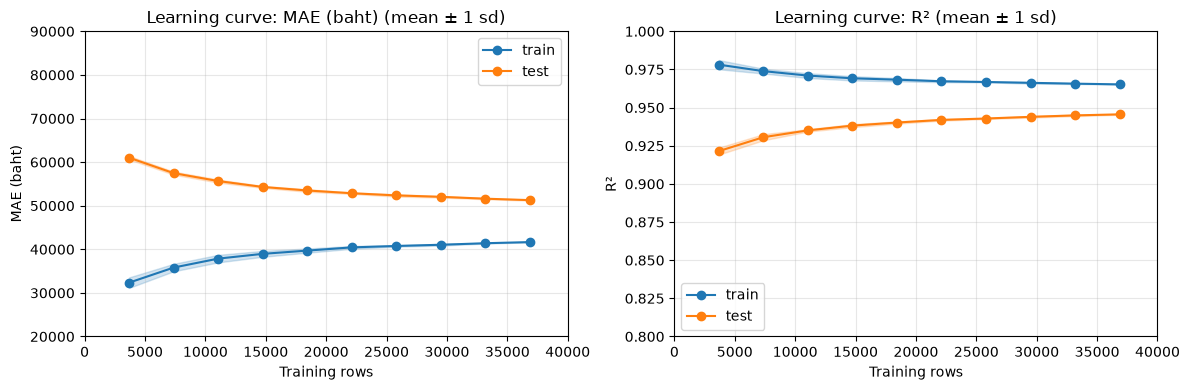

In [34]:
# [34] learning curve: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดง lc_table จากเซลล์ [33] เป็นตาราง แล้ววาดกราฟ 2 ช่องเคียงกัน (MAE และ R²)
#         แต่ละช่องมีเส้นค่าเฉลี่ยของ train และ test พร้อมแถบ ±1 sd
# ทำไม: ดูแนวโน้มว่าเมื่อเพิ่มแถวฝึกแล้วคะแนนเปลี่ยนอย่างไร และช่องว่างระหว่าง train กับ test
#       เปลี่ยนอย่างไร
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อขนาด และกราฟ 2 ช่อง
#   - ถ้า test MAE ยังลดลง (หรือ test R² ยังเพิ่ม) ที่ขนาดมาก ๆ อาจได้ประโยชน์จากข้อมูลเพิ่ม
#   - ถ้า train ดีกว่า test มาก แปลว่าโมเดลจำข้อมูลฝึกได้ดีกว่าข้อมูลใหม่ (อาการ overfit)
#     แต่สำหรับ XGBoost train MAE ต่ำกว่า test มากเป็นปกติ (boosting แก้ error บน train ทุกรอบ)
#     สิ่งที่ควรดูคือช่องว่างแคบลงเมื่อเพิ่มแถว (ข้อมูลมากขึ้น โมเดลจำทีละคันได้ยากขึ้น)
#     ถ้าช่องว่างกว้างขึ้นเมื่อเพิ่มแถว จึงเป็นสัญญาณที่น่าห่วง เซลล์ [40] ตรวจข้อนี้ให้
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_AXIS, R2_AXIS, ROWS_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง:
#   - เป็นหลักฐานเชิงชี้แนะเท่านั้น ไม่ใช่คำยืนยัน
#   - test ใช้อธิบายกราฟเท่านั้น ไม่ใช้เลือกพารามิเตอร์
#   - แถบ ±1 sd คือความแกว่งจากการเลือกชุดย่อยต่างกัน ไม่ใช่ confidence interval
#     (ช่วงความเชื่อมั่น) และไม่รวมความไม่แน่นอนจากการสุ่ม test ชุดใหม่
#   - ที่ขนาดเต็ม ทุกรอบใช้แถวชุดเดียวกันแต่เรียงลำดับต่างกัน สำหรับ XGBoost ลำดับแถวเปลี่ยนว่า
#     แถวไหนถูกสุ่มเลือก (subsample) ให้ต้นไม้แต่ละต้น โมเดลจึงต่างกันเล็กน้อย sd จึงไม่เป็นศูนย์
#     (ต่างจากโน้ตบุ๊ค DT) และค่าที่ขนาดเต็มอาจไม่ตรงกับผลในเซลล์ [30] ทุกหลัก
#   - ช่องว่าง (gap) ต้องอ่านคู่กับระดับคะแนน ไม่ใช้วัด overfit เพียงลำพัง
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_AXIS, R2_AXIS, ROWS_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [34] learning curve: ตารางและกราฟ ===")

table_formats = {"rows": "{:,.0f}", "repeats": "{:.0f}"}
for column in lc_table.columns:
    if "MAE" in column:
        table_formats[column] = "{:,.0f}"
    elif "R2" in column:
        table_formats[column] = "{:.4f}"

print(f"อ่านตาราง: ค่าเฉลี่ยและ sd ข้าม {LC_REPEATS} รอบ ของ MAE (บาท) และ R² ที่แต่ละจำนวนแถวฝึก")
display(lc_table.style.format(table_formats).hide(axis="index"))

out_of_axis = False
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, ylabel in zip(axes, ["MAE", "R2"], ["MAE (baht)", "R²"]):
    limits = MAE_AXIS if metric == "MAE" else R2_AXIS
    for part in ["train", "test"]:
        mean = lc_table[f"{part} {metric} mean"].to_numpy()
        sd = lc_table[f"{part} {metric} sd"].to_numpy()
        line, = ax.plot(lc_table["rows"], mean, marker="o", label=part)
        ax.fill_between(lc_table["rows"], mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
        if (mean - sd).min() < limits[0] or (mean + sd).max() > limits[1] or lc_table["rows"].max() > ROWS_AXIS[1]:
            out_of_axis = True
    ax.set(xlabel="Training rows", ylabel=ylabel, title=f"Learning curve: {ylabel} (mean ± 1 sd)")
    ax.set_xlim(*ROWS_AXIS)
    ax.set_ylim(*limits)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

if out_of_axis:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (learning curve) ให้ขยาย MAE_AXIS / R2_AXIS / ROWS_AXIS ในเซลล์ [03]")

=== [35] ตาราง CV train เทียบ validation ===
อ่านตาราง: หนึ่งแถวต่อ fold, MAE และ RMSE เป็นบาท, MAPE เป็นสัดส่วน (0.10 = 10%), gap = validation - train (R² gap = train - validation)


,train MAE,validation MAE,MAE gap,gap % of validation MAE,train R2,validation R2,R2 gap,train RMSE,validation RMSE,RMSE gap,train MAPE,validation MAPE,MAPE gap
1,"40,715","53,139","12,424",23.38,0.9672,0.9371,0.0301,"59,684","81,357","21,673",0.0803,0.1014,0.0212
2,"40,388","51,537","11,149",21.63,0.9671,0.9451,0.0220,"59,453","77,411","17,958",0.0799,0.0981,0.0183
3,"41,104","51,980","10,876",20.92,0.9662,0.9442,0.0220,"60,369","77,290","16,922",0.0813,0.0994,0.0181
4,"40,663","52,459","11,796",22.49,0.9669,0.9427,0.0242,"59,531","79,737","20,206",0.0803,0.0990,0.0186
5,"42,161","52,166","10,005",19.18,0.9644,0.9423,0.0220,"62,083","78,384","16,301",0.0828,0.0999,0.0171
mean,"41,006","52,256","11,250",21.52,0.9664,0.9423,0.0241,"60,224","78,836","18,612",0.0809,0.0996,0.0187
sd,621,533,822,1.43,0.0010,0.0028,0.0031,984,"1,536","2,026",0.0010,0.0011,0.0013


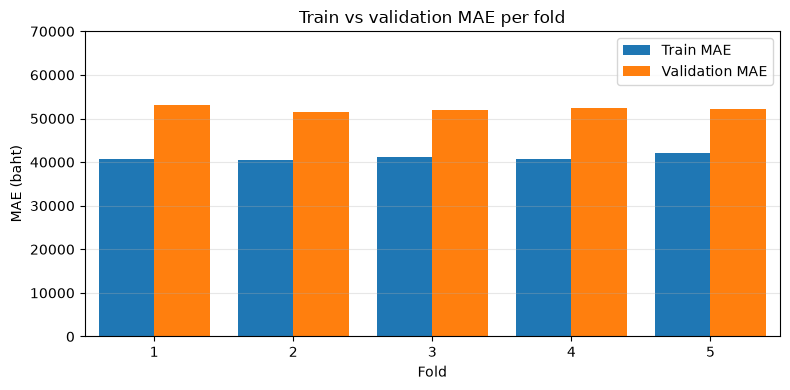

In [35]:
# [35] ตาราง CV train เทียบ validation
# ==================================================
# ทำอะไร: อ่านคะแนนของโมเดลผู้ชนะในแต่ละ fold ของ train ที่เก็บไว้ใน search.cv_results_ (เซลล์ [26])
#         แล้วเทียบคะแนนบนแถวที่ใช้ฝึก (train) กับแถวที่กันไว้ตรวจ (validation) ของ fold นั้น
#         ทั้ง MAE, RMSE (บาท), MAPE และ R² (ไม่ฝึกโมเดลใหม่ในเซลล์นี้)
#         (fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ, MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย,
#          RMSE = รากของความคลาดเคลื่อนยกกำลังสองเฉลี่ย (ลงโทษข้อผิดพลาดใหญ่หนักกว่า MAE) หน่วยบาท,
#          MAPE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ยเป็นสัดส่วนของราคาจริง เช่น 0.10 = 10%,
#          R² = สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ดีที่สุด)
# ทำไม: ดูขนาดและความสม่ำเสมอของช่องว่างระหว่าง train กับ validation
#       - train ดีกว่า validation มาก อาจเป็นสัญญาณ overfit (จำข้อมูลฝึกมากเกินไป)
#       - ถ้าทั้งสองแย่และใกล้กัน อาจเป็น underfit (โมเดลง่ายเกินไป)
#       เซลล์นี้ไม่ตัดสินให้อัตโนมัติ ให้ดูระดับคะแนนและความกระจายร่วมกัน
#       RMSE และ MAPE อยู่ในตารางนี้เพื่อเทียบกับผล test ที่เซลล์ [31] รายงาน MAE, RMSE, MAPE และ R² (เพิ่มเมื่อ 2026-10-27)
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อ fold (เลข fold เริ่มที่ 1) คอลัมน์ train MAE, validation MAE,
#              MAE gap (validation - train), gap เป็น % ของ validation MAE, train R²,
#              validation R², R² gap (train - validation), train/validation RMSE กับ RMSE gap,
#              train/validation MAPE กับ MAPE gap (ต่อท้ายตาราง) และท้ายตารางมีแถว mean กับ sd
#              (sd แบบ ddof=0 คำนวณจากแถว fold เท่านั้น) กับกราฟแท่งเทียบ train/validation MAE
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_BAR_AXIS, FOLD_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง:
#   - ใช้เฉพาะ train และ folds ไม่ใช้ val หรือ test และเป็นการตรวจผู้ชนะที่เลือกจาก fold เดิม
#     จึงไม่ใช่ผลประเมินอิสระจากการเลือกพารามิเตอร์
#   - ช่วงค่าใน grid (เซลล์ [21]) ออกแบบจาก pilot บน train ก่อนเปลี่ยนไฟล์ ซึ่งรวมแถว held-out ของ fold ในครั้งนั้นด้วย
#     และผู้ชนะถูกเลือกจาก fold เดิม CV MAE จึงอาจดีเกินจริงเล็กน้อย
#     ควรใช้ test ที่ยังไม่แตะ (และ val) ตรวจอิสระ ซึ่งเซลล์ [40] เทียบให้
#   - คะแนนทุกค่าอ่านจาก cv_results_ ของผู้ชนะ ซึ่งเก็บตอนฝึกแต่ละ fold ด้วย early stopping ในเซลล์ [22]
#     (ใช้เฉพาะ rounds ต้นแรกของ fold นั้น) ค่าเฉลี่ย validation MAE จึงเท่ากับ CV MAE ของผู้ชนะในเซลล์ [27]
#     ทุกประการ (เป็นตัวเลขชุดเดียวกัน) จำนวนรอบของแต่ละ fold อาจต่างกัน ดูรอบรายfold ในเซลล์ [27]
#   - แถวตรวจของ fold ใช้หยุดการฝึกและให้คะแนนด้วย (ข้อจำกัดที่ยอมรับ ดูเซลล์ [23]) คอลัมน์ validation
#     จึงดีเกินจริงเล็กน้อย ช่องว่างจริงบนข้อมูลที่ไม่เคยเห็นน่าจะกว้างกว่านี้เล็กน้อย
#   - สำหรับ XGBoost train MAE ต่ำกว่า validation มากเป็นปกติ (boosting แก้ error บน train ทุกรอบ)
#     ช่องว่างเป็นอาการที่ต้องอ่านคู่กับระดับ CV และความกระจาย ไม่ใช่มาตรวัด overfit เพียงลำพัง
#   - learning curve (เซลล์ [33]-[34]) และกราฟรายรอบ (เซลล์ [38]-[39]) เป็นการตรวจเพิ่ม
#     ช่วยดูว่าเพิ่มแถวฝึกหรือเพิ่มรอบแล้วคะแนนและช่องว่างเปลี่ยนอย่างไร
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_BAR_AXIS, FOLD_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [35] ตาราง CV train เทียบ validation ===")

def winner_folds(side, metric):
    """คะแนนรายfold ของผู้ชนะ (หนึ่งค่าต่อ fold) side = train หรือ test (แถวตรวจของ fold)"""
    return np.array([cv_results[f"split{k}_{side}_{metric}"][chosen_index] for k in range(n_splits)])


train_mae = -winner_folds("train", "MAE")  # error เก็บเป็นค่าติดลบ จึงกลับเครื่องหมายให้เป็น MAE บวก
validation_mae = -winner_folds("test", "MAE")  # "test" ในคีย์ = แถว validation ใน fold
mae_gap = validation_mae - train_mae
train_rmse = -winner_folds("train", "RMSE")
validation_rmse = -winner_folds("test", "RMSE")
train_mape = -winner_folds("train", "MAPE")  # สัดส่วนของราคาจริง (0.10 = 10%)
validation_mape = -winner_folds("test", "MAPE")
train_r2 = winner_folds("train", "R2")  # R2 เก็บเป็นค่าบวกอยู่แล้ว
validation_r2 = winner_folds("test", "R2")

fold_table = pd.DataFrame(
    {
        "train MAE": train_mae,
        "validation MAE": validation_mae,
        "MAE gap": mae_gap,
        "gap % of validation MAE": mae_gap * 100 / validation_mae,
        "train R2": train_r2,
        "validation R2": validation_r2,
        "R2 gap": train_r2 - validation_r2,
        "train RMSE": train_rmse,
        "validation RMSE": validation_rmse,
        "RMSE gap": validation_rmse - train_rmse,
        "train MAPE": train_mape,
        "validation MAPE": validation_mape,
        "MAPE gap": validation_mape - train_mape,
    },
    index=pd.Index(range(1, len(train_mae) + 1), name="fold"),
)

summary_rows = pd.DataFrame(
    [fold_table.mean(), fold_table.std(ddof=0)],
    index=["mean", "sd"],
)
cv_check_table = pd.concat([fold_table, summary_rows])

table_formats = {
    "train MAE": "{:,.0f}",
    "validation MAE": "{:,.0f}",
    "MAE gap": "{:,.0f}",
    "gap % of validation MAE": "{:.2f}",
    "train R2": "{:.4f}",
    "validation R2": "{:.4f}",
    "R2 gap": "{:.4f}",
    "train RMSE": "{:,.0f}",
    "validation RMSE": "{:,.0f}",
    "RMSE gap": "{:,.0f}",
    "train MAPE": "{:.4f}",
    "validation MAPE": "{:.4f}",
    "MAPE gap": "{:.4f}",
}
print("อ่านตาราง: หนึ่งแถวต่อ fold, MAE และ RMSE เป็นบาท, MAPE เป็นสัดส่วน (0.10 = 10%), gap = validation - train (R² gap = train - validation)")
display(cv_check_table.style.format(table_formats))

positions = np.arange(len(fold_table))
bar_width = 0.4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(positions - bar_width / 2, fold_table["train MAE"], bar_width, label="Train MAE")
ax.bar(positions + bar_width / 2, fold_table["validation MAE"], bar_width, label="Validation MAE")
ax.set_xticks(positions, fold_table.index)
ax.set(xlabel="Fold", ylabel="MAE (baht)", title="Train vs validation MAE per fold")
ax.set_xlim(*FOLD_AXIS)
ax.set_ylim(*MAE_BAR_AXIS)
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

if (
    fold_table[["train MAE", "validation MAE"]].max().max() > MAE_BAR_AXIS[1]
    or len(fold_table) - 1 + bar_width > FOLD_AXIS[1]
):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟแท่ง CV train เทียบ validation) ให้ขยาย MAE_BAR_AXIS / FOLD_AXIS ในเซลล์ [03]")

In [36]:
# [36] validation curve: อ่านจากผลค้นหา
# ==================================================
# ทำอะไร: สำหรับพารามิเตอร์ 3 ตัวใน PARAM_GRID (max_depth, min_child_weight, reg_lambda) เปลี่ยนค่าทีละตัว
#         ตามทุกค่าใน grid โดยคงอีก 2 ตัวไว้ตามผู้ชนะ แล้วอ่าน MAE บนส่วนฝึกและส่วนตรวจสอบ (validation)
#         เฉลี่ยข้าม fold พร้อม sd จากผลที่เก็บไว้ใน search.cv_results_ เก็บลง vc_results
#         (validation curve = กราฟคะแนนเมื่อเปลี่ยนพารามิเตอร์หนึ่งตัว,
#          fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ,
#          MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท,
#          sd = ส่วนเบี่ยงเบนมาตรฐานข้าม fold แบบ ddof=0)
# ทำไม: ดูว่าพารามิเตอร์แต่ละตัวทำให้โมเดลซับซ้อนขึ้น/ง่ายลงแล้ว MAE ฝึกกับ MAE ตรวจสอบ
#       ห่างกันอย่างไร เพื่ออ่านความซับซ้อนร่วมกับช่องว่างของคะแนน
#       grid เป็นตารางครบทุกคู่ (full factorial) จึงมีผลของทุกจุดบนเส้นอยู่แล้ว ไม่ต้องฝึกใหม่:
#       จุดบนเส้นของ max_depth ที่ค่า v คือชุดที่ max_depth = v และ min_child_weight, reg_lambda เท่ากับผู้ชนะ
# ผลที่ควรเห็น: ข้อความหนึ่งบรรทัดต่อพารามิเตอร์ จากนั้น vc_results พร้อมให้เซลล์ [37]
#              แสดงตารางและกราฟ (ไม่มีผลลัพธ์อื่นในเซลล์นี้)
# ข้อควรระวัง:
#   - ไม่ฝึกโมเดลใหม่และไม่เปลี่ยน search ค่าทุกจุดตรงกับแถวเดียวกันใน cv_results_ จึงตรงกับ CV MAE ในเซลล์ [27] และ [32]
#   - จำนวนรอบของแต่ละจุดต่างกันได้ (early stopping เลือกให้แต่ละชุด) เส้นนี้จึงเทียบ "ชุดที่ปรับรอบเหมาะแล้ว"
#     ไม่ใช่เทียบที่จำนวนรอบเท่ากัน ส่วนจำนวนรอบเอง เซลล์ [38]-[39] ดูละเอียดทุกรอบ
# ==================================================
print("=== [36] validation curve: อ่านจากผลค้นหา ===")

winner_grid_params = {name: best_params[name] for name in PARAM_GRID}
vc_results = {}
for name in PARAM_GRID:
    values = list(PARAM_GRID[name])
    point_indices = []  # index ใน cv_results_ ของชุดที่ตัวอื่นเท่าผู้ชนะ และตัวนี้เท่ากับแต่ละค่า
    for value in values:
        wanted = dict(winner_grid_params, **{name: value})
        matches = [index for index, params in enumerate(cv_results["params"]) if params == wanted]
        assert len(matches) == 1, f"ต้องมีชุด {wanted} เพียงชุดเดียวใน grid"
        point_indices.append(matches[0])
    vc_results[name] = {
        "values": values,
        "train_mean": -np.asarray(cv_results["mean_train_MAE"])[point_indices],
        "train_sd": np.asarray(cv_results["std_train_MAE"])[point_indices],
        "cv_mean": -np.asarray(cv_results["mean_test_MAE"])[point_indices],
        "cv_sd": np.asarray(cv_results["std_test_MAE"])[point_indices],
    }
    print(f"{name} เสร็จ ({len(values)} ค่า)")

=== [36] validation curve: อ่านจากผลค้นหา ===
max_depth เสร็จ (5 ค่า)
min_child_weight เสร็จ (3 ค่า)
reg_lambda เสร็จ (4 ค่า)


=== [37] validation curve: ตารางและกราฟ ===
อ่านตาราง max_depth: MAE เป็นบาท, gap = CV MAE - train MAE


value,train MAE mean,CV MAE mean,CV MAE sd,gap
8,"44,143","52,728",438,"8,584"
12,"43,063","52,448",446,"9,385"
16,"41,006","52,256",533,"11,250"
20,"39,600","52,331",519,"12,731"
24,"38,003","52,356",518,"14,354"


อ่านตาราง min_child_weight: MAE เป็นบาท, gap = CV MAE - train MAE


value,train MAE mean,CV MAE mean,CV MAE sd,gap
1,"41,006","52,256",533,"11,250"
5,"43,033","52,562",478,"9,529"
20,"44,885","53,280",549,"8,395"


อ่านตาราง reg_lambda: MAE เป็นบาท, gap = CV MAE - train MAE


value,train MAE mean,CV MAE mean,CV MAE sd,gap
0,"29,727","54,437",617,"24,710"
1,"35,737","52,682",512,"16,945"
10,"41,006","52,256",533,"11,250"
100,"42,379","52,569",348,"10,190"


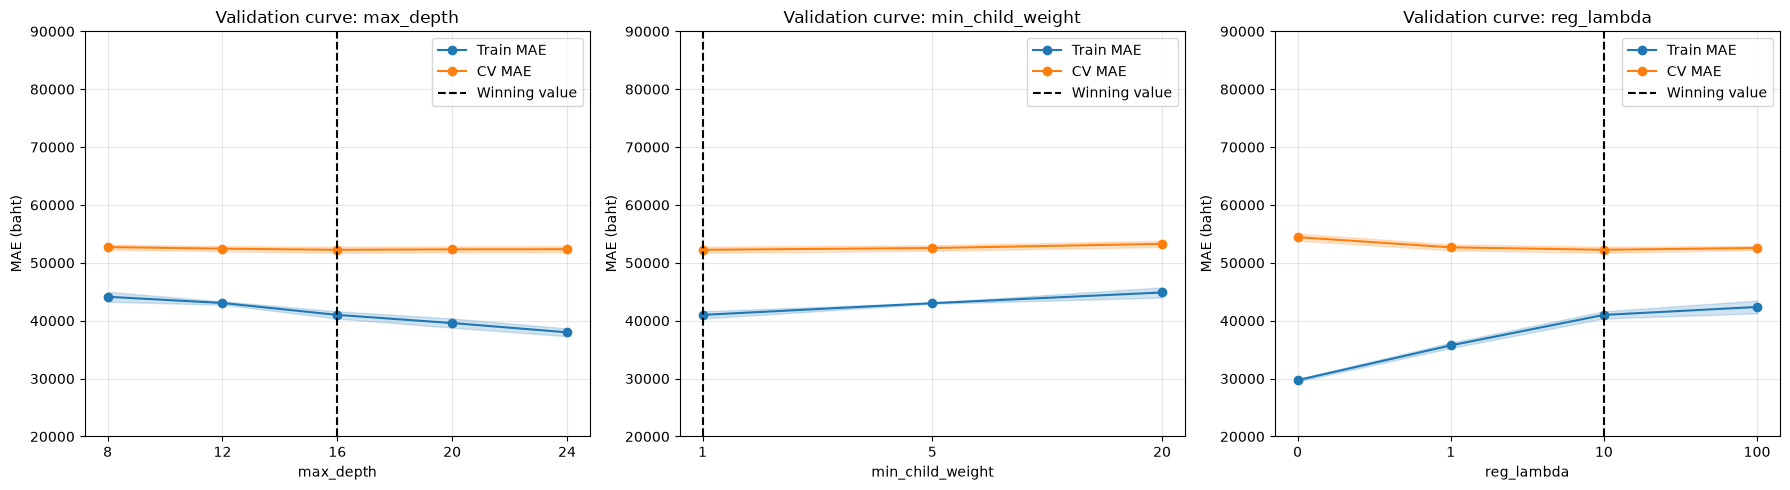

In [37]:
# [37] validation curve: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดงตารางของแต่ละพารามิเตอร์จาก vc_results (เซลล์ [36]) แล้ววาดกราฟ 3 ช่อง (1 x 3)
#         เส้น train และ CV MAE เฉลี่ย พร้อมแถบ ±1 sd และเส้นประแนวตั้งที่ค่าของผู้ชนะ
# ทำไม: ดูว่าพารามิเตอร์แต่ละตัวพาโมเดลไปทาง overfit หรือ underfit
#       (overfit = จำข้อมูลฝึกมากเกินจนใช้กับข้อมูลใหม่ไม่ดี, underfit = ง่ายเกินจนจับแบบแผนไม่ได้)
# วิธีอ่าน:
#   - ทิศทางความซับซ้อน: max_depth ยิ่งลึก, min_child_weight ยิ่งเล็ก, reg_lambda ยิ่งเล็ก
#     โมเดลยิ่งซับซ้อน (จำนวนรอบไม่ใช่แกนในเซลล์นี้ เพราะ early stopping เลือกให้แต่ละจุด)
#     (บนกราฟ ตำแหน่ง x เรียงตามลำดับค่าใน PARAM_GRID ไม่ใช่ระยะห่างจริง)
#   - overfit: train MAE ต่ำมากแต่ CV MAE สูงกว่ามาก และ CV MAE เริ่มแย่ลงเมื่อซับซ้อนขึ้น
#     มักเกิดทางด้านซับซ้อน (เช่น ต้นไม้ลึกมาก min_child_weight เล็กและ reg_lambda เล็ก)
#   - underfit: ทั้ง train และ CV MAE สูงและใกล้กัน มักเกิดทางด้านง่าย (เช่น max_depth = 8 หรือ reg_lambda = 100)
#   - ผู้ชนะ (เส้นประ) คือชุดที่ CV MAE ต่ำสุดของทั้ง grid จึงควรอยู่ที่จุดต่ำสุดของ CV MAE บนทุกเส้น
#     (เพราะเส้นแต่ละเส้นผ่านจุดผู้ชนะ และจุดอื่นบนเส้นเป็นชุดใน grid เดียวกัน)
#     ถ้าเส้นไหนมีจุดต่ำกว่าเส้นประ แปลว่าอ่านผิด ให้ตรวจเซลล์ [36]
# ผลที่ควรเห็น: ตาราง 3 ตาราง (คอลัมน์ value, train MAE mean, CV MAE mean, CV MAE sd, gap
#              โดย gap = CV MAE - train MAE) และรูปเดียวที่มี 3 กราฟเรียงแนวนอน
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง: ตารางและกราฟนี้ใช้ train กับ folds เดิม จึงไม่ใช่ผลประเมินอิสระ
#              gap กว้างเป็นปกติของ XGBoost ให้ดูว่า CV MAE แย่ลงหรือไม่เป็นหลัก
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [37] validation curve: ตารางและกราฟ ===")

for name in PARAM_GRID:
    result = vc_results[name]
    value_labels = []
    for value in result["values"]:
        value_labels.append(f"{value:g}")
    table = pd.DataFrame(
        {
            "value": value_labels,
            "train MAE mean": result["train_mean"],
            "CV MAE mean": result["cv_mean"],
            "CV MAE sd": result["cv_sd"],
            "gap": result["cv_mean"] - result["train_mean"],
        }
    )
    print(f"อ่านตาราง {name}: MAE เป็นบาท, gap = CV MAE - train MAE")
    display(
        table.style
        .format(
            {
                "train MAE mean": "{:,.0f}",
                "CV MAE mean": "{:,.0f}",
                "CV MAE sd": "{:,.0f}",
                "gap": "{:,.0f}",
            }
        )
        .hide(axis="index")
    )

out_of_axis = False
fig, axes = plt.subplots(1, len(PARAM_GRID), figsize=(18, 5))
for ax, name in zip(axes, PARAM_GRID):
    result = vc_results[name]
    values = result["values"]
    positions = np.arange(len(values))  # ใช้ตำแหน่งแทนค่าจริง ระยะห่างของค่าจึงไม่เท่ากัน

    tick_labels = []
    for value in values:
        tick_labels.append(f"{value:g}")

    for mean, sd, label in [
        (result["train_mean"], result["train_sd"], "Train MAE"),
        (result["cv_mean"], result["cv_sd"], "CV MAE"),
    ]:
        line, = ax.plot(positions, mean, marker="o", label=label)
        ax.fill_between(positions, mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
        if (mean - sd).min() < MAE_AXIS[0] or (mean + sd).max() > MAE_AXIS[1]:
            out_of_axis = True

    winner_value = search.best_params_[name]
    ax.axvline(values.index(winner_value), color="black", linestyle="--", label="Winning value")
    ax.set_xticks(positions, tick_labels)
    ax.set(xlabel=name, ylabel="MAE (baht)", title=f"Validation curve: {name}")
    ax.set_ylim(*MAE_AXIS)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

if out_of_axis:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (validation curve) ให้ขยาย MAE_AXIS ในเซลล์ [03]")

In [38]:
# [38] MAE รายรอบ: คำนวณ
# ==================================================
# ทำอะไร: ฝึกโมเดลด้วยพารามิเตอร์ของผู้ชนะใหม่ในแต่ละ fold ของ train ให้ครบ curve_rounds รอบ
#         (= รอบมากสุดของ fold ที่ผู้ชนะใช้ + EARLY_STOPPING_ROUNDS แต่ไม่เกิน MAX_ROUNDS)
#         แล้วเก็บ MAE "ทุกรอบ" ทั้งบนแถวที่ใช้ฝึก (train fold) และแถวที่กันไว้ตรวจ (CV fold)
#         เก็บไว้ใน round_curves ให้เซลล์ [39] แสดงตารางและกราฟ
#         (รอบ = boosting round = การเพิ่มต้นไม้ 1 ต้น, MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท)
# ทำไม: จำนวนรอบ (n_estimators) เป็นตัวที่ทำให้ XGBoost overfit ได้ง่ายที่สุด ทุกรอบที่เพิ่ม error บน
#       train ลดลงเสมอ แต่ error บนข้อมูลที่ไม่เคยเห็นจะลดลงช่วงแรก แล้วนิ่ง แล้วเริ่มแย่ลง
#       กราฟรายรอบแสดงให้เห็นว่าจำนวนรอบที่เลือกอยู่ตรงไหนของเส้นนี้ (ละเอียดทุกรอบ)
#       วิธีคำนวณ: ส่งแถวของ fold เข้า eval_set ตอนฝึก XGBoost จะวัด MAE ของโมเดลที่มี 1, 2, 3, ...
#       ต้นแรกให้ทุกรอบ ฝึกครั้งเดียวจึงได้ทั้งเส้น ผลที่รอบ k เท่ากับโมเดลที่ฝึก n_estimators = k
#       (pilot 2026-10-23 ยืนยันแล้วว่าต้นไม้ k ต้นแรกของโมเดลที่ยาวกว่า เหมือนโมเดล k ต้นทุกประการ)
#       เซลล์นี้ไม่ใช้ early stopping เพื่อให้เห็นเส้นยาวเลยจุดที่ early stopping เคยหยุด (เกินไป EARLY_STOPPING_ROUNDS รอบ
#       ของ fold ที่หยุดช้าสุด) eval_set ใช้วัดผลอย่างเดียว ไม่เปลี่ยนการฝึก
# ผลที่ควรเห็น: ข้อความ "fold k/5 เสร็จ" ทีละบรรทัด และบรรทัดสรุปจำนวนรอบที่คำนวณ
# ข้อควรระวัง:
#   - ใช้ train และ folds เดิมเท่านั้น ไม่ใช้ validation หรือ test (กราฟนี้ "train data only")
#   - แต่ละ fold เข้ารหัส one-hot จากแถวฝึกของ fold นั้นเอง เหมือนที่ fit_one_fold ทำในเซลล์ [22]
#   - ใช้พารามิเตอร์ของผู้ชนะทุกตัว ยกเว้น n_estimators ที่ตั้งเป็น curve_rounds เพื่อดูทั้งช่วง
#   - ต้นไม้ k ต้นแรกที่นี่เหมือนที่ผู้ชนะฝึกในเซลล์ [22] ทุกประการ (seed และ thread เท่าเดิม)
#     แต่เส้นเฉลี่ยข้าม fold ที่รอบหนึ่ง ๆ ไม่เท่ากับ CV MAE ของผู้ชนะ เพราะ CV MAE ของผู้ชนะ
#     ให้แต่ละ fold ใช้รอบที่ดีที่สุดของ fold นั้นเอง (ดูเซลล์ [39])
# ==================================================
print("=== [38] MAE รายรอบ: คำนวณ ===")

curve_rounds = min(MAX_ROUNDS, max(fold_rounds) + EARLY_STOPPING_ROUNDS)  # fold_rounds จากเซลล์ [27]
train_fold_curves = []
cv_fold_curves = []
for fold_number, (fit_index, check_index) in enumerate(folds, start=1):
    fit_part = train.iloc[fit_index]
    check_part = train.iloc[check_index]
    encoder = FoldOneHot(NUM_COLS, CAT_COLS).fit(fit_part[features])
    encoded_fit = encoder.transform(fit_part[features])
    encoded_check = encoder.transform(check_part[features])
    round_model = clone(search.best_estimator_.named_steps["model"])
    round_model.set_params(n_estimators=curve_rounds)
    round_model.fit(
        encoded_fit,
        fit_part["price"],
        eval_set=[(encoded_fit, fit_part["price"]), (encoded_check, check_part["price"])],
        verbose=False,
    )
    history = round_model.evals_result()  # validation_0 = แถวฝึก, validation_1 = แถวตรวจ
    train_fold_curves.append(history["validation_0"]["mae"])
    cv_fold_curves.append(history["validation_1"]["mae"])
    print(f"fold {fold_number}/{len(folds)} เสร็จ")

round_curves = pd.DataFrame({
    "round": np.arange(1, curve_rounds + 1),
    "train MAE mean": np.mean(train_fold_curves, axis=0),
    "train MAE sd": np.std(train_fold_curves, axis=0),
    "CV MAE mean": np.mean(cv_fold_curves, axis=0),
    "CV MAE sd": np.std(cv_fold_curves, axis=0),
})
print(f"ได้ MAE รายรอบครบ {curve_rounds:,} รอบ เฉลี่ยจาก {len(folds)} fold")

=== [38] MAE รายรอบ: คำนวณ ===


fold 1/5 เสร็จ


fold 2/5 เสร็จ


fold 3/5 เสร็จ


fold 4/5 เสร็จ


fold 5/5 เสร็จ
ได้ MAE รายรอบครบ 189 รอบ เฉลี่ยจาก 5 fold


=== [39] MAE รายรอบ: ตารางและกราฟ ===
อ่านตาราง: MAE เฉลี่ย 5 fold (บาท) ที่รอบตัวอย่างและรอบของผู้ชนะ, gap = CV MAE - train MAE


round,train MAE mean,train MAE sd,CV MAE mean,CV MAE sd,gap
25,"56,440",175,"61,227",500,"4,788"
50,"45,297",210,"53,124",479,"7,827"
100,"41,944",206,"52,322",516,"10,378"
122,"41,004",202,"52,270",523,"11,265"


รอบที่ CV MAE ต่ำสุด     : 124 (CV MAE 52,266 บาท)
รอบของผู้ชนะ (เฉลี่ย 5 fold): 122 (CV MAE ของเส้นเฉลี่ยที่รอบนี้ 52,270 บาท)
ส่วนต่างจากจุดต่ำสุด      : 4 บาท
CV MAE ผู้ชนะจาก search  : 52,256 บาท (ใกล้เคียง ต่ำกว่าหรือเท่ากับบรรทัดรอบของผู้ชนะ เพราะแต่ละ fold ใช้รอบของตัวเอง)


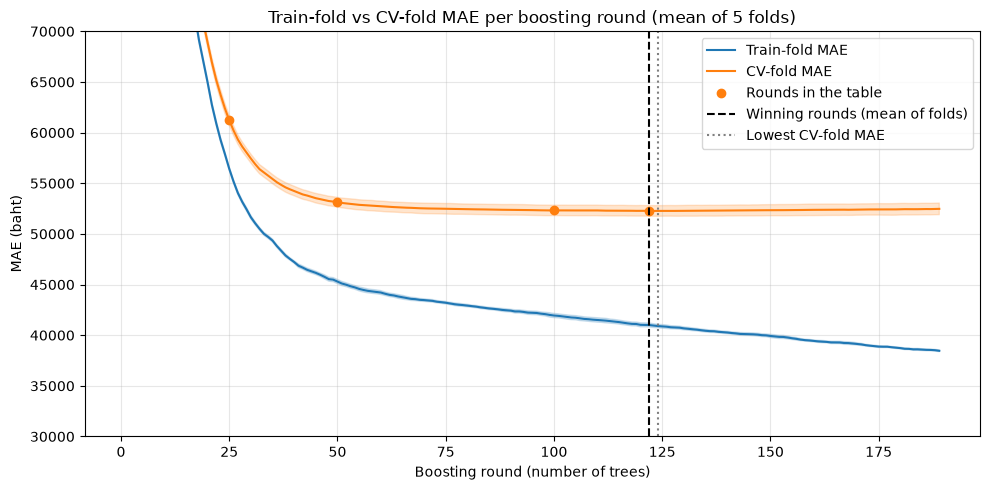

In [39]:
# [39] MAE รายรอบ: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดง round_curves จากเซลล์ [38] เป็นตาราง (เฉพาะรอบตัวอย่าง 25, 50, 100, 200, 300, 400, 500, 750, 1000
#         ที่ไม่เกิน curve_rounds บวกรอบของผู้ชนะ) และกราฟเส้น
#         MAE เฉลี่ย 5 fold ของแถวฝึก (train fold) และแถวตรวจ (CV fold) ทุกรอบ พร้อมแถบ ±1 sd
#         (sd แบบ ddof=0 ข้าม fold) เส้นประแนวตั้งที่จำนวนรอบของผู้ชนะ และเส้นจุดที่รอบที่ CV MAE ต่ำสุด
#         แล้วพิมพ์สรุปรอบที่ดีที่สุดเทียบกับรอบของผู้ชนะ
# ทำไม: ดูว่าจำนวนรอบที่ผู้ชนะใช้ (ค่าเฉลี่ยรอบที่ early stopping เลือกในแต่ละ fold) อยู่ก่อน ตรง หรือหลังจุดที่ CV MAE ต่ำสุดของเส้นเฉลี่ย
#       - เส้น train fold ลดลงเรื่อย ๆ เสมอ (boosting แก้ error บนแถวฝึกทุกรอบ) จึงบอกเรื่อง overfit ไม่ได้
#       - เส้น CV fold คือสิ่งที่ต้องดู: ช่วงแรกลดลงเร็ว (underfit = รอบน้อยไป) แล้วแบน แล้วค่อย ๆ
#         สูงขึ้น (overfit = รอบมากไป ต้นไม้ใหม่เริ่มจำรายละเอียดเฉพาะของแถวฝึก)
#       - จุดต่ำสุดของเส้นเฉลี่ยกับรอบของผู้ชนะอาจไม่ตรงกันพอดี เพราะ early stopping หาจุดต่ำสุดของแต่ละ fold
#         แยกกัน แล้วผู้ชนะใช้ค่าเฉลี่ยของรอบเหล่านั้น ส่วนเส้นนี้เฉลี่ย MAE ของ 5 fold ก่อนแล้วหาจุดต่ำสุด
#       - CV MAE ที่รอบของผู้ชนะจากเส้นนี้ ใกล้เคียงแต่ไม่เท่ากับ CV MAE ของผู้ชนะจากการค้นหา (เซลล์ [27])
#         และควรสูงกว่าเล็กน้อยหรือเท่ากัน เพราะ CV MAE ในเซลล์ [27] ให้แต่ละ fold ใช้รอบที่ดีที่สุดของ fold นั้นเอง
#         (ถ้าห่างกันมากผิดปกติ ให้ตรวจเซลล์ [38])
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อรอบตัวอย่าง บรรทัดสรุป และกราฟ 1 รูป
#       แกน y ตัดช่วงแรก ๆ ที่ MAE สูงมากออก (ตรวจเทียบแกนเฉพาะตั้งแต่รอบที่ 25 เป็นต้นไป) เพื่อให้เห็นส่วนที่สำคัญ
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_ROUND_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง: ใช้ train และ folds เดิม จึงไม่ใช่ผลประเมินอิสระ เซลล์ [40] ใช้ผลนี้ในการตรวจ overfit
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_ROUND_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [39] MAE รายรอบ: ตารางและกราฟ ===")

winner_rounds = search.best_params_["n_estimators"]
table_ticks = {tick for tick in [25, 50, 100, 200, 300, 400, 500, 750, 1000] if tick <= curve_rounds}
table_ticks.add(winner_rounds)  # ผู้ชนะต้องอยู่ในตารางเสมอ
table_rounds = round_curves[round_curves["round"].isin(table_ticks)].copy()
table_rounds["gap"] = table_rounds["CV MAE mean"] - table_rounds["train MAE mean"]

print("อ่านตาราง: MAE เฉลี่ย 5 fold (บาท) ที่รอบตัวอย่างและรอบของผู้ชนะ, gap = CV MAE - train MAE")
display(
    table_rounds.style
    .format({
        "round": "{:,.0f}",
        "train MAE mean": "{:,.0f}",
        "train MAE sd": "{:,.0f}",
        "CV MAE mean": "{:,.0f}",
        "CV MAE sd": "{:,.0f}",
        "gap": "{:,.0f}",
    })
    .hide(axis="index")
)

best_row = round_curves.loc[round_curves["CV MAE mean"].idxmin()]
winner_row = round_curves.loc[round_curves["round"] == winner_rounds].iloc[0]
best_mae = best_row["CV MAE mean"]
winner_mae = winner_row["CV MAE mean"]
print(f"รอบที่ CV MAE ต่ำสุด     : {best_row['round']:,.0f} (CV MAE {best_mae:,.0f} บาท)")
print(f"รอบของผู้ชนะ (เฉลี่ย 5 fold): {winner_rounds:,} (CV MAE ของเส้นเฉลี่ยที่รอบนี้ {winner_mae:,.0f} บาท)")
print(f"ส่วนต่างจากจุดต่ำสุด      : {winner_mae - best_mae:,.0f} บาท")
print(f"CV MAE ผู้ชนะจาก search  : {cv_mae_all[chosen_index]:,.0f} บาท (ใกล้เคียง ต่ำกว่าหรือเท่ากับบรรทัดรอบของผู้ชนะ เพราะแต่ละ fold ใช้รอบของตัวเอง)")

fig, ax = plt.subplots(figsize=(10, 5))
for column, label in [("train MAE", "Train-fold MAE"), ("CV MAE", "CV-fold MAE")]:
    mean = round_curves[f"{column} mean"].to_numpy()
    sd = round_curves[f"{column} sd"].to_numpy()
    line, = ax.plot(round_curves["round"], mean, label=label)
    ax.fill_between(round_curves["round"], mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
ax.plot(table_rounds["round"], table_rounds["CV MAE mean"], "o", color="tab:orange",
        label="Rounds in the table")
ax.axvline(winner_rounds, color="black", linestyle="--", label="Winning rounds (mean of folds)")
ax.axvline(best_row["round"], color="gray", linestyle=":", label="Lowest CV-fold MAE")
ax.set_ylim(*MAE_ROUND_AXIS)  # รอบแรกๆ ที่ MAE สูงมากถูกตัดออกจากภาพเหมือนเดิม
ax.set(
    xlabel="Boosting round (number of trees)",
    ylabel="MAE (baht)",
    title="Train-fold vs CV-fold MAE per boosting round (mean of 5 folds)",
)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ตรวจเฉพาะรอบตั้งแต่รอบที่ 25 เป็นต้นไป (รอบก่อนหน้านั้นตั้งใจตัดทิ้ง)
shown = round_curves[round_curves["round"] >= min(25, curve_rounds)]
for column in ["train MAE", "CV MAE"]:
    if (
        (shown[f"{column} mean"] - shown[f"{column} sd"]).min() < MAE_ROUND_AXIS[0]
        or (shown[f"{column} mean"] + shown[f"{column} sd"]).max() > MAE_ROUND_AXIS[1]
    ):
        print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟ MAE รายรอบ) ให้ขยาย MAE_ROUND_AXIS ในเซลล์ [03]")
        break

In [40]:
# [40] สรุปการตรวจ overfit
# ==================================================
# ทำอะไร: รวมหลักฐานจากเซลล์ก่อนหน้าเป็นบรรทัด PASS / WARN 4 ข้อ ตามเกณฑ์ที่ประกาศไว้ล่วงหน้า
#         โน้ตบุ๊คจึงตัดสินตัวเลขของตัวเองได้ โดยไม่ต้องจำค่าจากการรันครั้งก่อน
# ความจริงเฉพาะของ XGBoost (อ่านก่อนดูผล):
#   - train MAE ต่ำกว่า CV / validation / test มากเสมอ เพราะทุกรอบของ boosting สร้างต้นไม้ใหม่มาแก้
#     ส่วนที่ยังทายผิด "บนแถวฝึก" โดยตรง error บน train จึงลดลงทุกรอบจนเกือบจำได้หมด
#     ช่องว่าง train กับ test ลำพังจึงไม่ใช่หลักฐานของ overfit
#   - การตรวจที่ซื่อตรงคือ (ก) ค่าที่ CV สัญญาไว้ (CV MAE จาก train) ตรงกับผลบนข้อมูลที่ไม่เคยแตะ
#     (validation และ test) หรือไม่ (ข) จำนวนรอบอยู่ในช่วงที่ CV MAE ยังไม่แย่ลง (ค) เมื่อเพิ่มข้อมูลฝึก
#     ช่องว่างแคบลงตามที่ควรเป็น
# เกณฑ์และเหตุผล:
#   1-2) |validation MAE - CV MAE| และ |test MAE - CV MAE| ไม่เกิน 5% ของ CV MAE
#        เหตุผล: MAE ที่วัดจากรถใน validation หรือ test มีความแกว่งจากการสุ่มตัวอย่าง (SE = sd ของ |ความผิดพลาด|
#        หาร sqrt(จำนวนคัน)) เซลล์นี้คำนวณและพิมพ์ SE จากชุดข้อมูลที่ใช้จริงให้ดูด้วย
#        และ CV MAE เองก็แกว่งได้เช่นกัน ใช้เกณฑ์ 5% เป็นหลักปฏิบัติ โดยอ่านร่วมกับ SE ถ้าต่างเกินนี้
#        ไม่น่าใช่ความบังเอิญ แปลว่าโมเดลทำได้แย่กว่าที่ CV สัญญาไว้ (อาจ overfit กับการเลือกบน train)
#   3) CV MAE ที่รอบของผู้ชนะ สูงกว่าจุดต่ำสุดของเส้นรายรอบ (เซลล์ [39]) ไม่เกิน 1 SE ของผู้ชนะ
#      (SE = std ของ CV MAE ข้าม fold / sqrt(จำนวน fold) ใช้เป็นไม้บรรทัดวัดว่าต่างมากหรือน้อย ไม่ได้ใช้เลือกผู้ชนะ)
#      รอบของผู้ชนะ = ค่าเฉลี่ยรอบที่ early stopping เลือกในแต่ละ fold เทียบกับจุดต่ำสุดของเส้นเฉลี่ย
#      เหตุผล: ถ้าเกิน แปลว่าจำนวนรอบที่เลือกน้อยไป (underfit) หรือมากไป (overfit) อย่างมีนัย
#   4) ช่องว่าง test MAE - train MAE ของ learning curve ที่ขนาดเต็ม แคบกว่าที่ขนาดเล็กสุด
#      เหตุผล: โมเดลที่พอดีจะจำทีละคันได้ยากขึ้นเมื่อข้อมูลมากขึ้น ช่องว่างจึงควรแคบลง
#      ถ้าช่องว่างไม่แคบลงหรือกว้างขึ้น เป็นสัญญาณว่าโมเดลยังจำข้อมูลฝึกมากเกินไป
# ผลที่ควรเห็น: ตัวเลขประกอบแต่ละข้อ บรรทัด PASS / WARN 4 บรรทัด และบรรทัดสรุปรวม
# ข้อควรระวัง: เกณฑ์เหล่านี้เป็นหลักปฏิบัติที่สมเหตุสมผล ไม่ใช่การทดสอบทางสถิติที่เข้มงวด
#         CV MAE ดีเกินจริงเล็กน้อย เพราะแถวตรวจของ fold ใช้หยุดการฝึกและให้คะแนนด้วย (เซลล์ [23])
#         ข้อ 1-2 จึงเป็นตัวตรวจอิสระที่สำคัญ: validation / test ไม่เคยถูกใช้เลือกอะไรเลย
#         เซลล์นี้ไม่เปลี่ยนโมเดลและไม่ใช้ผลเหล่านี้ย้อนไปเลือกพารามิเตอร์ใหม่
#         ถ้ามี WARN ให้อ่านตัวเลขประกอบและกราฟของเซลล์ที่เกี่ยวข้องก่อนสรุป
# ==================================================
print("=== [40] สรุปการตรวจ overfit ===")

tolerance_percent = 5.0
cv_mae_winner = cv_mae_all[chosen_index]
winner_se = cv_results["std_test_MAE"][chosen_index] / np.sqrt(n_splits)

checks = []
for name, part in [("validation", val), ("test", test)]:
    errors = np.abs(part["price"].to_numpy() - model.predict(part[features]))
    noise_percent = errors.std(ddof=1) / np.sqrt(len(errors)) / errors.mean() * 100
    difference_percent = (results[name]["MAE"] - cv_mae_winner) / cv_mae_winner * 100
    print(f"{name:<10} MAE {results[name]['MAE']:,.0f} บาท เทียบ CV MAE {cv_mae_winner:,.0f} บาท"
          f" ต่าง {difference_percent:+.2f}% (ความแกว่งจากการสุ่ม 1 SE ประมาณ {noise_percent:.2f}%)")
    checks.append((
        abs(difference_percent) <= tolerance_percent,
        f"{name} MAE ต่างจาก CV MAE ไม่เกิน {tolerance_percent:.0f}% (generalisation)",
    ))

rounds_excess = winner_row["CV MAE mean"] - best_row["CV MAE mean"]
if winner_rounds < best_row["round"]:
    side = "ก่อนจุดต่ำสุด (ฝั่งรอบน้อย ปลอดภัยจาก overfit)"
elif winner_rounds > best_row["round"]:
    side = "หลังจุดต่ำสุด (ฝั่งรอบมาก)"
else:
    side = "ตรงจุดต่ำสุดพอดี"
print(f"จำนวนรอบของผู้ชนะ {winner_rounds:,} อยู่{side} สูงกว่าจุดต่ำสุด {rounds_excess:,.0f} บาท"
      f" (1 SE = {winner_se:,.0f} บาท)")
checks.append((
    rounds_excess <= winner_se,
    "จำนวนรอบอยู่ในช่วง 1 SE ของจุดที่ CV MAE ต่ำสุด (ไม่น้อยหรือมากเกินไป)",
))

smallest = lc_table.iloc[0]
largest = lc_table.iloc[-1]
gap_smallest = smallest["test MAE mean"] - smallest["train MAE mean"]
gap_largest = largest["test MAE mean"] - largest["train MAE mean"]
print(f"ช่องว่าง test - train ของ learning curve: {smallest['rows']:,.0f} แถว = {gap_smallest:,.0f} บาท,"
      f" {largest['rows']:,.0f} แถว = {gap_largest:,.0f} บาท")
checks.append((
    gap_largest < gap_smallest,
    "ช่องว่าง test - train แคบลงเมื่อเพิ่มข้อมูลฝึก (learning curve)",
))

print()
warn_count = 0
for passed, description in checks:
    print(f"{'PASS' if passed else 'WARN'} : {description}")
    if not passed:
        warn_count = warn_count + 1
if warn_count == 0:
    print("สรุป: ผ่านทุกข้อ ไม่พบสัญญาณ overfit ตามเกณฑ์ที่ตั้งไว้")
else:
    print(f"สรุป: มี WARN {warn_count} ข้อ ให้อ่านตัวเลขประกอบและกราฟของเซลล์ที่เกี่ยวข้องก่อนสรุป")

=== [40] สรุปการตรวจ overfit ===
validation MAE 51,191 บาท เทียบ CV MAE 52,256 บาท ต่าง -2.04% (ความแกว่งจากการสุ่ม 1 SE ประมาณ 1.66%)
test       MAE 51,271 บาท เทียบ CV MAE 52,256 บาท ต่าง -1.89% (ความแกว่งจากการสุ่ม 1 SE ประมาณ 1.63%)
จำนวนรอบของผู้ชนะ 122 อยู่ก่อนจุดต่ำสุด (ฝั่งรอบน้อย ปลอดภัยจาก overfit) สูงกว่าจุดต่ำสุด 4 บาท (1 SE = 239 บาท)
ช่องว่าง test - train ของ learning curve: 3,685 แถว = 28,659 บาท, 36,859 แถว = 9,624 บาท

PASS : validation MAE ต่างจาก CV MAE ไม่เกิน 5% (generalisation)
PASS : test MAE ต่างจาก CV MAE ไม่เกิน 5% (generalisation)
PASS : จำนวนรอบอยู่ในช่วง 1 SE ของจุดที่ CV MAE ต่ำสุด (ไม่น้อยหรือมากเกินไป)
PASS : ช่องว่าง test - train แคบลงเมื่อเพิ่มข้อมูลฝึก (learning curve)
สรุป: ผ่านทุกข้อ ไม่พบสัญญาณ overfit ตามเกณฑ์ที่ตั้งไว้


=== [41] ความสำคัญแบบ permutation บน test ===


Permutation importance: increase in test MAE (baht)
variable        mean       std  share (%)
 car_age 119873.9156 2039.6061    28.2785
  engine 116638.7906 1220.7740    27.5153
car_type  55719.5328  761.8673    13.1443
   brand  46878.2070  581.8367    11.0587
   model  34656.3297  445.5606     8.1755
    fuel  21473.0750  514.3557     5.0655
 mileage  21026.6594  779.5182     4.9602
    gear   7638.7746  288.5228     1.8020


,variable,mean,std,share (%)
0,car_age,119873.915625,2039.606063,28.278467
1,engine,116638.790625,1220.774002,27.515295
2,car_type,55719.532813,761.867292,13.144335
3,brand,46878.207031,581.836688,11.058651
4,model,34656.329688,445.560560,8.175489
5,fuel,21473.075000,514.355733,5.065536
6,mileage,21026.659375,779.518236,4.960226
7,gear,7638.774609,288.522787,1.802000


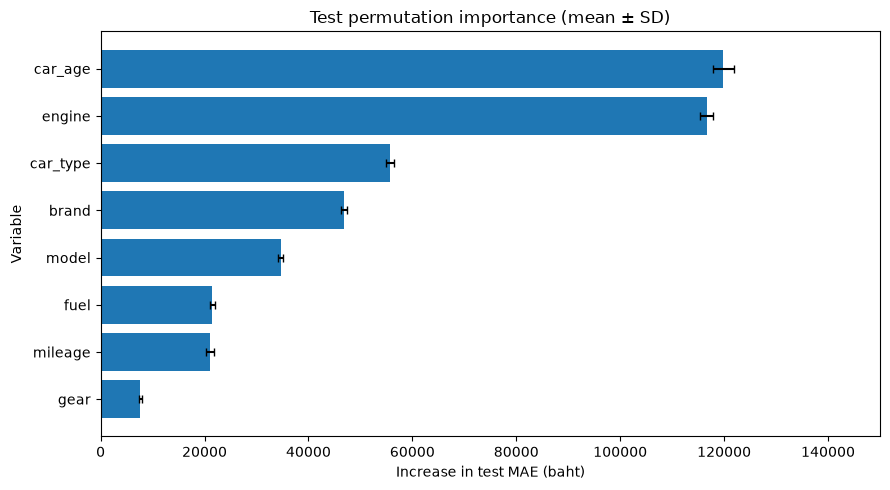

In [41]:
# [41] ความสำคัญแบบ permutation บน test
# ==================================================
# ทำอะไร: สลับตัวแปรต้นฉบับทีละคอลัมน์ก่อน encoding สิบรอบแล้ววัด MAE ที่เพิ่มเป็นบาท
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ค่าติดลบเกิดได้; share ใช้ผลรวมมีเครื่องหมาย ไม่ตัดค่าลบทิ้ง; ถ้าผลรวมศูนย์ให้ share เป็นศูนย์
# ==================================================
print("=== [41] ความสำคัญแบบ permutation บน test ===")

importance_estimator = search.best_estimator_
X_test = test[features]
y_test = test["price"]
assert len(features) == 8 and list(X_test.columns) == features
permutation_result = permutation_importance(
    importance_estimator, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=10, random_state=SEED,
)
permutation_table = pd.DataFrame({"variable": features, "mean": permutation_result.importances_mean,
                                  "std": permutation_result.importances_std})
# ใช้ผลรวมแบบมีเครื่องหมาย ค่าลบหมายถึงสลับแล้วดีขึ้น; ถ้าผลรวมเป็นศูนย์ให้ share เป็นศูนย์
total_increase = permutation_table["mean"].sum()
permutation_table["share (%)"] = (100 * permutation_table["mean"] / total_increase
                                   if total_increase != 0 else 0.0)
permutation_table = permutation_table.sort_values("mean", ascending=False, kind="stable").reset_index(drop=True)
print("Permutation importance: increase in test MAE (baht)")
print(permutation_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(permutation_table)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(permutation_table["variable"], permutation_table["mean"], xerr=permutation_table["std"], capsize=3)
ax.invert_yaxis()
ax.set(xlabel="Increase in test MAE (baht)", ylabel="Variable", title="Test permutation importance (mean ± SD)")
ax.set_xlim(*PERM_AXIS)
plt.tight_layout()
plt.show()
if ((permutation_table["mean"] - permutation_table["std"]).min() < PERM_AXIS[0]
        or (permutation_table["mean"] + permutation_table["std"]).max() > PERM_AXIS[1]):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (permutation importance) ให้ขยาย PERM_AXIS ในเซลล์ [03]")


=== [42] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร ===
Model-based importance: gain (XGB) or mean decrease of impurity (DT/RF)
variable  model_based
   model     0.470441
car_type     0.275220
   brand     0.208990
    fuel     0.022408
  engine     0.011856
 car_age     0.005817
    gear     0.004728
 mileage     0.000540


,variable,model_based
4,model,0.470441
5,car_type,0.275220
3,brand,0.208990
6,fuel,0.022408
0,engine,0.011856
2,car_age,0.005817
7,gear,0.004728
1,mileage,0.000540


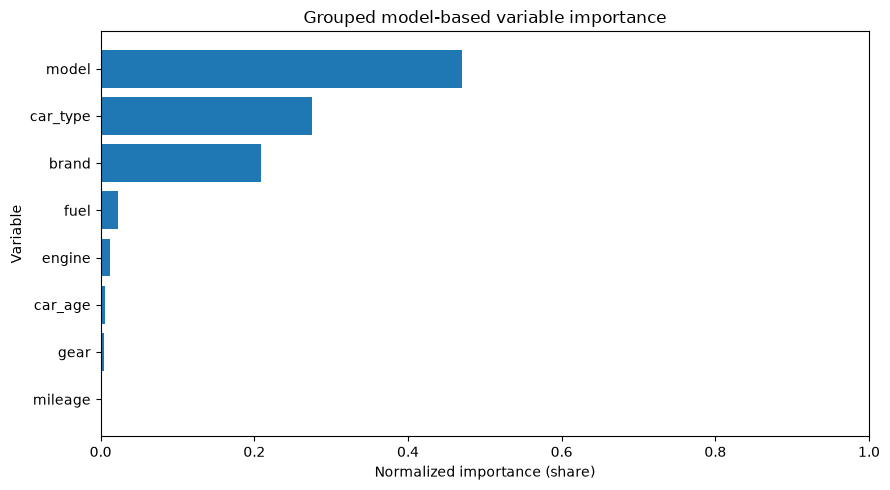

In [42]:
# [42] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร
# ==================================================
# ทำอะไร: รวม impurity หรือ gain ของ dummy กลับเป็นแปดตัวแปรและ normalize ให้รวมเป็นหนึ่ง
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ใช้ผู้ชนะที่ fit บน train แล้ว; gain ขอผ่าน booster อย่างชัดเจน; ระดับมากอาจได้เปรียบ
# ==================================================
print("=== [42] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร ===")

fitted_model = importance_estimator.named_steps["model"]
if isinstance(fitted_model, TransformedTargetRegressor):
    fitted_model = fitted_model.regressor_
encoded_names = importance_estimator.named_steps["encode"].get_feature_names_out()
if MODEL_NAME == "XGB":
    # ขอ gain อย่างชัดเจนและจับคู่ชื่อตามลำดับจริงของ encoder (รองรับทั้งชื่อจริงและ f0, f1)
    booster = fitted_model.get_booster()
    gains = booster.get_score(importance_type="gain")
    booster_names = booster.feature_names
    if booster_names is None:
        booster_names = [f"f{i}" for i in range(len(encoded_names))]
    else:
        assert booster_names == list(encoded_names), "Booster feature order differs from encoder output"
    assert len(booster_names) == len(encoded_names)
    assert set(gains).issubset(booster_names), "Unknown booster feature name"
    weights = np.asarray([gains.get(name, 0.0) for name in booster_names], dtype=float)
else:
    weights = np.asarray(fitted_model.feature_importances_, dtype=float)
assert len(weights) == len(encoded_names)
grouped_importance = {name: 0.0 for name in features}
for encoded_name, weight in zip(encoded_names, weights):
    original_name = str(encoded_name).split("=", 1)[0]
    assert original_name in grouped_importance, f"Unknown encoded variable: {encoded_name}"
    grouped_importance[original_name] += float(weight)
total_weight = sum(grouped_importance.values())
assert total_weight > 0, "โมเดลไม่มีความสำคัญที่เป็นบวกให้ normalize"
grouped_importance = {name: weight / total_weight for name, weight in grouped_importance.items()}
assert np.isclose(sum(grouped_importance.values()), 1.0)
model_importance_table = pd.DataFrame({"variable": features,
    "model_based": [grouped_importance[name] for name in features]}).sort_values("model_based", ascending=False, kind="stable")
print("Model-based importance: gain (XGB) or mean decrease of impurity (DT/RF)")
print(model_importance_table.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
display(model_importance_table)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(model_importance_table["variable"], model_importance_table["model_based"])
ax.invert_yaxis()
ax.set(xlabel="Normalized importance (share)", ylabel="Variable", title="Grouped model-based variable importance")
ax.set_xlim(*SHARE_AXIS)
plt.tight_layout()
plt.show()
if (model_importance_table["model_based"].min() < SHARE_AXIS[0]
        or model_importance_table["model_based"].max() > SHARE_AXIS[1]):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (model importance) ให้ขยาย SHARE_AXIS ในเซลล์ [03]")


In [43]:
# [43] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON
# ==================================================
# ทำอะไร: แสดงความสำคัญและอันดับทั้งสองวิธีเคียงกันแล้วพิมพ์ JSON หนึ่งบรรทัด
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: เมื่อผลสองวิธีขัดกันควรเชื่อ permutation บนข้อมูลที่ไม่เคยเห็นมากกว่า
# ==================================================
print("=== [43] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON ===")

# impurity/gain เอนเอียงไปหาตัวแปรที่มีหลายระดับ เช่น model ซึ่งมี dummy หลายร้อยตัว และคำนวณจากแถวฝึก
# permutation วัดว่า error เพิ่มบนแถวที่ไม่เคยเห็นเท่าใด เมื่อสองวิธีขัดกันควรเชื่อ permutation มากกว่า
importance_comparison = permutation_table.merge(model_importance_table, on="variable", validate="one_to_one")
importance_comparison["permutation rank"] = importance_comparison["mean"].rank(method="min", ascending=False).astype(int)
importance_comparison["model rank"] = importance_comparison["model_based"].rank(method="min", ascending=False).astype(int)
importance_comparison = importance_comparison[["variable", "mean", "std", "share (%)", "permutation rank", "model_based", "model rank"]]
print(importance_comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(importance_comparison)
print("IMPORTANCE_JSON=" + json.dumps({
    "run_id": RUN_ID,
    "permutation": {row["variable"]: {"mean": float(row["mean"]), "std": float(row["std"])}
                    for _, row in permutation_table.iterrows()},
    "model_based": grouped_importance,
}, allow_nan=False))


=== [43] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON ===
variable        mean       std  share (%)  permutation rank  model_based  model rank
 car_age 119873.9156 2039.6061    28.2785                 1       0.0058           6
  engine 116638.7906 1220.7740    27.5153                 2       0.0119           5
car_type  55719.5328  761.8673    13.1443                 3       0.2752           2
   brand  46878.2070  581.8367    11.0587                 4       0.2090           3
   model  34656.3297  445.5606     8.1755                 5       0.4704           1
    fuel  21473.0750  514.3557     5.0655                 6       0.0224           4
 mileage  21026.6594  779.5182     4.9602                 7       0.0005           8
    gear   7638.7746  288.5228     1.8020                 8       0.0047           7


,variable,mean,std,share (%),permutation rank,model_based,model rank
0,car_age,119873.915625,2039.606063,28.278467,1,0.005817,6
1,engine,116638.790625,1220.774002,27.515295,2,0.011856,5
2,car_type,55719.532813,761.867292,13.144335,3,0.275220,2
3,brand,46878.207031,581.836688,11.058651,4,0.208990,3
4,model,34656.329688,445.560560,8.175489,5,0.470441,1
5,fuel,21473.075000,514.355733,5.065536,6,0.022408,4
6,mileage,21026.659375,779.518236,4.960226,7,0.000540,8
7,gear,7638.774609,288.522787,1.802000,8,0.004728,7


IMPORTANCE_JSON={"run_id": "XGB_merge50minC", "permutation": {"car_age": {"mean": 119873.915625, "std": 2039.606062526038}, "engine": {"mean": 116638.790625, "std": 1220.7740015263817}, "car_type": {"mean": 55719.5328125, "std": 761.8672922295839}, "brand": {"mean": 46878.20703125, "std": 581.8366881944846}, "model": {"mean": 34656.3296875, "std": 445.56055958019664}, "fuel": {"mean": 21473.075, "std": 514.3557326092214}, "mileage": {"mean": 21026.659375, "std": 779.518236333421}, "gear": {"mean": 7638.774609375, "std": 288.522787326955}}, "model_based": {"engine": 0.011856173046711724, "mileage": 0.0005398827814822134, "car_age": 0.005816992576300326, "brand": 0.20899027524074007, "model": 0.4704411173011849, "car_type": 0.2752195439481654, "fuel": 0.02240832106376223, "gear": 0.004727694041653138}}
